In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


In [1]:
import torch
import numpy as np
from qasp import * 
import qasp
from pennylane import numpy as np
import pennylane as qml




In [2]:
n_qubits=16

fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

def SU4(a,b,l):
    if l==0:
        return ["Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "XX {} {}".format(a,b), "YY {} {}".format(a,b) , "ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]
    else:

        return ["ZZ {} {}".format(a,b), "Y {}".format(a), "Y {}".format(b), "Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b)]


def nn(a,b,l,c):
    if l==True:
        return ["Z {}".format(a), "Z {}".format(b), "Y {}".format(a), "Y {}".format(b), "ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
    else:

        if c:
            #return ["ZZ {} {}".format(a,b), "YY {} {}".format(a,b)]
            return ["YY {} {}".format(a,b)]
        else:
            return ["ZZ {} {}".format(a,b)]
'''
rotation_list = ["Y {}".format(i) for i in range(n_qubits)]
qubit_list = list(range(n_qubits))
orig = n_qubits
for i in range(n_qubits):
        rotation_list += ["Z {}".format(i)]
while len(qubit_list) >= 2:

    
    for i in range(0,len(qubit_list)-1,2):
        rotation_list += nn(qubit_list[i], qubit_list[i+1],False,0)
    for i in range(1,len(qubit_list)-1,2):
        rotation_list += nn(qubit_list[i], qubit_list[i+1],False,1)

    qubit_list.pop(0)
    qubit_list.pop(-1)

#rotation_list += rotation_list[::-1]
'''
ansatz_config = {
    "n_layers": 1,
    #"rotations" : "ZY",
    "imprimitive_pattern": "all_to_all",
    "reuploading": True,
    #"include_imprimitive": True,
    #"imprimitive": "CNOT",
    #"imprimitive_pattern": "chain"
}

policy_model_config = {
    "ansatz": "IQPAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    #"init": "random_-pi_pi",
    #"init": "constant",
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    #"device": "default.tensor",
    #"device": "lightning.pp",
    #"device": "default.tensor",
    #"diff_method": "adjoint",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    #"training_method": "probs",
    "torchrl": False,
    "measurement_qubits": [i for i in range(0,n_qubits,2)],
    #"measurement_qubits": [0,1,2,3],
    #"shots": int(n_qubits**(2)),
    "pp_truncation": 4, # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
    "parity_cnot_decomposition": True
}


policy_model = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy_model,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

#state = torch.zeros(n_qubits)

#pi2 = policy2.forward(state).detach().numpy()
#print(pi2)m


In [ ]:
algo = REINFORCE(
    policy        = policy_model,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 10,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 26.0
Episode 0020 | avg(return_last20) = 27.4
Episode 0030 | avg(return_last20) = 24.8
Episode 0040 | avg(return_last20) = 20.9
Episode 0050 | avg(return_last20) = 23.1
Episode 0060 | avg(return_last20) = 24.2
Episode 0070 | avg(return_last20) = 21.4
Episode 0080 | avg(return_last20) = 20.9


KeyboardInterrupt: 

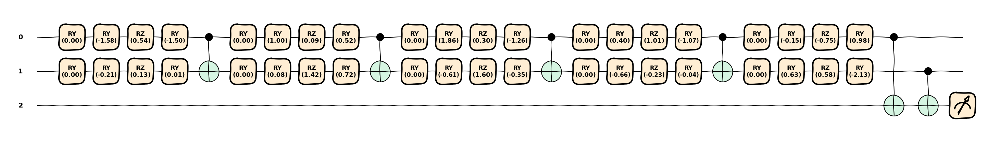

In [ ]:
n_qubits = 2
fm_config = {
    "features": 4,
    "rotations": "Y",
    #"input_scaling": False
}

ansatz_config = {
    "n_layers": 5,
    "rotations" : "YZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    #"rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": True,
    "include_imprimitive": True,
    "imprimitive": "CNOT",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [0,3,6,9,12,15,18],
    #"shots": int(n_qubits**(2))
    "parity_cnot_decomposition": True,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(model=policy1,policy_class="PQCBorn", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 22.1
Episode 0020 | avg(return_last20) = 25.4
Episode 0030 | avg(return_last20) = 21.1
Episode 0040 | avg(return_last20) = 14.2


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x1059574f0>>
Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


In [1]:
from qasp import * 
from pennylane import numpy as np
import pennylane as qml
import torch

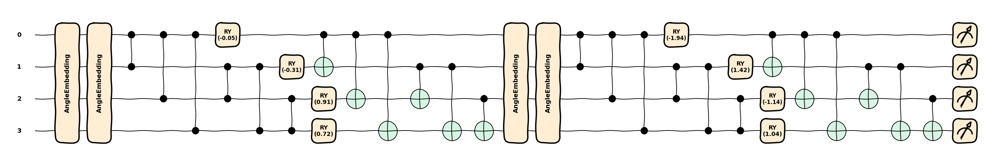

In [29]:
n_qubits = 4
fm_config = {
    "features": 4,
    "rotations": "YZ",
    "imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    "imprimitive": "CZ",
    "input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : ["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": True,
    "include_imprimitive": True,
    "imprimitive": "CNOT", #"CZ"
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding", #NeuralEmbedding
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 16.5
Episode 0020 | avg(return_last20) = 16.2
Episode 0030 | avg(return_last20) = 19.1
Episode 0040 | avg(return_last20) = 28.8
Episode 0050 | avg(return_last20) = 37.6
Episode 0060 | avg(return_last20) = 42.9
Episode 0070 | avg(return_last20) = 50.7
Episode 0080 | avg(return_last20) = 66.5
Episode 0090 | avg(return_last20) = 70.0
Episode 0100 | avg(return_last20) = 67.9
Episode 0110 | avg(return_last20) = 62.3
Episode 0120 | avg(return_last20) = 48.1
Episode 0130 | avg(return_last20) = 44.0
Episode 0140 | avg(return_last20) = 40.4
Episode 0150 | avg(return_last20) = 42.3
Episode 0160 | avg(return_last20) = 48.5
Episode 0170 | avg(return_last20) = 54.0
Episode 0180 | avg(return_last20) = 50.1
Episode 0190 | avg(return_last20) = 54.2
Episode 0200 | avg(return_last20) = 56.6
Episode 0210 | avg(return_last20) = 48.2
Episode 0220 | avg(return_last20) = 66.0
Episode 0230 | avg(return_last20) = 71.0
Episode 0240 | avg(return_last20) = 66.0
Episode 0250 | a

KeyboardInterrupt: 

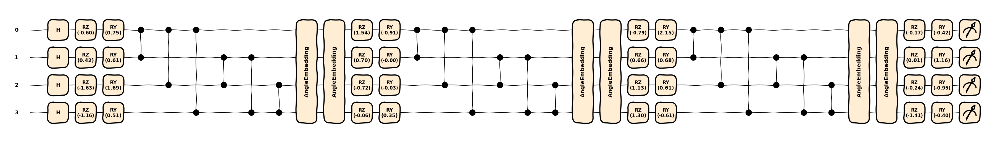

In [ ]:
n_qubits = 4
fm_config = {
    "features": 4,
    "rotations": "YZ",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    "input_scaling": True
}

ansatz_config = {
    "n_layers": 4,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": True,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 18.1
Episode 0020 | avg(return_last20) = 16.5
Episode 0030 | avg(return_last20) = 21.1
Episode 0040 | avg(return_last20) = 25.1
Episode 0050 | avg(return_last20) = 23.8
Episode 0060 | avg(return_last20) = 23.6
Episode 0070 | avg(return_last20) = 22.8
Episode 0080 | avg(return_last20) = 20.6
Episode 0090 | avg(return_last20) = 20.2
Episode 0100 | avg(return_last20) = 25.9
Episode 0110 | avg(return_last20) = 33.0
Episode 0120 | avg(return_last20) = 30.3
Episode 0130 | avg(return_last20) = 30.1
Episode 0140 | avg(return_last20) = 42.1
Episode 0150 | avg(return_last20) = 58.2
Episode 0160 | avg(return_last20) = 69.6
Episode 0170 | avg(return_last20) = 69.8
Episode 0180 | avg(return_last20) = 67.7
Episode 0190 | avg(return_last20) = 58.8
Episode 0200 | avg(return_last20) = 49.9


KeyboardInterrupt: 

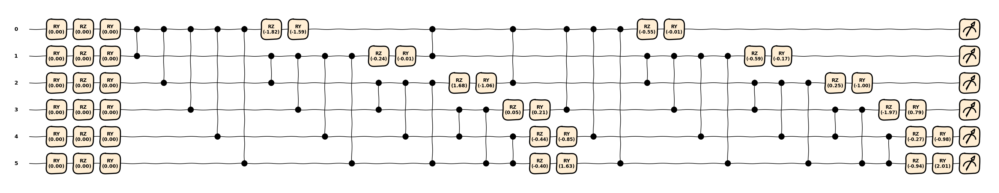

In [ ]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "YZY",
    "imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    "imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
        "include_final_imprimitive": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 26.7
Episode 0020 | avg(return_last20) = 26.4
Episode 0030 | avg(return_last20) = 22.5
Episode 0040 | avg(return_last20) = 19.4
Episode 0050 | avg(return_last20) = 20.1
Episode 0060 | avg(return_last20) = 20.4
Episode 0070 | avg(return_last20) = 21.4
Episode 0080 | avg(return_last20) = 21.2
Episode 0090 | avg(return_last20) = 23.4
Episode 0100 | avg(return_last20) = 36.1
Episode 0110 | avg(return_last20) = 50.5
Episode 0120 | avg(return_last20) = 47.1
Episode 0130 | avg(return_last20) = 42.6
Episode 0140 | avg(return_last20) = 39.6
Episode 0150 | avg(return_last20) = 31.9
Episode 0160 | avg(return_last20) = 27.6
Episode 0170 | avg(return_last20) = 23.5
Episode 0180 | avg(return_last20) = 23.6
Episode 0190 | avg(return_last20) = 22.4
Episode 0200 | avg(return_last20) = 22.6
Episode 0210 | avg(return_last20) = 24.6


KeyboardInterrupt: 

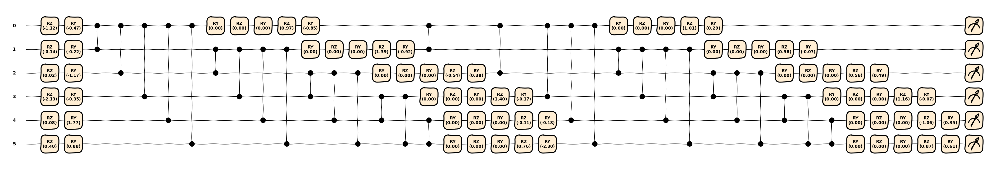

In [ ]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": True,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
        "include_final_imprimitive": False,
    "include_feature_map_first": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 21.0
Episode 0020 | avg(return_last20) = 26.1
Episode 0030 | avg(return_last20) = 31.9
Episode 0040 | avg(return_last20) = 34.0
Episode 0050 | avg(return_last20) = 38.4
Episode 0060 | avg(return_last20) = 37.3
Episode 0070 | avg(return_last20) = 35.3
Episode 0080 | avg(return_last20) = 35.0
Episode 0090 | avg(return_last20) = 33.1
Episode 0100 | avg(return_last20) = 26.4
Episode 0110 | avg(return_last20) = 20.4
Episode 0120 | avg(return_last20) = 27.2
Episode 0130 | avg(return_last20) = 32.2
Episode 0140 | avg(return_last20) = 28.3
Episode 0150 | avg(return_last20) = 27.9
Episode 0160 | avg(return_last20) = 27.4
Episode 0170 | avg(return_last20) = 27.6


Exception ignored in: <bound method IPythonKernel._clean_thread_parent_frames of <ipykernel.ipkernel.IPythonKernel object at 0x105eab4f0>>
Traceback (most recent call last):
  File "/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/ipykernel/ipkernel.py", line 781, in _clean_thread_parent_frames
    def _clean_thread_parent_frames(
KeyboardInterrupt: 


Episode 0180 | avg(return_last20) = 40.4
Episode 0190 | avg(return_last20) = 42.8


KeyboardInterrupt: 

In [1]:
import matplotlib.pyplot as plt
import qasp
from qasp import *
import torch

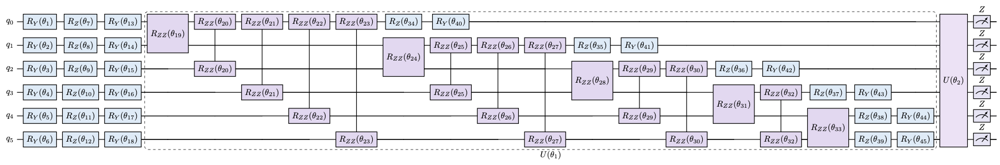

In [2]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : ["ZZ {} {}".format(i,j) for i in range(n_qubits-1) for j in range(i+1 , n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
        "include_final_imprimitive": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)

from pathlib import Path
import shutil
import subprocess
from IPython.display import Image, display

output_dir = Path.cwd() / "tikz_output"
output_dir.mkdir(exist_ok=True)

tex_path = output_dir / "policy_circuit.tex"
pdf_path = output_dir / "policy_circuit.pdf"
png_path = output_dir / "policy_circuit.png"

tikz = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
    output="tikz",
    tikz_options={
        "symbolic_parameters": True,
        "standalone": True,
        "compress": True,
        "max_explicit_layers": 4,
        "gate_colors": {
            "single": "DCECF8",
            "two": "E4D8F2",
            "multi": "EEE2F7",
            "measurement": "E8E5F5",
        },
    },
)

# Confirms that the updated colored exporter is loaded.
assert r"\definecolor{qaspSingleGate}" in tikz

# Save the NEW TikZ.
tex_path.write_text(tikz, encoding="utf-8")

# Compile the NEW TikZ into a PDF.
pdflatex = shutil.which("pdflatex")
if pdflatex is None:
    raise RuntimeError("pdflatex was not found")

subprocess.run(
    [
        pdflatex,
        "-interaction=nonstopmode",
        "-halt-on-error",
        tex_path.name,
    ],
    cwd=output_dir,
    check=True,
    capture_output=True,
    text=True,
)

# Convert the newly generated PDF.
subprocess.run(
    [
        "/usr/bin/sips",
        "-s", "format", "png",
        "-Z", "1800",
        pdf_path.name,
        "--out", png_path.name,
    ],
    cwd=output_dir,
    check=True,
    capture_output=True,
    text=True,
)

# Reading the bytes prevents Jupyter/browser filename caching.
display(Image(data=png_path.read_bytes()))

In [4]:
fig

'% Requires \\usepackage{quantikz}\n\\begin{quantikz}[row sep=0.35cm, column sep=0.25cm]\n\\lstick{$q_{0}$} & \\gate{R_{Y}(\\theta_{1})} & \\gate{R_{Z}(\\theta_{7})} & \\gate{R_{Y}(\\theta_{13})} & \\gate[wires=2]{R_{ZZ}(\\theta_{19})} & \\gate{R_{ZZ}(\\theta_{20})}\\vqw{2} & \\gate{R_{ZZ}(\\theta_{21})}\\vqw{3} & \\gate{R_{ZZ}(\\theta_{22})}\\vqw{4} & \\gate{R_{ZZ}(\\theta_{23})}\\vqw{5} & \\gate{R_{Z}(\\theta_{34})} & \\gate{R_{Y}(\\theta_{40})} & \\qw & \\qw & \\qw & \\qw & \\gate[wires=2]{R_{ZZ}(\\theta_{46})} & \\qw & \\qw & \\gate{R_{ZZ}(\\theta_{47})}\\vqw{2} & \\qw & \\gate{R_{ZZ}(\\theta_{48})}\\vqw{3} & \\gate{R_{ZZ}(\\theta_{49})}\\vqw{4} & \\gate{R_{ZZ}(\\theta_{50})}\\vqw{5} & \\gate{R_{Z}(\\theta_{61})} & \\gate{R_{Y}(\\theta_{67})} & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\qw & \\meter{\\langle Z\\otimes Z\\otimes Z\\otimes Z\\otimes Z\\otimes Z\\rangle} & \\qw \\\\\n\\lstick{$q_{1}$} & \\gate{R_{Y}(\\theta_{2})} & \\gate{R_{Z}(\\theta_{8})} & \\

In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = "CartPole-v1",
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 21.5
Episode 0020 | avg(return_last20) = 21.1
Episode 0030 | avg(return_last20) = 20.5
Episode 0040 | avg(return_last20) = 23.2
Episode 0050 | avg(return_last20) = 24.8
Episode 0060 | avg(return_last20) = 28.1
Episode 0070 | avg(return_last20) = 39.9
Episode 0080 | avg(return_last20) = 42.8
Episode 0090 | avg(return_last20) = 39.4
Episode 0100 | avg(return_last20) = 37.5
Episode 0110 | avg(return_last20) = 36.2
Episode 0120 | avg(return_last20) = 45.1
Episode 0130 | avg(return_last20) = 45.4
Episode 0140 | avg(return_last20) = 44.3
Episode 0150 | avg(return_last20) = 45.6
Episode 0160 | avg(return_last20) = 48.1
Episode 0170 | avg(return_last20) = 64.5
Episode 0180 | avg(return_last20) = 76.5
Episode 0190 | avg(return_last20) = 70.8
Episode 0200 | avg(return_last20) = 53.2
Episode 0210 | avg(return_last20) = 42.0
Episode 0220 | avg(return_last20) = 33.3
Episode 0230 | avg(return_last20) = 30.1
Episode 0240 | avg(return_last20) = 28.6
Episode 0250 | a

In [ ]:
import pickle 

if __name__ == "__main__":
    # Loading the environment
    with open('contextual_bandit_env0.pkl', 'rb') as f:
        env = pickle.load(f)

    optimal_actions, max_p, probs = env.get_optimal_action(0, return_probs=True)
    print("True Optimal Action(s):", optimal_actions)
    print("Probabilities:", probs)


True Optimal Action(s): [35]
Probabilities: [0.43451999 0.57003539 0.75121871 0.45130323 0.39998552 0.78003242
 0.4988584  0.44663635 0.85179128 0.58235932 0.44659913 0.27607595
 0.78977191 0.61156409 0.80893672 0.42493834 0.81032629 0.65063525
 0.56325392 0.31824429 0.67897276 0.21398765 0.77221385 0.49363348
 0.62365036 0.54024516 0.34938738 0.74855043 0.10738853 0.68140277
 0.72802038 0.73375174 0.81071742 0.30202568 0.20621286 0.89508606]





In [ ]:
n_qubits = 12
fm_config = {
    "features": 2,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 2,
    "rotations" : ["ZZ {} {}".format(i,j) for i in range(n_qubits-1) for j in range(i+1,n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": False,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
        "include_final_imprimitive": False
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 36,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(2),
)


In [ ]:
algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = env,
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 1.4
Episode 0020 | avg(return_last20) = 1.6
Episode 0030 | avg(return_last20) = 2.6
Episode 0040 | avg(return_last20) = 3.0
Episode 0050 | avg(return_last20) = 3.6
Episode 0060 | avg(return_last20) = 3.7
Episode 0070 | avg(return_last20) = 3.1
Episode 0080 | avg(return_last20) = 3.6
Episode 0090 | avg(return_last20) = 2.8
Episode 0100 | avg(return_last20) = 2.4
Episode 0110 | avg(return_last20) = 2.8
Episode 0120 | avg(return_last20) = 2.2
Episode 0130 | avg(return_last20) = 2.3
Episode 0140 | avg(return_last20) = 3.0
Episode 0150 | avg(return_last20) = 3.3
Episode 0160 | avg(return_last20) = 7.7
Episode 0170 | avg(return_last20) = 7.8
Episode 0180 | avg(return_last20) = 3.5
Episode 0190 | avg(return_last20) = 3.2
Episode 0200 | avg(return_last20) = 2.3
Episode 0210 | avg(return_last20) = 2.2
Episode 0220 | avg(return_last20) = 7.7
Episode 0230 | avg(return_last20) = 8.5
Episode 0240 | avg(return_last20) = 3.8
Episode 0250 | avg(return_last20) = 2.4


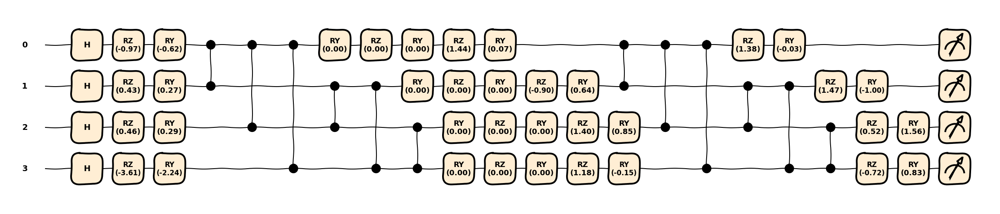

In [ ]:
n_qubits = 4
fm_config = {
    "features": 4,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
cfg = ReinforceConfig(
        env_name          = "CartPole-v1",
        n_episodes        = 2000,
        n_batch           = 4,
        gamma             = 0.99,
        lr_policy         = 0.1,
        entropy_coef      = 0.01,
        grad_clip         = 1.0,
        normalise_state   = False,
        log_every         = 1,
        eval_every        = 50,
        # ── Baseline: pick one ──────────────────────────────────────────────
        baseline_type     = "mean_return",  # simple EMA of episode returns
        baseline_momentum = 0.05,           # EMA smoothing (ignored for "mlp")
        # baseline_type  = "mlp",           # state-dependent classical network
        # lr_baseline    = 1e-3,            # learning rate for mlp baseline
    )

trainer = Reinforce(policy1, config=cfg)
results = trainer.train()


  REINFORCE  |  env=CartPole-v1
  batch=4  gamma=0.99  entropy_coef=0.01
  baseline=mean_return  momentum=0.05
  lr_policy=0.1  grad_clip=1.0
  solved at mean>=475.0 over 100 episodes

  ep=    4 | return=   34.8 | rolling=  34.75 | pi_loss=0.0007 | b=45.4 | t=6s
  ep=    8 | return=   24.8 | rolling=  29.75 | pi_loss=-0.0486 | b=41.6 | t=11s
  ep=   12 | return=   30.0 | rolling=  29.83 | pi_loss=0.0300 | b=39.5 | t=17s
  ep=   16 | return=   30.8 | rolling=  30.06 | pi_loss=-0.0386 | b=37.9 | t=23s
  ep=   20 | return=   17.2 | rolling=  27.50 | pi_loss=-0.0246 | b=34.1 | t=27s
  ep=   24 | return=   24.8 | rolling=  27.04 | pi_loss=-0.0350 | b=32.3 | t=32s
  ep=   28 | return=   15.2 | rolling=  25.36 | pi_loss=-0.0366 | b=29.1 | t=35s
  ep=   32 | return=   27.5 | rolling=  25.62 | pi_loss=-0.0036 | b=28.8 | t=39s
  ep=   36 | return=   24.0 | rolling=  25.44 | pi_loss=-0.0246 | b=27.8 | t=43s
  ep=   40 | return=   33.0 | rolling=  26.20 | pi_loss=-0.0432 | b=28.8 | t=48s
  ep=  

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
print(trainer.episode_returns)

[48.0, 33.0, 46.0, 12.0, 13.0, 42.0, 25.0, 19.0, 43.0, 11.0, 26.0, 40.0, 18.0, 40.0, 40.0, 25.0, 14.0, 12.0, 21.0, 22.0, 14.0, 58.0, 8.0, 19.0, 13.0, 18.0, 14.0, 16.0, 44.0, 10.0, 33.0, 23.0, 33.0, 23.0, 25.0, 15.0, 21.0, 40.0, 44.0, 27.0, 14.0, 10.0, 21.0, 72.0, 19.0, 22.0, 29.0, 28.0, 29.0, 23.0, 23.0, 34.0, 24.0, 65.0, 22.0, 30.0, 20.0, 53.0, 26.0, 17.0, 84.0, 31.0, 27.0, 25.0, 37.0, 33.0, 26.0, 45.0, 51.0, 20.0, 24.0, 17.0, 14.0, 35.0, 32.0, 38.0, 37.0, 17.0, 10.0, 24.0, 29.0, 26.0, 32.0, 20.0, 19.0, 33.0, 37.0, 29.0, 9.0, 38.0, 51.0, 31.0, 28.0, 42.0, 38.0, 16.0, 23.0, 31.0, 101.0, 79.0, 27.0, 32.0, 17.0, 51.0, 26.0, 31.0, 20.0, 28.0, 28.0, 38.0, 10.0, 25.0, 14.0, 24.0, 17.0, 17.0, 20.0, 76.0, 17.0, 12.0, 62.0, 18.0, 45.0, 45.0, 18.0, 18.0, 32.0, 17.0, 30.0, 16.0, 35.0, 29.0, 13.0, 16.0, 56.0, 32.0, 59.0, 103.0, 22.0, 57.0, 54.0, 23.0, 74.0, 36.0, 64.0, 14.0, 12.0, 42.0, 62.0, 57.0, 40.0, 22.0, 65.0, 43.0, 42.0, 42.0, 32.0, 32.0, 14.0, 29.0, 37.0, 36.0, 23.0, 56.0, 109.0, 26.0, 56

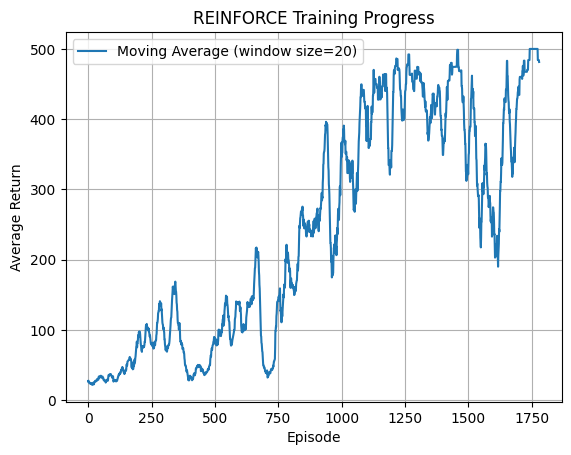

In [ ]:
#plot moving average of episode returns
window_size = 20

moving_avg = np.convolve(trainer.episode_returns, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



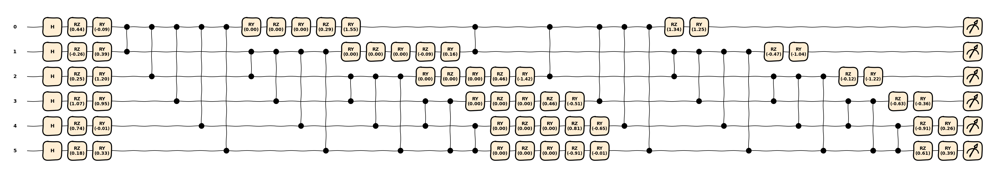

In [ ]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
cfg = qasp.rl.torchrl.ReinforceConfig(
        env_name          = "CartPole-v1",
        n_episodes        = 2000,
        n_batch           = 4,
        gamma             = 0.99,
        lr_policy         = 0.1,
        entropy_coef      = 0.01,
        grad_clip         = 1.0,
        normalise_state   = False,
        log_every         = 1,
        eval_every        = 50,
        # ── Baseline: pick one ──────────────────────────────────────────────
        baseline_type     = "mean_return",  # simple EMA of episode returns
        baseline_momentum = 0.05,           # EMA smoothing (ignored for "mlp")
        # baseline_type  = "mlp",           # state-dependent classical network
        # lr_baseline    = 1e-3,            # learning rate for mlp baseline
    )

trainer = qasp.rl.torchrl.Reinforce(policy1, config=cfg)
results = trainer.train()


  REINFORCE  |  env=CartPole-v1
  batch=4  gamma=0.99  entropy_coef=0.01
  baseline=mean_return  momentum=0.05
  lr_policy=0.1  grad_clip=1.0
  solved at mean>=475.0 over 100 episodes

  ep=    4 | return=   22.8 | rolling=  22.75 | pi_loss=-0.0201 | b=31.1 | t=5s
  ep=    8 | return=   31.2 | rolling=  27.00 | pi_loss=0.0004 | b=31.0 | t=11s
  ep=   12 | return=   23.2 | rolling=  25.75 | pi_loss=0.0053 | b=29.4 | t=15s
  ep=   16 | return=   26.8 | rolling=  26.00 | pi_loss=-0.0189 | b=29.1 | t=21s
  ep=   20 | return=   28.5 | rolling=  26.50 | pi_loss=-0.0482 | b=28.9 | t=27s
  ep=   24 | return=   25.0 | rolling=  26.25 | pi_loss=-0.0078 | b=28.0 | t=34s
  ep=   28 | return=   22.0 | rolling=  25.64 | pi_loss=-0.0373 | b=26.9 | t=39s
  ep=   32 | return=   13.5 | rolling=  24.12 | pi_loss=-0.0071 | b=24.4 | t=41s
  ep=   36 | return=   17.5 | rolling=  23.39 | pi_loss=-0.0092 | b=23.1 | t=45s
  ep=   40 | return=   19.8 | rolling=  23.02 | pi_loss=0.0388 | b=22.5 | t=48s
  ep=   




In [ ]:
n_qubits = 12
fm_config = {
    "features": 2,
    "rotations": "YZY",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 36,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    # "shots": int(n_qubits**(2))
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=2,
    inputs=torch.zeros(2),
)


In [ ]:
import pickle 

if __name__ == "__main__":
    # Loading the environment
    with open('contextual_bandit_env0.pkl', 'rb') as f:
        env = pickle.load(f)

    optimal_actions, max_p, probs = env.get_optimal_action(0, return_probs=True)
    print("True Optimal Action(s):", optimal_actions)
    print("Probabilities:", probs)

algo = REINFORCE(
    policy        = policy1,         # your PQCBorn
    env_name      = env,
    gamma         = 0.99,
    lr            = 1e-1,
    batch_episodes= 5,
    logits        = False              # set True if action_logits returns logits
)


True Optimal Action(s): [35]
Probabilities: [0.43451999 0.57003539 0.75121871 0.45130323 0.39998552 0.78003242
 0.4988584  0.44663635 0.85179128 0.58235932 0.44659913 0.27607595
 0.78977191 0.61156409 0.80893672 0.42493834 0.81032629 0.65063525
 0.56325392 0.31824429 0.67897276 0.21398765 0.77221385 0.49363348
 0.62365036 0.54024516 0.34938738 0.74855043 0.10738853 0.68140277
 0.72802038 0.73375174 0.81071742 0.30202568 0.20621286 0.89508606]


In [ ]:
returns = algo.train(num_episodes=500)


Episode 0010 | avg(return_last20) = 3.8
Episode 0020 | avg(return_last20) = 3.0
Episode 0030 | avg(return_last20) = 2.0
Episode 0040 | avg(return_last20) = 2.4
Episode 0050 | avg(return_last20) = 2.2
Episode 0060 | avg(return_last20) = 1.7
Episode 0070 | avg(return_last20) = 2.7
Episode 0080 | avg(return_last20) = 3.6
Episode 0090 | avg(return_last20) = 3.7
Episode 0100 | avg(return_last20) = 3.1
Episode 0110 | avg(return_last20) = 2.6
Episode 0120 | avg(return_last20) = 7.1
Episode 0130 | avg(return_last20) = 12.1
Episode 0140 | avg(return_last20) = 7.8
Episode 0150 | avg(return_last20) = 2.7
Episode 0160 | avg(return_last20) = 7.6
Episode 0170 | avg(return_last20) = 13.0
Episode 0180 | avg(return_last20) = 8.3
Episode 0190 | avg(return_last20) = 2.7
Episode 0200 | avg(return_last20) = 2.5
Episode 0210 | avg(return_last20) = 3.7
Episode 0220 | avg(return_last20) = 3.4
Episode 0230 | avg(return_last20) = 2.0
Episode 0240 | avg(return_last20) = 6.1
Episode 0250 | avg(return_last20) = 12

In [ ]:
from qasp import * 
import matplotlib.pyplot as plt

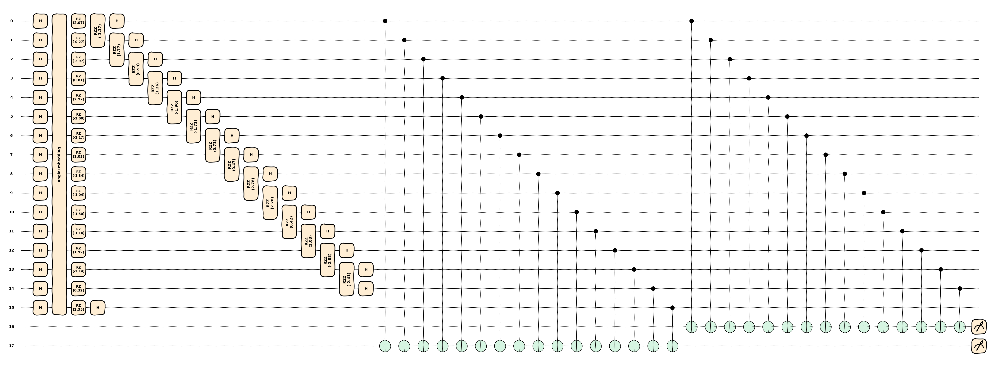

In [ ]:
n_qubits = 16
fm_config = {
    "features": n_qubits,
    "rotations": "Z",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 1,
    "imprimitive_pattern" : [(i,i+1) for i in range(n_qubits-2)],
    # "rotations" : ["YY {} {}".format(i, i+1) for i in range(0,n_qubits-1,2)]+["YYY {} {} {}".format(i, i+1, i+2) for i in range(0,n_qubits-2,3)] + ["YYYY {} {} {} {}".format(i, i+1, i+2, i+3) for i in range(0,n_qubits-3,4)],
    "reuploading": False,
    #"include_imprimitive": True,
    #"imprimitive": "CZ",
    #"imprimitive_pattern": "all_to_all",
    #"include_final_imprimitive": False,
    #"include_feature_map_first": False,
    #"include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "IQPAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    #"init": "normal_0_1",
    "init": "random_-pi_pi",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "probs",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    "shots": n_qubits**(2),
    "parity_cnot_decomposition": True,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=n_qubits,
    inputs=torch.zeros(n_qubits),
)


In [ ]:
steps = 500
state = torch.zeros(n_qubits)

optimizer = torch.optim.Adam(policy1.parameters(), lr=0.1)

probs_list=[]
losses=[]
for step in range(steps):
    probs = policy1.forward(state)
    loss = -torch.log(probs[-1]) # assuming action 0 is the optimal action for this state
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    print(f"Step {step+1}/{steps}, probs: {probs.detach().numpy()}")
    probs_list.append(probs.detach().numpy())
    losses.append(loss.item())



Step 1/500, probs: [0.09375    0.4140625  0.40234375 0.08984375]
Step 2/500, probs: [0.11328125 0.4140625  0.390625   0.08203125]
Step 3/500, probs: [0.12109375 0.3671875  0.3828125  0.12890625]
Step 4/500, probs: [0.1015625  0.3828125  0.38671875 0.12890625]
Step 5/500, probs: [0.16015625 0.35546875 0.3515625  0.1328125 ]
Step 6/500, probs: [0.16796875 0.25390625 0.3671875  0.2109375 ]
Step 7/500, probs: [0.19921875 0.31640625 0.29296875 0.19140625]
Step 8/500, probs: [0.24609375 0.30859375 0.20703125 0.23828125]
Step 9/500, probs: [0.26171875 0.2578125  0.2578125  0.22265625]
Step 10/500, probs: [0.234375   0.28125    0.23046875 0.25390625]
Step 11/500, probs: [0.25       0.23828125 0.25       0.26171875]
Step 12/500, probs: [0.3046875  0.1796875  0.19140625 0.32421875]
Step 13/500, probs: [0.40234375 0.1796875  0.13671875 0.28125   ]
Step 14/500, probs: [0.34375    0.12109375 0.1640625  0.37109375]
Step 15/500, probs: [0.40625    0.12890625 0.0859375  0.37890625]
Step 16/500, probs:

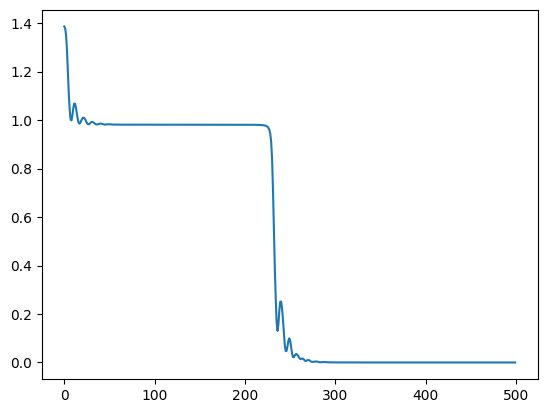

In [ ]:
plt.plot(losses)

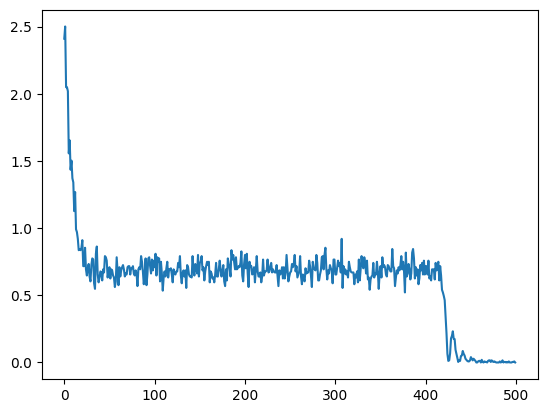

In [ ]:
plt.plot(losses)

### |A|=2

In [ ]:
print(14**2 * 200)


2**(14+1.3)

39200


40342.14013648624

Observable order:
 0: A    | weight=18 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17] | obs=ZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17

Projector expansion for action 1111:
constant: 0.5
A   : -0.5
Step 1/400, Loss: -0.4876543209876543, Prob(action 1111): 0.4876543209876543, ||grad prob 1111||: 0.13549523326698054
Step 2/400, Loss: -0.5462962962962963, Prob(action 1111): 0.5462962962962963, ||grad prob 1111||: 0.12565557398655733
Step 3/400, Loss: -0.5339506172839507, Prob(action 1111): 0.5339506172839507, ||grad prob 1111||: 0.12798411800379839
Step 4/400, Loss: -0.42901234567901236, Prob(action 1111): 0.42901234567901236, ||grad prob 1111||: 0.12176698484307942
Step 5/400, Loss: -0.4876543209876543, Prob(action 1111): 0.4876543209876543, ||grad prob 1111||: 0.11886723710896122
Step 6/400, Loss: -0.4876543209876543, Prob(action 1111): 0.4876543209876543, ||grad prob 1111||: 0.08663993115813705
Step 7/400, Loss: -0.5339506172839507, Prob(acti

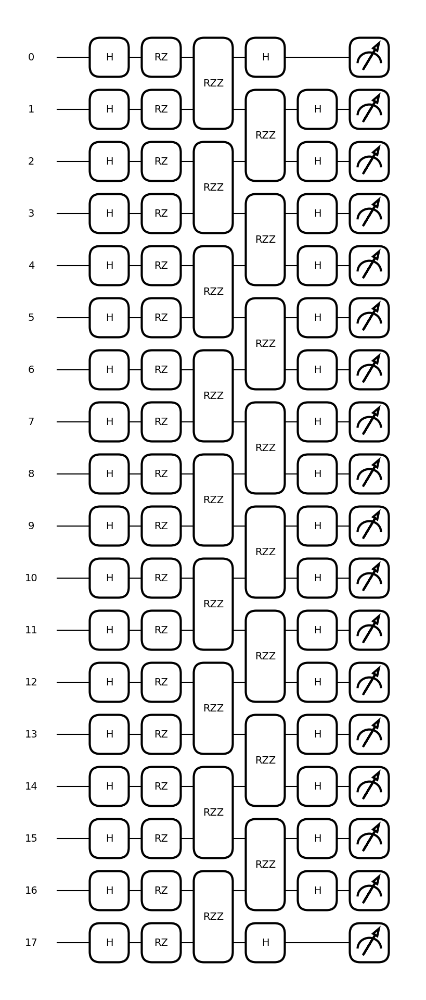

In [ ]:
from itertools import combinations
def z_string(wires):

    """

    Convert a list of wires into your QASP observable string format.

    Example:

        wires = [0, 1, 3]

        returns "ZZZ 0 1 3"

    """

    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)

def xor_product_wires(list_of_wire_sets):

    """

    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.

    This function returns the symmetric difference of all wire sets.

    """

    counts = {}

    for wires in list_of_wire_sets:

        for w in wires:

            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]

    return sorted(product_wires)

def build_parity_observables(n_qubits, n_action_bits):

    """

    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    For |A|=16, n_action_bits=4.

    We define the base parity generators:

        A = Z0 Z1 ... Z_{n-1}

        B = Z0 Z1 ... Z_{n-2}

        C = Z0 Z1 ... Z_{n-3}

        D = Z0 Z1 ... Z_{n-4}

    Then generate all products:

        A, B, C, D,

        AB, AC, AD, BC, BD, CD,

        ABC, ABD, ACD, BCD,

        ABCD.

    Returns:

        observable_labels: list[str]

        observable_wires: list[list[int]]

        observables: list[str]

        subsets: list[tuple[int]]

    """

    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    # A has n wires, B has n-1 wires, C has n-2 wires, ...

    base_wires = [

        list(range(n_qubits - i))

        for i in range(n_action_bits)

    ]

    observable_labels = []

    observable_wires = []

    observables = []

    subsets = []

    for r in range(1, n_action_bits + 1):

        for subset in combinations(range(n_action_bits), r):

            label = "".join(base_labels[i] for i in subset)

            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)

            observable_wires.append(wires)

            observables.append(z_string(wires))

            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets

def projector_coeffs_for_bits(bits, subsets):

    """

    Build the coefficients for the projector onto a target action bitstring.

    For bits = [1, 1, 1, 1], the projector is:

        Pi_1111 = (1/16)(I - A)(I - B)(I - C)(I - D)

    More generally:

        Pi_b = (1/16) prod_j (I + s_j P_j)

    where:

        s_j = +1 if bit_j = 0

        s_j = -1 if bit_j = 1

    Returns:

        constant: float

        coeffs: np.array of length 15

    """

    n_action_bits = len(bits)

    signs = [

        1 if bit == 0 else -1

        for bit in bits

    ]

    constant = 1 / (2 ** n_action_bits)

    coeffs = []

    for subset in subsets:

        coeff = 1

        for i in subset:

            coeff *= signs[i]

        coeffs.append(coeff * constant)

    return constant, np.array(coeffs)

def prob_from_expvals(expvals, bits, subsets):

    """

    Probability of the target action according to the parity-projector expansion.

    """

    constant, coeffs = projector_coeffs_for_bits(bits, subsets)

    return constant + np.dot(coeffs, expvals)

# ============================================================

# 2. Build |A| = 16 parity observables

# ============================================================

n_qubits = 18

n_action_bits = 1      # because |A| = 32

target_bits = [1]  # action 1111, i.e. action 16 in one-indexed convention

observable_labels, observable_wires, observables, subsets = build_parity_observables(

    n_qubits=n_qubits,

    n_action_bits=n_action_bits,

)

print("Observable order:")

for i, (label, wires, obs) in enumerate(zip(observable_labels, observable_wires, observables)):

    print(f"{i:2d}: {label:4s} | weight={len(wires):2d} | wires={wires} | obs={obs}")

# ============================================================

# 3. Build IQP ansatz and initialize parameters

# ============================================================

fm = None

imprimitive_pattern = (

    [(i, i + 1) for i in range(0, n_qubits - 1, 2)]

    + [(i, i + 1) for i in range(1, n_qubits - 1, 2)]

)

iqp = IQPAnsatz(

    n_qubits=n_qubits,

    imprimitive_pattern=imprimitive_pattern,

    n_layers=1,

    feature_map=fm,

    reuploading=False,

)

# Important: use the actual expected flattened parameter size.

# This avoids the earlier shape mismatch error.

expected_total = iqp.n_layers * iqp._block_size
shapes = iqp.get_param_shapes()
'''
params = np.array([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
                   
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,

         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,

         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,

        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,

        -0.79940706,  1.24272434], requires_grad=True)
'''
params = np.random.uniform(low=0, high=2*np.pi, size=shapes[0], requires_grad=True)


# ============================================================

# 4. Build and compile circuit

# ============================================================

builder = CircuitBuilder(n_qubits=n_qubits)

builder.set_ansatz(iqp)

builder.set_measurement(

    "expectation",

    observables=observables,

    wires=list(range(n_qubits)),

)

circuit = builder.build()

qtape = builder.compile(

    cut_circuit=False,

    device="lightning.kokkos",

    shots=int(round(18** 2)),

)

# Optional drawing

qml.draw_mpl(circuit)(params=params)

# ============================================================

# 5. Define cost function for action 1111

# ============================================================

def expvals_fn(params):

    return qml.math.stack(qtape(params))

def prob_action_1111_from_expvals(expvals):

    return prob_from_expvals(

        expvals=expvals,

        bits=target_bits,

        subsets=subsets,

    )

def cost_function(params):

    expvals = expvals_fn(params)

    prob = prob_action_1111_from_expvals(expvals)

    return -prob

# Print explicit coefficients for sanity check

constant, coeffs_1111 = projector_coeffs_for_bits(target_bits, subsets)

print("\nProjector expansion for action 1111:")

print("constant:", constant)

for label, coeff in zip(observable_labels, coeffs_1111):

    print(f"{label:4s}: {coeff}")

# ============================================================

# 6. Training loop with individual observable gradients

# ============================================================

opt = qml.AdamOptimizer(stepsize=0.1)

steps = 400

loss16 = []

# Dictionary: label -> list of gradient norms

grad_norms = {

    label: []

    for label in observable_labels

}

grad_prob_1111_list = []

grad_loss_1111_list = []

prob_1111_list = []

for step in range(steps):

    # Individual observable gradients.

    # Important: use idx=i to avoid Python late-binding in lambda.

    individual_grads = []

    for i, label in enumerate(observable_labels):

        grad_i = qml.grad(lambda p, idx=i: qtape(p)[idx])(params)

        individual_grads.append(grad_i)

        grad_norms[label].append(np.linalg.norm(grad_i))

    # Full probability-gradient direction from the signed combination

    grad_prob_1111 = sum(

        coeffs_1111[i] * individual_grads[i]

        for i in range(len(individual_grads))

    )

    grad_loss_1111 = -grad_prob_1111

    grad_prob_1111_list.append(np.linalg.norm(grad_prob_1111))

    grad_loss_1111_list.append(np.linalg.norm(grad_loss_1111))

    # Optimization step

    params, curr_loss = opt.step_and_cost(cost_function, params)

    curr_prob = -curr_loss

    loss16.append(curr_loss)

    prob_1111_list.append(curr_prob)

    print(

        f"Step {step + 1}/{steps}, "

        f"Loss: {curr_loss}, "

        f"Prob(action 1111): {curr_prob}, "

        f"||grad prob 1111||: {grad_prob_1111_list[-1]}"

    )


/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  global_cmap = cm.get_cmap("Reds")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  local_cmap = cm.get_cmap("Blues")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  middle_cmap

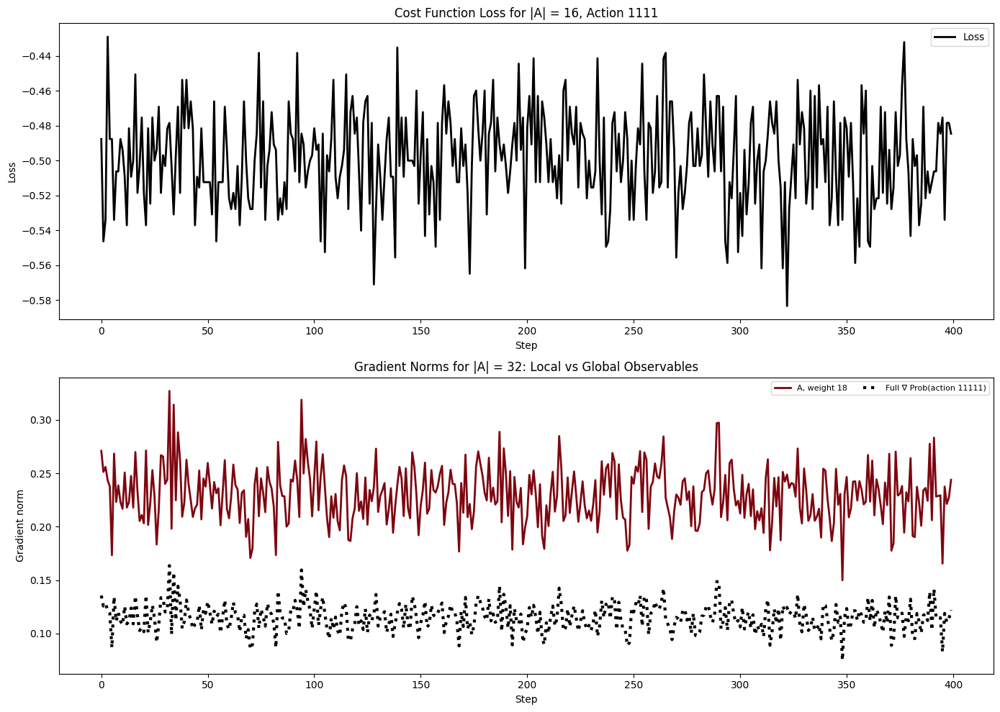

In [ ]:
# ============================================================

# 7. Plot loss and gradient norms with local/global color families

# ============================================================

# We classify by Pauli weight.

# Local: low-weight strings, e.g. 1, 2, 3, 4

# Global: high-weight strings, e.g. near n_qubits

# Intermediate: anything else, if it appears

weights = {

    label: len(wires)

    for label, wires in zip(observable_labels, observable_wires)

}

max_weight = max(weights.values())

min_weight = min(weights.values())

global_cmap = cm.get_cmap("Reds")

local_cmap = cm.get_cmap("Blues")

middle_cmap = cm.get_cmap("Purples")

def color_for_weight(weight):

    """

    Color convention:

        blue   -> local / low-weight terms

        purple -> intermediate terms

        red    -> global / high-weight terms

    """

    if weight <= 4:

        # local family

        # darker blue for larger local support

        t = 0.35 + 0.55 * (weight / 4)

        return local_cmap(t)

    elif weight >= n_qubits // 2:

        # global family

        # darker red for more global support

        t = 0.35 + 0.60 * (weight / n_qubits)

        return global_cmap(t)

    else:

        # intermediate family

        t = 0.55

        return middle_cmap(t)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Loss plot

ax1.plot(loss16, label="Loss", color="black", linewidth=2)

ax1.set_xlabel("Step")

ax1.set_ylabel("Loss")

ax1.set_title("Cost Function Loss for |A| = 16, Action 1111")

ax1.legend()

# Gradient norm plot

for label in observable_labels:

    weight = weights[label]

    linestyle = "-" if len(label) <= 2 else "--"

    ax2.plot(

        grad_norms[label],

        label=f"{label}, weight {weight}",

        color=color_for_weight(weight),

        linewidth=2,

        linestyle=linestyle,

    )

# Full action-probability gradient reference

ax2.plot(

    grad_prob_1111_list,

    label="Full ∇ Prob(action 11111)",

    color="black",

    linewidth=3,

    linestyle=":",

)

ax2.set_xlabel("Step")

ax2.set_ylabel("Gradient norm")

ax2.set_title("Gradient Norms for |A| = 32: Local vs Global Observables")

ax2.legend(ncol=3, fontsize=8)

plt.tight_layout()

plt.show()

### |A|=4

(<Figure size 800x1500 with 1 Axes>, <Axes: >)

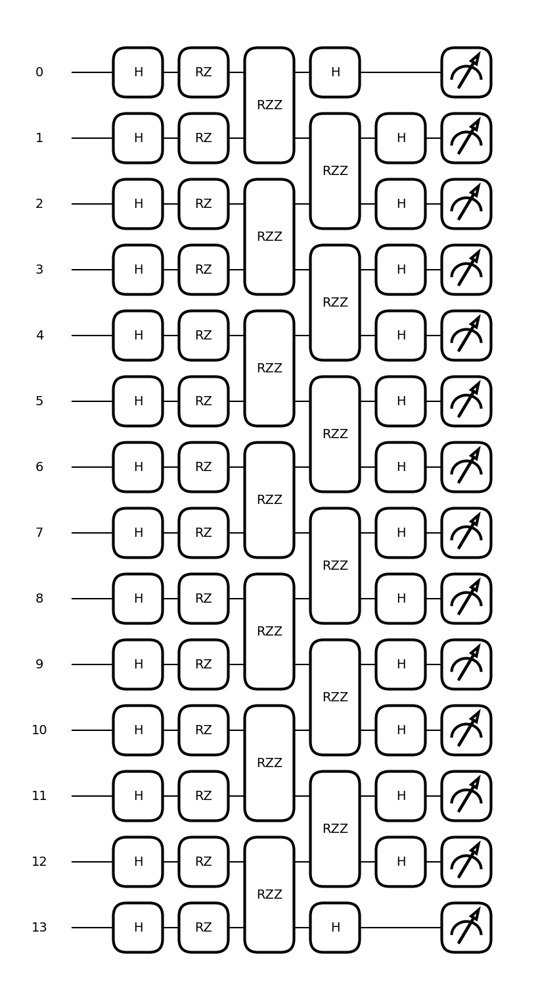

In [ ]:

n_qubits = 14
fm=None
imprimitive_pattern = [(i, i+1) for i in range(0,n_qubits-1,2)] + [(i, i+1) for i in range(1,n_qubits-1,2)]
iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)
# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  
# Create a params array matching that shape

params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
) 
#params=p[:-1]
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance

#create observable for the projector in the all ones state 

globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
builder.set_measurement("expectation",observables=[globalz,globalz2,zlast], wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit = builder.build()

qml.draw_mpl(circuit)(params=params)



In [ ]:
qtape = builder.compile(cut_circuit=False,device="lightning.kokkos", shots=None)
qtape(params)


(array(-3.80713317e-05), array(3.92890295e-05), array(-0.92385847))

In [ ]:
p=params
p

tensor([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,
         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,
         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,
        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,
        -0.79940706,  1.24272434], requires_grad=True)

In [ ]:
opt = qml.AdamOptimizer(stepsize=0.1)
steps=400

loss=[]
grad_globalz_list=[]
grad_globalz2_list=[]
grad_zlast_list=[]

def cost_function(params):
    expvals = qtape(params)
    prob = (1/4 * (-expvals[0] -expvals[1] + expvals[2] + 1))
    loss = -prob
    return loss

for step in range(steps):
    #first calculate individual gradients for each observable
    grad_globalz = qml.grad(lambda p: qtape(p)[0])(params)
    grad_globalz2 = qml.grad(lambda p: qtape(p)[1])(params)
    grad_zlast = qml.grad(lambda p: qtape(p)[2])(params)
    #append gradient norm
    grad_globalz_list.append(np.linalg.norm(grad_globalz))
    grad_globalz2_list.append(np.linalg.norm(grad_globalz2))
    grad_zlast_list.append(np.linalg.norm(grad_zlast)) 
    #ste_and_cost 
    params, curr_loss = opt.step_and_cost(lambda p: cost_function(p), params)

    loss.append(curr_loss)
    print(f"Step {step+1}/{steps}, Loss: {curr_loss}")



Step 1/400, Loss: -0.019035077662190175
Step 2/400, Loss: -0.03408392069152902
Step 3/400, Loss: -0.05273085925130924
Step 4/400, Loss: -0.07428383422817944
Step 5/400, Loss: -0.0979542367190426
Step 6/400, Loss: -0.12284923882422344
Step 7/400, Loss: -0.14798163909965728
Step 8/400, Loss: -0.17229962092025644
Step 9/400, Loss: -0.19473863314119166
Step 10/400, Loss: -0.21429836235744312
Step 11/400, Loss: -0.23015061457607824
Step 12/400, Loss: -0.24177078118054068
Step 13/400, Loss: -0.24908929306987113
Step 14/400, Loss: -0.2526310454083884
Step 15/400, Loss: -0.25365521690340465
Step 16/400, Loss: -0.254286641996429
Step 17/400, Loss: -0.25757258970593166
Step 18/400, Loss: -0.26709540582991226
Step 19/400, Loss: -0.28631595890775247
Step 20/400, Loss: -0.318431920579775
Step 21/400, Loss: -0.36515671199348143
Step 22/400, Loss: -0.4231650772266945
Step 23/400, Loss: -0.4872930583771836
Step 24/400, Loss: -0.551431940456394
Step 25/400, Loss: -0.6099264983987431
Step 26/400, Loss: 

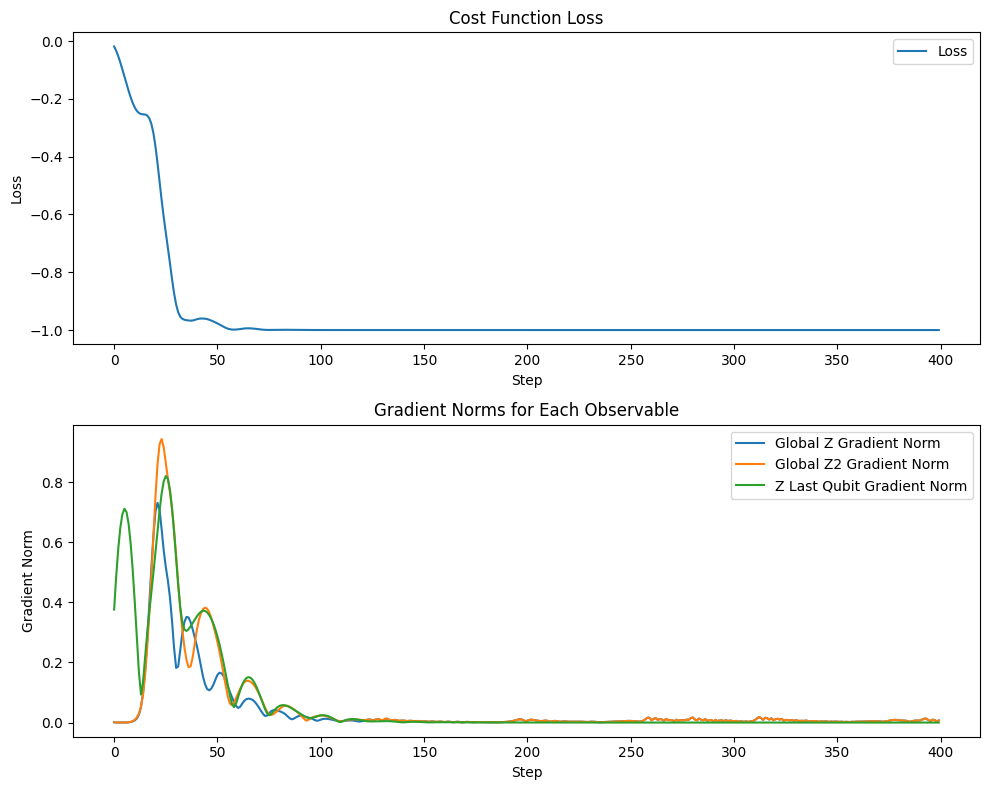

In [ ]:
#plot loss and gradient norms on two graphs on top of each other
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))   
ax1.plot(loss, label='Loss')
ax1.set_xlabel('Step')
ax1.set_ylabel('Loss')
ax1.set_title('Cost Function Loss')
ax1.legend()    
ax2.plot(grad_globalz_list, label='Global Z Gradient Norm')
ax2.plot(grad_globalz2_list, label='Global Z2 Gradient Norm')
ax2.plot(grad_zlast_list, label='Z Last Qubit Gradient Norm')
ax2.set_xlabel('Step')
ax2.set_ylabel('Gradient Norm')
ax2.set_title('Gradient Norms for Each Observable')
ax2.legend()
plt.tight_layout()
plt.show()  

(<Figure size 800x1500 with 1 Axes>, <Axes: >)

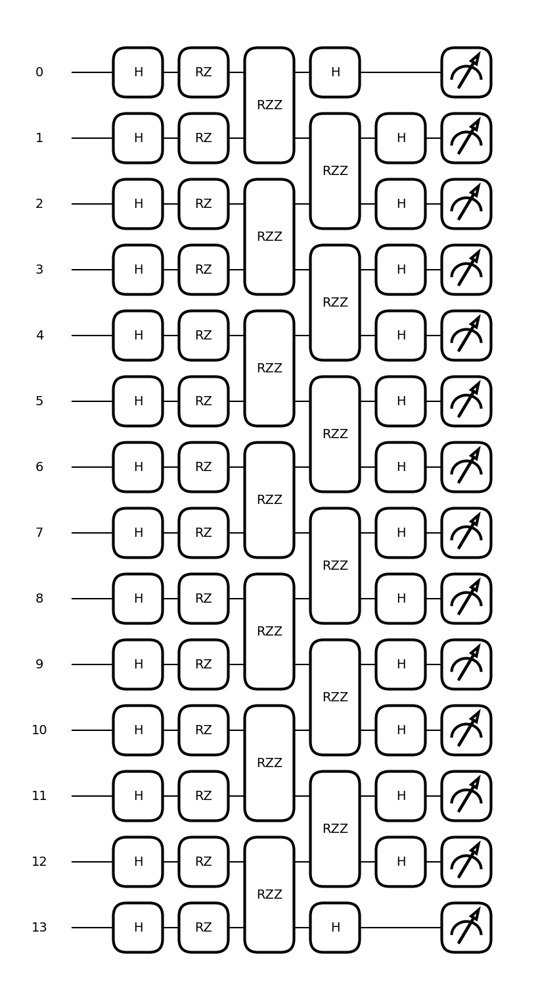

In [ ]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ", input_scaling=True)
#fm = AngleEmbedding(features=30, n_qubits=30, rotations=["YX 0 1", "Y 1", "ZX 0 2", "ZZZ 0 1 2"] , input_scaling=True)
#fm = AngleEmbedding(features=1, n_qubits=1, rotations="Y" , input_scaling=False)
n_qubits = 14
fm=None
imprimitive_pattern = [(i, i+1) for i in range(0,n_qubits-1,2)] + [(i, i+1) for i in range(1,n_qubits-1,2)]
iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)
#iqp = AngleAnsatz(n_qubits=len(wires), n_layers=1 , rotations = rotations , feature_map=None , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="chain", reuploading=False, include_hadamards_initial=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  
# Create a params array matching that shape

# Create input scaling params array matching that shape
#params = np.random.uniform(
#    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
#)
params = p  
#params=p[:-1]
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
#create observable for the projector in the all ones state 
#[qml.Projector([1]*len(wires),wires=list(wires))]
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
builder.set_measurement("expectation",observables=[globalz,globalz2,zlast], wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit = builder.build()

qml.draw_mpl(circuit)(params=params)



In [ ]:
qtape = builder.compile(cut_circuit=False,device="lightning.kokkos", shots=n_qubits**2)
qtape(params)


(array(0.01020408), array(0.01020408), array(-0.87755102))

In [ ]:
opt = qml.AdamOptimizer(stepsize=0.1)
steps=400

loss2=[]
grad_globalz_list2=[]
grad_globalz2_list2=[]
grad_zlast_list2=[]

def cost_function(params):
    expvals = qtape(params)
    prob = (1/4 * (-expvals[0] -expvals[1] + expvals[2] + 1))
    loss = -prob
    return loss

for step in range(steps):
    #first calculate individual gradients for each observable
    grad_globalz = qml.grad(lambda p: qtape(p)[0])(params)
    grad_globalz2 = qml.grad(lambda p: qtape(p)[1])(params)
    grad_zlast = qml.grad(lambda p: qtape(p)[2])(params)
    #append gradient norm
    grad_globalz_list2.append(np.linalg.norm(grad_globalz))
    grad_globalz2_list2.append(np.linalg.norm(grad_globalz2))
    grad_zlast_list2.append(np.linalg.norm(grad_zlast)) 
    #ste_and_cost 
    params, curr_loss = opt.step_and_cost(lambda p: cost_function(p), params)

    loss2.append(curr_loss)
    print(f"Step {step+1}/{steps}, Loss: {curr_loss}")



Step 1/400, Loss: -0.47959183673469385
Step 2/400, Loss: -0.5306122448979591
Step 3/400, Loss: -0.4897959183673469
Step 4/400, Loss: -0.41836734693877553
Step 5/400, Loss: -0.5255102040816326
Step 6/400, Loss: -0.5051020408163265
Step 7/400, Loss: -0.48469387755102045
Step 8/400, Loss: -0.5408163265306123
Step 9/400, Loss: -0.5051020408163265
Step 10/400, Loss: -0.4897959183673469
Step 11/400, Loss: -0.5357142857142857
Step 12/400, Loss: -0.49489795918367346
Step 13/400, Loss: -0.49489795918367346
Step 14/400, Loss: -0.5255102040816326
Step 15/400, Loss: -0.4897959183673469
Step 16/400, Loss: -0.48469387755102045
Step 17/400, Loss: -0.41836734693877553
Step 18/400, Loss: -0.5204081632653061
Step 19/400, Loss: -0.5
Step 20/400, Loss: -0.5561224489795918
Step 21/400, Loss: -0.4897959183673469
Step 22/400, Loss: -0.49489795918367346
Step 23/400, Loss: -0.4387755102040816
Step 24/400, Loss: -0.5
Step 25/400, Loss: -0.4897959183673469
Step 26/400, Loss: -0.41836734693877553
Step 27/400, Los

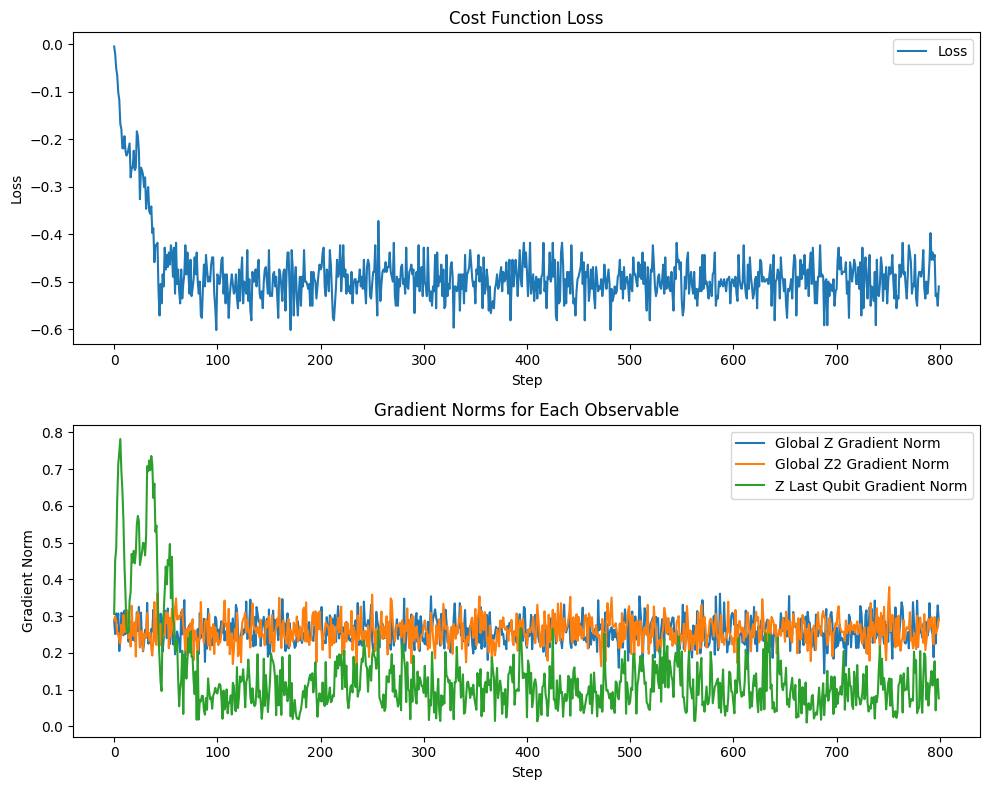

In [ ]:
#plot loss and gradient norms on two graphs on top of each other
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))   
ax1.plot(loss+loss2, label='Loss')
ax1.set_xlabel('Step')
ax1.set_ylabel('Loss')
ax1.set_title('Cost Function Loss')
ax1.legend()    
ax2.plot(grad_globalz_list+grad_globalz_list2, label='Global Z Gradient Norm')
ax2.plot(grad_globalz2_list+grad_globalz2_list2, label='Global Z2 Gradient Norm')
ax2.plot(grad_zlast_list+grad_zlast_list2, label='Z Last Qubit Gradient Norm')
ax2.set_xlabel('Step')
ax2.set_ylabel('Gradient Norm')
ax2.set_title('Gradient Norms for Each Observable')
ax2.legend()
plt.tight_layout()
plt.show()  

### |A|=4

(<Figure size 800x1500 with 1 Axes>, <Axes: >)

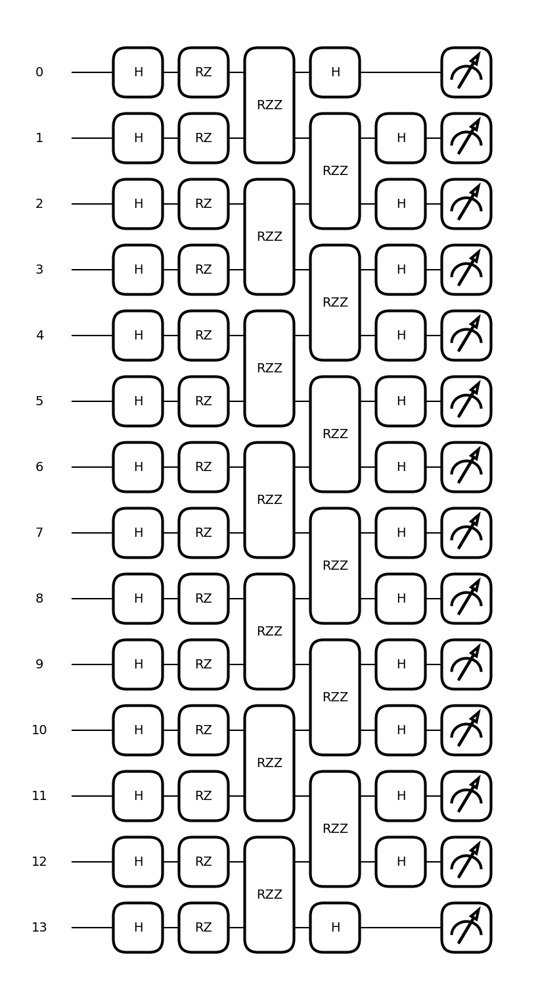

In [ ]:

#fm = AngleEmbedding(features=4, n_qubits=4, rotations="YZ", input_scaling=True)
#fm = AngleEmbedding(features=30, n_qubits=30, rotations=["YX 0 1", "Y 1", "ZX 0 2", "ZZZ 0 1 2"] , input_scaling=True)
#fm = AngleEmbedding(features=1, n_qubits=1, rotations="Y" , input_scaling=False)
n_qubits = 14
fm=None
imprimitive_pattern = [(i, i+1) for i in range(0,n_qubits-1,2)] + [(i, i+1) for i in range(1,n_qubits-1,2)]
iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  
# Create a params array matching that shape

#Create params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
)
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
#create observable for the probability of the all ones state in parity like policy 
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
builder.set_measurement("expectation",observables=[globalz,globalz2,zlast], wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit = builder.build()

qml.draw_mpl(circuit)(params=params)



In [ ]:
params

tensor([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,
         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,
         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,
        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,
        -0.79940706,  1.24272434], requires_grad=True)

In [ ]:
2**14

16384

In [ ]:
int(round(14**2.5))


733

In [ ]:
qtape = builder.compile(cut_circuit=False,device="lightning.kokkos", shots=int(round(14**2.5)))
qtape(params)


(array(0.02319236), array(0.02319236), array(0.21964529))

In [ ]:
opt = qml.AdamOptimizer(stepsize=0.1)
steps=400

loss2=[]
grad_globalz_list2=[]
grad_globalz2_list2=[]
grad_zlast_list2=[]

def cost_function(params):
    expvals = qtape(params)
    prob = (1/4 * (-expvals[0] -expvals[1] + expvals[2] + 1))
    loss = -prob
    return loss

for step in range(steps):
    #first calculate individual gradients for each observable
    grad_globalz = qml.grad(lambda p: qtape(p)[0])(params)
    grad_globalz2 = qml.grad(lambda p: qtape(p)[1])(params)
    grad_zlast = qml.grad(lambda p: qtape(p)[2])(params)
    #append gradient norm
    grad_globalz_list2.append(np.linalg.norm(grad_globalz))
    grad_globalz2_list2.append(np.linalg.norm(grad_globalz2))
    grad_zlast_list2.append(np.linalg.norm(grad_zlast)) 
    #ste_and_cost 
    params, curr_loss = opt.step_and_cost(lambda p: cost_function(p), params)

    loss2.append(curr_loss)
    print(f"Step {step+1}/{steps}, Loss: {curr_loss}")



Step 1/400, Loss: -0.015006821282401106
Step 2/400, Loss: -0.02046384720327421
Step 3/400, Loss: -0.06684856753069579
Step 4/400, Loss: -0.07776261937244203
Step 5/400, Loss: -0.08731241473396997
Step 6/400, Loss: -0.11869031377899045
Step 7/400, Loss: -0.1418826739427012
Step 8/400, Loss: -0.17189631650750342
Step 9/400, Loss: -0.21009549795361526
Step 10/400, Loss: -0.2100954979536153
Step 11/400, Loss: -0.2291950886766712
Step 12/400, Loss: -0.2605729877216917
Step 13/400, Loss: -0.23874488403819918
Step 14/400, Loss: -0.22646657571623466
Step 15/400, Loss: -0.2373806275579809
Step 16/400, Loss: -0.2578444747612551
Step 17/400, Loss: -0.2551159618008186
Step 18/400, Loss: -0.24010914051841747
Step 19/400, Loss: -0.252387448840382
Step 20/400, Loss: -0.24420190995907232
Step 21/400, Loss: -0.2660300136425648
Step 22/400, Loss: -0.2291950886766712
Step 23/400, Loss: -0.2291950886766712
Step 24/400, Loss: -0.24829467939972716
Step 25/400, Loss: -0.24147339699863574
Step 26/400, Loss: -

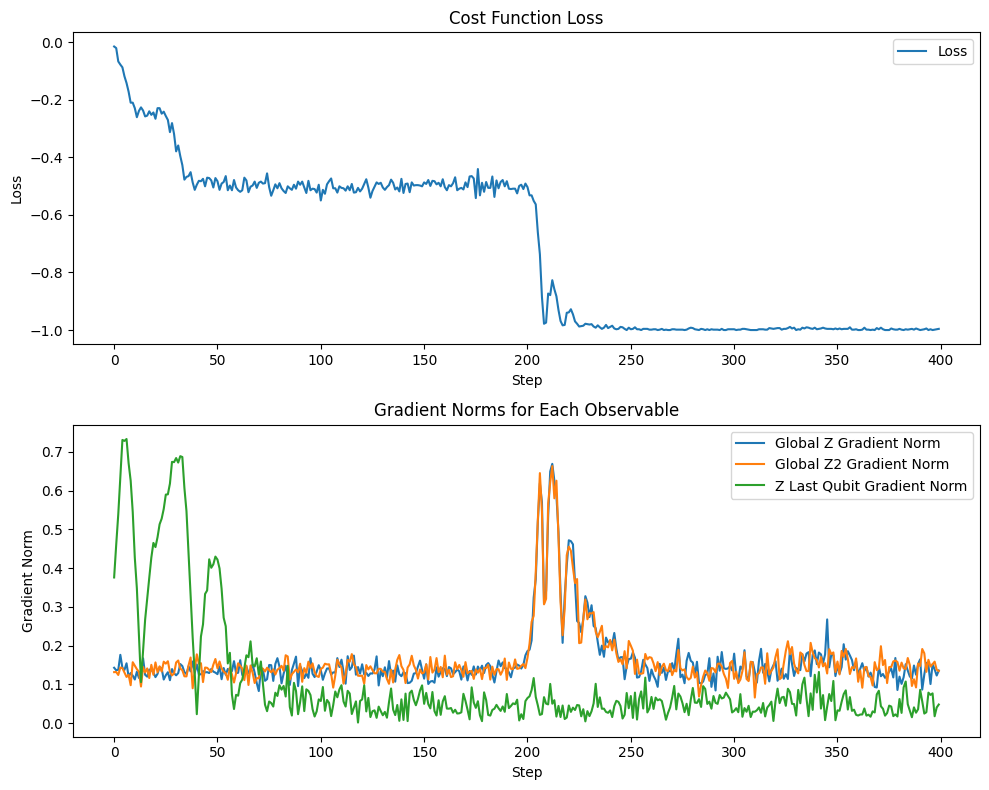

In [ ]:
#plot loss and gradient norms on two graphs on top of each other
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))   
ax1.plot(loss2, label='Loss')
ax1.set_xlabel('Step')
ax1.set_ylabel('Loss')
ax1.set_title('Cost Function Loss')
ax1.legend()    
ax2.plot(grad_globalz_list2, label='Global Z Gradient Norm')
ax2.plot(grad_globalz2_list2, label='Global Z2 Gradient Norm')
ax2.plot(grad_zlast_list2, label='Z Last Qubit Gradient Norm')
ax2.set_xlabel('Step')
ax2.set_ylabel('Gradient Norm')
ax2.set_title('Gradient Norms for Each Observable')
ax2.legend()
plt.tight_layout()
plt.show()  

### |A|=8

In [ ]:
def z_string(wires):
    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)


n_qubits = 14

A_wires   = list(range(n_qubits))       # 0,...,13
B_wires   = list(range(n_qubits - 1))   # 0,...,12
C_wires   = list(range(n_qubits - 2))   # 0,...,11

AB_wires  = [n_qubits - 1]              # 13
AC_wires  = [n_qubits - 2, n_qubits - 1] # 12,13
BC_wires  = [n_qubits - 2]              # 12
ABC_wires = list(range(n_qubits - 2)) + [n_qubits - 1]  # 0,...,11,13

observables = [
    z_string(A_wires),
    z_string(B_wires),
    z_string(C_wires),
    z_string(AB_wires),
    z_string(AC_wires),
    z_string(BC_wires),
    z_string(ABC_wires),
]

(<Figure size 800x1500 with 1 Axes>, <Axes: >)

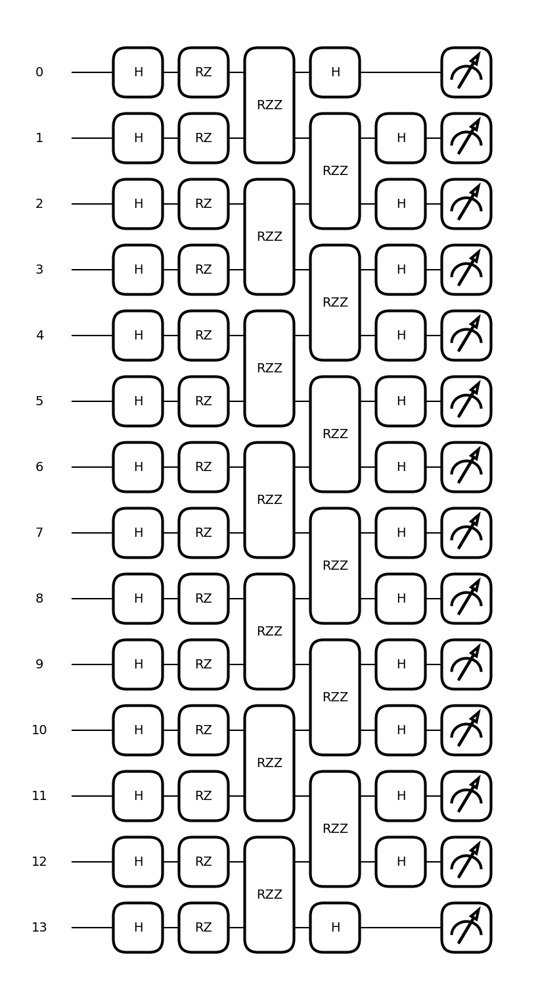

In [ ]:
n_qubits = 14
fm=None
imprimitive_pattern = [(i, i+1) for i in range(0,n_qubits-1,2)] + [(i, i+1) for i in range(1,n_qubits-1,2)]
iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  
# Create a params array matching that shape

#Create params array matching that shape
#params = np.random.uniform(
#    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
#)

params = np.array([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,
         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,
         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,
        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,
        -0.79940706,  1.24272434], requires_grad=True)
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
#create observable for the probability of the all ones state in parity like policy 

builder.set_measurement("expectation",observables=observables, wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit = builder.build()
qtape = builder.compile(cut_circuit=False,device="lightning.kokkos", shots=int(round(14**2.5)))

qml.draw_mpl(circuit)(params=params)



In [ ]:
def prob_action_111(expvals):

    return (1 / 8) * (

        1

        - expvals[0]  # -A

        - expvals[1]  # -B

        - expvals[2]  # -C

        + expvals[3]  # +AB

        + expvals[4]  # +AC

        + expvals[5]  # +BC

        - expvals[6]  # -ABC

    )

def cost_function(params):

    expvals = qtape(params)

    prob = prob_action_111(expvals)

    return -prob

opt = qml.AdamOptimizer(stepsize=0.1)
steps = 400

loss8 = []

grad_A_list = []
grad_B_list = []
grad_C_list = []
grad_AB_list = []
grad_AC_list = []
grad_BC_list = []
grad_ABC_list = []

def expvals_fn(params):
    return np.stack(qtape(params))

def prob_action_111_from_expvals(expvals):
    return (1 / 8) * (
        1
        - expvals[0]
        - expvals[1]
        - expvals[2]
        + expvals[3]
        + expvals[4]
        + expvals[5]
        - expvals[6]
    )

def cost_function(params):
    expvals = expvals_fn(params)
    prob = prob_action_111_from_expvals(expvals)
    return -prob

jac_expvals_fn = qml.jacobian(expvals_fn)

for step in range(steps):

    # Individual observable gradients

    grad_A = qml.grad(lambda p: qtape(p)[0])(params)

    grad_B = qml.grad(lambda p: qtape(p)[1])(params)

    grad_C = qml.grad(lambda p: qtape(p)[2])(params)

    grad_AB = qml.grad(lambda p: qtape(p)[3])(params)

    grad_AC = qml.grad(lambda p: qtape(p)[4])(params)

    grad_BC = qml.grad(lambda p: qtape(p)[5])(params)

    grad_ABC = qml.grad(lambda p: qtape(p)[6])(params)

    # Store gradient norms

    grad_A_list.append(np.linalg.norm(grad_A))

    grad_B_list.append(np.linalg.norm(grad_B))

    grad_C_list.append(np.linalg.norm(grad_C))

    grad_AB_list.append(np.linalg.norm(grad_AB))

    grad_AC_list.append(np.linalg.norm(grad_AC))

    grad_BC_list.append(np.linalg.norm(grad_BC))

    grad_ABC_list.append(np.linalg.norm(grad_ABC))

    # Optimization step

    params, curr_loss = opt.step_and_cost(cost_function, params)

    loss8.append(curr_loss)

    print(

        f"Step {step + 1}/{steps}, "

        f"Loss: {curr_loss}, "

    )

Step 1/400, Loss: -0.009549795361527958, 
Step 2/400, Loss: -0.012278308321964531, 
Step 3/400, Loss: -0.024556616643929052, 
Step 4/400, Loss: -0.046384720327421566, 
Step 5/400, Loss: -0.046384720327421566, 
Step 6/400, Loss: -0.06275579809004092, 
Step 7/400, Loss: -0.07230559345156891, 
Step 8/400, Loss: -0.08458390177353343, 
Step 9/400, Loss: -0.11459754433833559, 
Step 10/400, Loss: -0.08731241473396999, 
Step 11/400, Loss: -0.11323328785811732, 
Step 12/400, Loss: -0.12687585266030016, 
Step 13/400, Loss: -0.13369713506139155, 
Step 14/400, Loss: -0.14188267394270124, 
Step 15/400, Loss: -0.12960436562073668, 
Step 16/400, Loss: -0.15552523874488405, 
Step 17/400, Loss: -0.16780354706684855, 
Step 18/400, Loss: -0.1937244201909959, 
Step 19/400, Loss: -0.23465211459754434, 
Step 20/400, Loss: -0.2728512960436562, 
Step 21/400, Loss: -0.30695770804911326, 
Step 22/400, Loss: -0.3751705320600273, 
Step 23/400, Loss: -0.38199181446111874, 
Step 24/400, Loss: -0.4024556616643929, 


KeyboardInterrupt: 

/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3609892161.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  global_cmap = cm.get_cmap("Reds")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3609892161.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  local_cmap = cm.get_cmap("Blues")


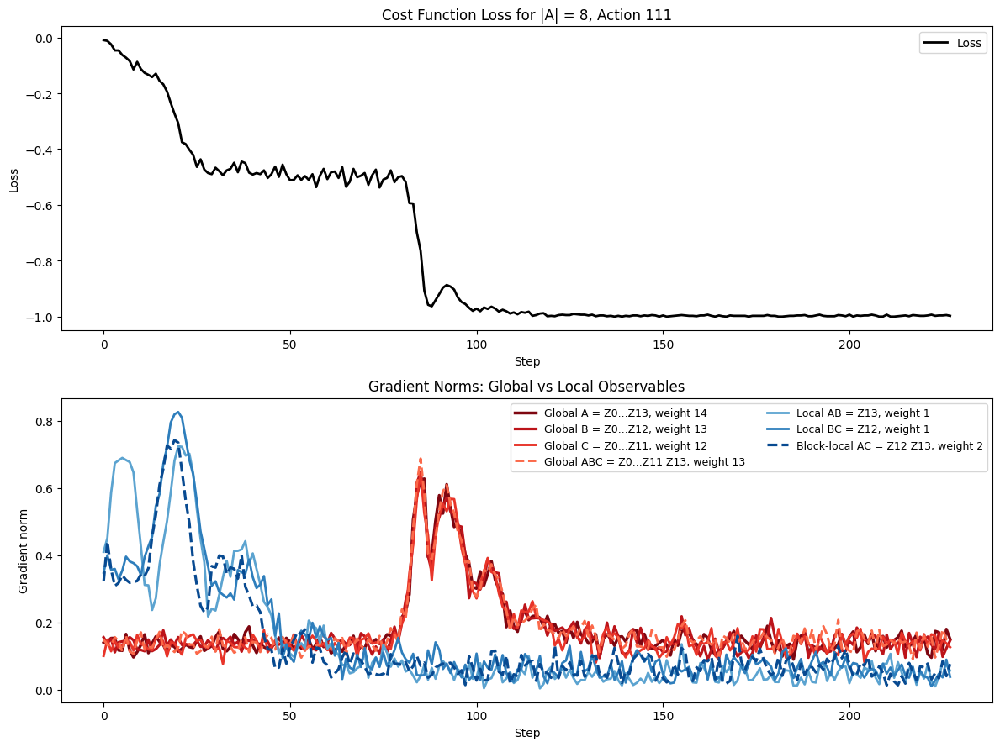

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as onp  # regular numpy only for colors

# Gradient colors
global_cmap = cm.get_cmap("Reds")
local_cmap = cm.get_cmap("Blues")

# Global terms: darker for more global / higher weight
color_A   = global_cmap(0.95)
color_B   = global_cmap(0.80)
color_C   = global_cmap(0.65)
color_ABC = global_cmap(0.50)

# Local terms: darker for larger local block
color_AB = local_cmap(0.55)  # weight 1
color_BC = local_cmap(0.70)  # weight 1
color_AC = local_cmap(0.90)  # weight 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9))

# Loss plot
ax1.plot(loss8, label="Loss", color="black", linewidth=2)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title("Cost Function Loss for |A| = 8, Action 111")
ax1.legend()

# Global/high-weight terms
ax2.plot(
    grad_A_list,
    label="Global A = Z0...Z13, weight 14",
    color=color_A,
    linewidth=2.5,
)

ax2.plot(
    grad_B_list,
    label="Global B = Z0...Z12, weight 13",
    color=color_B,
    linewidth=2.3,
)

ax2.plot(
    grad_C_list,
    label="Global C = Z0...Z11, weight 12",
    color=color_C,
    linewidth=2.1,
)

ax2.plot(
    grad_ABC_list,
    label="Global ABC = Z0...Z11 Z13, weight 13",
    color=color_ABC,
    linewidth=2.1,
    linestyle="--",
)

# Local/block-local terms
ax2.plot(
    grad_AB_list,
    label="Local AB = Z13, weight 1",
    color=color_AB,
    linewidth=2,
)

ax2.plot(
    grad_BC_list,
    label="Local BC = Z12, weight 1",
    color=color_BC,
    linewidth=2,
)

ax2.plot(
    grad_AC_list,
    label="Block-local AC = Z12 Z13, weight 2",
    color=color_AC,
    linewidth=2.3,
    linestyle="--",
)

ax2.set_xlabel("Step")
ax2.set_ylabel("Gradient norm")
ax2.set_title("Gradient Norms: Global vs Local Observables")
ax2.legend(ncol=2, fontsize=9)

plt.tight_layout()
plt.show()

#### |A| = 16

Observable order:
 0: A    | weight=14 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] | obs=ZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13
 1: B    | weight=13 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | obs=ZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12
 2: C    | weight=12 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] | obs=ZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11
 3: D    | weight=11 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | obs=ZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10
 4: AB   | weight= 1 | wires=[13] | obs=Z 13
 5: AC   | weight= 2 | wires=[12, 13] | obs=ZZ 12 13
 6: AD   | weight= 3 | wires=[11, 12, 13] | obs=ZZZ 11 12 13
 7: BC   | weight= 1 | wires=[12] | obs=Z 12
 8: BD   | weight= 2 | wires=[11, 12] | obs=ZZ 11 12
 9: CD   | weight= 1 | wires=[11] | obs=Z 11
10: ABC  | weight=13 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13] | obs=ZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 13
11: ABD  | weight=12 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 13] | obs=ZZZZZZZZZZZZ 0 1 

KeyboardInterrupt: 

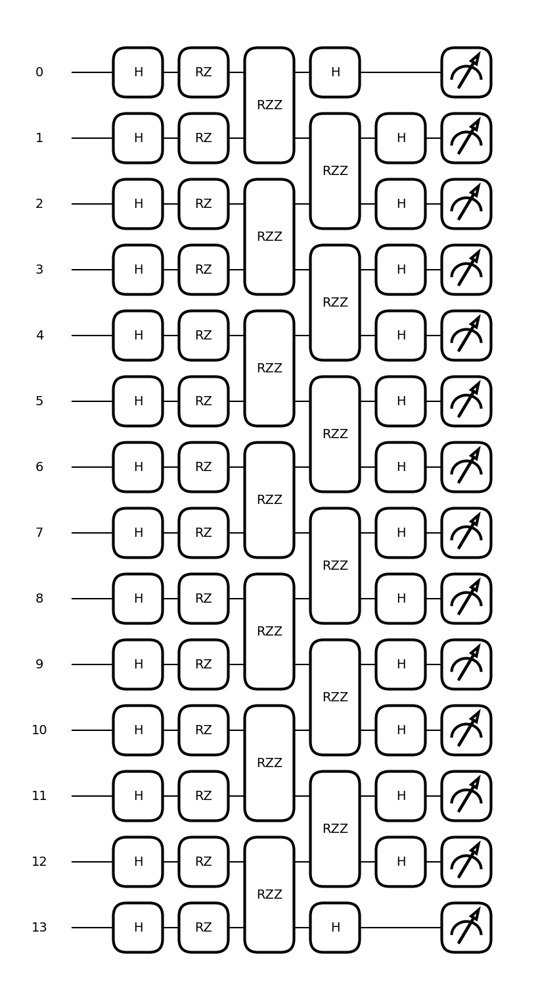

In [ ]:
from itertools import combinations
def z_string(wires):

    """

    Convert a list of wires into your QASP observable string format.

    Example:

        wires = [0, 1, 3]

        returns "ZZZ 0 1 3"

    """

    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)

def xor_product_wires(list_of_wire_sets):

    """

    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.

    This function returns the symmetric difference of all wire sets.

    """

    counts = {}

    for wires in list_of_wire_sets:

        for w in wires:

            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]

    return sorted(product_wires)

def build_parity_observables(n_qubits, n_action_bits):

    """

    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    For |A|=16, n_action_bits=4.

    We define the base parity generators:

        A = Z0 Z1 ... Z_{n-1}

        B = Z0 Z1 ... Z_{n-2}

        C = Z0 Z1 ... Z_{n-3}

        D = Z0 Z1 ... Z_{n-4}

    Then generate all products:

        A, B, C, D,

        AB, AC, AD, BC, BD, CD,

        ABC, ABD, ACD, BCD,

        ABCD.

    Returns:

        observable_labels: list[str]

        observable_wires: list[list[int]]

        observables: list[str]

        subsets: list[tuple[int]]

    """

    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    # A has n wires, B has n-1 wires, C has n-2 wires, ...

    base_wires = [

        list(range(n_qubits - i))

        for i in range(n_action_bits)

    ]

    observable_labels = []

    observable_wires = []

    observables = []

    subsets = []

    for r in range(1, n_action_bits + 1):

        for subset in combinations(range(n_action_bits), r):

            label = "".join(base_labels[i] for i in subset)

            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)

            observable_wires.append(wires)

            observables.append(z_string(wires))

            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets

def projector_coeffs_for_bits(bits, subsets):

    """

    Build the coefficients for the projector onto a target action bitstring.

    For bits = [1, 1, 1, 1], the projector is:

        Pi_1111 = (1/16)(I - A)(I - B)(I - C)(I - D)

    More generally:

        Pi_b = (1/16) prod_j (I + s_j P_j)

    where:

        s_j = +1 if bit_j = 0

        s_j = -1 if bit_j = 1

    Returns:

        constant: float

        coeffs: np.array of length 15

    """

    n_action_bits = len(bits)

    signs = [

        1 if bit == 0 else -1

        for bit in bits

    ]

    constant = 1 / (2 ** n_action_bits)

    coeffs = []

    for subset in subsets:

        coeff = 1

        for i in subset:

            coeff *= signs[i]

        coeffs.append(coeff * constant)

    return constant, np.array(coeffs)

def prob_from_expvals(expvals, bits, subsets):

    """

    Probability of the target action according to the parity-projector expansion.

    """

    constant, coeffs = projector_coeffs_for_bits(bits, subsets)

    return constant + np.dot(coeffs, expvals)

# ============================================================

# 2. Build |A| = 16 parity observables

# ============================================================

n_qubits = 14

n_action_bits = 4      # because |A| = 16

target_bits = [1, 1, 1, 1]  # action 1111, i.e. action 16 in one-indexed convention

observable_labels, observable_wires, observables, subsets = build_parity_observables(

    n_qubits=n_qubits,

    n_action_bits=n_action_bits,

)

print("Observable order:")

for i, (label, wires, obs) in enumerate(zip(observable_labels, observable_wires, observables)):

    print(f"{i:2d}: {label:4s} | weight={len(wires):2d} | wires={wires} | obs={obs}")

# ============================================================

# 3. Build IQP ansatz and initialize parameters

# ============================================================

fm = None

imprimitive_pattern = (

    [(i, i + 1) for i in range(0, n_qubits - 1, 2)]

    + [(i, i + 1) for i in range(1, n_qubits - 1, 2)]

)

iqp = IQPAnsatz(

    n_qubits=n_qubits,

    imprimitive_pattern=imprimitive_pattern,

    n_layers=1,

    feature_map=fm,

    reuploading=False,

)

# Important: use the actual expected flattened parameter size.

# This avoids the earlier shape mismatch error.

expected_total = iqp.n_layers * iqp._block_size
shapes = iqp.get_param_shapes()
'''
params = np.array([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
                   
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,

         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,

         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,

        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,

        -0.79940706,  1.24272434], requires_grad=True)
'''
params = np.random.uniform(low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True)


# ============================================================

# 4. Build and compile circuit

# ============================================================

builder = CircuitBuilder(n_qubits=n_qubits)

builder.set_ansatz(iqp)

builder.set_measurement(

    "expectation",

    observables=observables,

    wires=list(range(n_qubits)),

)

circuit = builder.build()

qtape = builder.compile(

    cut_circuit=False,

    device="lightning.kokkos",

    shots=int(round(14 ** 2.5)),

)

# Optional drawing

qml.draw_mpl(circuit)(params=params)

# ============================================================

# 5. Define cost function for action 1111

# ============================================================

def expvals_fn(params):

    return qml.math.stack(qtape(params))

def prob_action_1111_from_expvals(expvals):

    return prob_from_expvals(

        expvals=expvals,

        bits=target_bits,

        subsets=subsets,

    )

def cost_function(params):

    expvals = expvals_fn(params)

    prob = prob_action_1111_from_expvals(expvals)

    return -prob

# Print explicit coefficients for sanity check

constant, coeffs_1111 = projector_coeffs_for_bits(target_bits, subsets)

print("\nProjector expansion for action 1111:")

print("constant:", constant)

for label, coeff in zip(observable_labels, coeffs_1111):

    print(f"{label:4s}: {coeff}")

# ============================================================

# 6. Training loop with individual observable gradients

# ============================================================

opt = qml.AdamOptimizer(stepsize=0.1)

steps = 400

loss16 = []

# Dictionary: label -> list of gradient norms

grad_norms = {

    label: []

    for label in observable_labels

}

grad_prob_1111_list = []

grad_loss_1111_list = []

prob_1111_list = []

for step in range(steps):

    # Individual observable gradients.

    # Important: use idx=i to avoid Python late-binding in lambda.

    individual_grads = []

    for i, label in enumerate(observable_labels):

        grad_i = qml.grad(lambda p, idx=i: qtape(p)[idx])(params)

        individual_grads.append(grad_i)

        grad_norms[label].append(np.linalg.norm(grad_i))

    # Full probability-gradient direction from the signed combination

    grad_prob_1111 = sum(

        coeffs_1111[i] * individual_grads[i]

        for i in range(len(individual_grads))

    )

    grad_loss_1111 = -grad_prob_1111

    grad_prob_1111_list.append(np.linalg.norm(grad_prob_1111))

    grad_loss_1111_list.append(np.linalg.norm(grad_loss_1111))

    # Optimization step

    params, curr_loss = opt.step_and_cost(cost_function, params)

    curr_prob = -curr_loss

    loss16.append(curr_loss)

    prob_1111_list.append(curr_prob)

    print(

        f"Step {step + 1}/{steps}, "

        f"Loss: {curr_loss}, "

        f"Prob(action 1111): {curr_prob}, "

        f"||grad prob 1111||: {grad_prob_1111_list[-1]}"

    )


/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/2283031593.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  global_cmap = cm.get_cmap("Reds")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/2283031593.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  local_cmap = cm.get_cmap("Blues")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/2283031593.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  middle_cmap

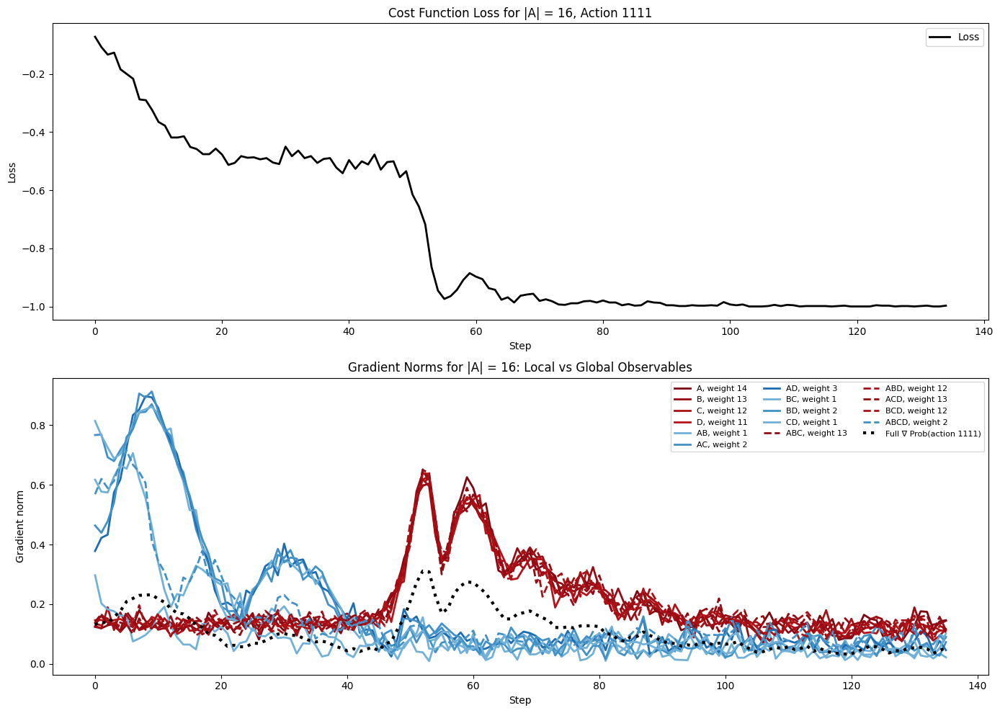

In [ ]:
# ============================================================

# 7. Plot loss and gradient norms with local/global color families

# ============================================================

# We classify by Pauli weight.

# Local: low-weight strings, e.g. 1, 2, 3, 4

# Global: high-weight strings, e.g. near n_qubits

# Intermediate: anything else, if it appears

weights = {

    label: len(wires)

    for label, wires in zip(observable_labels, observable_wires)

}

max_weight = max(weights.values())

min_weight = min(weights.values())

global_cmap = cm.get_cmap("Reds")

local_cmap = cm.get_cmap("Blues")

middle_cmap = cm.get_cmap("Purples")

def color_for_weight(weight):

    """

    Color convention:

        blue   -> local / low-weight terms

        purple -> intermediate terms

        red    -> global / high-weight terms

    """

    if weight <= 4:

        # local family

        # darker blue for larger local support

        t = 0.35 + 0.55 * (weight / 4)

        return local_cmap(t)

    elif weight >= n_qubits // 2:

        # global family

        # darker red for more global support

        t = 0.35 + 0.60 * (weight / n_qubits)

        return global_cmap(t)

    else:

        # intermediate family

        t = 0.55

        return middle_cmap(t)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Loss plot

ax1.plot(loss16, label="Loss", color="black", linewidth=2)

ax1.set_xlabel("Step")

ax1.set_ylabel("Loss")

ax1.set_title("Cost Function Loss for |A| = 16, Action 1111")

ax1.legend()

# Gradient norm plot

for label in observable_labels:

    weight = weights[label]

    linestyle = "-" if len(label) <= 2 else "--"

    ax2.plot(

        grad_norms[label],

        label=f"{label}, weight {weight}",

        color=color_for_weight(weight),

        linewidth=2,

        linestyle=linestyle,

    )

# Full action-probability gradient reference

ax2.plot(

    grad_prob_1111_list,

    label="Full ∇ Prob(action 1111)",

    color="black",

    linewidth=3,

    linestyle=":",

)

ax2.set_xlabel("Step")

ax2.set_ylabel("Gradient norm")

ax2.set_title("Gradient Norms for |A| = 16: Local vs Global Observables")

ax2.legend(ncol=3, fontsize=8)

plt.tight_layout()

plt.show()

Observable order:
 0: A    | weight=14 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] | obs=ZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13
 1: B    | weight=13 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | obs=ZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12
 2: C    | weight=12 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] | obs=ZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11
 3: D    | weight=11 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | obs=ZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10
 4: E    | weight=10 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9] | obs=ZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9
 5: AB   | weight= 1 | wires=[13] | obs=Z 13
 6: AC   | weight= 2 | wires=[12, 13] | obs=ZZ 12 13
 7: AD   | weight= 3 | wires=[11, 12, 13] | obs=ZZZ 11 12 13
 8: AE   | weight= 4 | wires=[10, 11, 12, 13] | obs=ZZZZ 10 11 12 13
 9: BC   | weight= 1 | wires=[12] | obs=Z 12
10: BD   | weight= 2 | wires=[11, 12] | obs=ZZ 11 12
11: BE   | weight= 3 | wires=[10, 11, 12] | obs=ZZZ 10 11 12
12: CD   | weight= 1 | wires=[

KeyboardInterrupt: 

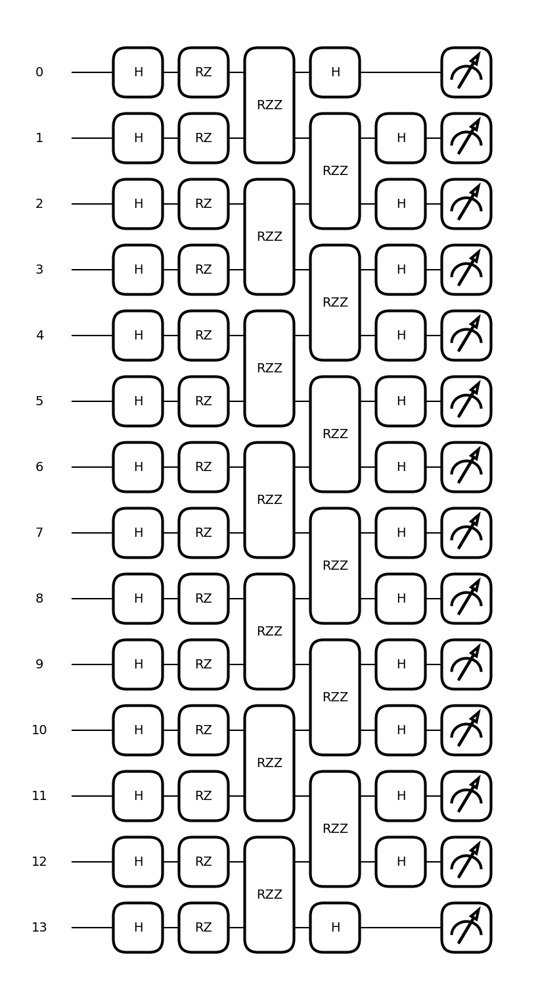

In [ ]:
from itertools import combinations
def z_string(wires):

    """

    Convert a list of wires into your QASP observable string format.

    Example:

        wires = [0, 1, 3]

        returns "ZZZ 0 1 3"

    """

    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)

def xor_product_wires(list_of_wire_sets):

    """

    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.

    This function returns the symmetric difference of all wire sets.

    """

    counts = {}

    for wires in list_of_wire_sets:

        for w in wires:

            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]

    return sorted(product_wires)

def build_parity_observables(n_qubits, n_action_bits):

    """

    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    For |A|=16, n_action_bits=4.

    We define the base parity generators:

        A = Z0 Z1 ... Z_{n-1}

        B = Z0 Z1 ... Z_{n-2}

        C = Z0 Z1 ... Z_{n-3}

        D = Z0 Z1 ... Z_{n-4}

    Then generate all products:

        A, B, C, D,

        AB, AC, AD, BC, BD, CD,

        ABC, ABD, ACD, BCD,

        ABCD.

    Returns:

        observable_labels: list[str]

        observable_wires: list[list[int]]

        observables: list[str]

        subsets: list[tuple[int]]

    """

    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    # A has n wires, B has n-1 wires, C has n-2 wires, ...

    base_wires = [

        list(range(n_qubits - i))

        for i in range(n_action_bits)

    ]

    observable_labels = []

    observable_wires = []

    observables = []

    subsets = []

    for r in range(1, n_action_bits + 1):

        for subset in combinations(range(n_action_bits), r):

            label = "".join(base_labels[i] for i in subset)

            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)

            observable_wires.append(wires)

            observables.append(z_string(wires))

            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets

def projector_coeffs_for_bits(bits, subsets):

    """

    Build the coefficients for the projector onto a target action bitstring.

    For bits = [1, 1, 1, 1], the projector is:

        Pi_1111 = (1/16)(I - A)(I - B)(I - C)(I - D)

    More generally:

        Pi_b = (1/16) prod_j (I + s_j P_j)

    where:

        s_j = +1 if bit_j = 0

        s_j = -1 if bit_j = 1

    Returns:

        constant: float

        coeffs: np.array of length 15

    """

    n_action_bits = len(bits)

    signs = [

        1 if bit == 0 else -1

        for bit in bits

    ]

    constant = 1 / (2 ** n_action_bits)

    coeffs = []

    for subset in subsets:

        coeff = 1

        for i in subset:

            coeff *= signs[i]

        coeffs.append(coeff * constant)

    return constant, np.array(coeffs)

def prob_from_expvals(expvals, bits, subsets):

    """

    Probability of the target action according to the parity-projector expansion.

    """

    constant, coeffs = projector_coeffs_for_bits(bits, subsets)

    return constant + np.dot(coeffs, expvals)

# ============================================================

# 2. Build |A| = 16 parity observables

# ============================================================

n_qubits = 14

n_action_bits = 5      # because |A| = 32

target_bits = [1, 1, 1, 1, 1]  # action 1111, i.e. action 16 in one-indexed convention

observable_labels, observable_wires, observables, subsets = build_parity_observables(

    n_qubits=n_qubits,

    n_action_bits=n_action_bits,

)

print("Observable order:")

for i, (label, wires, obs) in enumerate(zip(observable_labels, observable_wires, observables)):

    print(f"{i:2d}: {label:4s} | weight={len(wires):2d} | wires={wires} | obs={obs}")

# ============================================================

# 3. Build IQP ansatz and initialize parameters

# ============================================================

fm = None

imprimitive_pattern = (

    [(i, i + 1) for i in range(0, n_qubits - 1, 2)]

    + [(i, i + 1) for i in range(1, n_qubits - 1, 2)]

)

iqp = IQPAnsatz(

    n_qubits=n_qubits,

    imprimitive_pattern=imprimitive_pattern,

    n_layers=1,

    feature_map=fm,

    reuploading=False,

)

# Important: use the actual expected flattened parameter size.

# This avoids the earlier shape mismatch error.

expected_total = iqp.n_layers * iqp._block_size
shapes = iqp.get_param_shapes()
'''
params = np.array([-1.50871322, -0.53190723,  0.03942657,  1.79081158,  0.78521262,
                   
        -2.09980467,  1.22935312,  0.56858038, -0.89760981, -2.53115428,

         3.09377339,  2.82400213, -1.50005957, -0.32962647,  2.68653073,

         2.74050669,  1.99801206, -1.99490205,  0.79098121,  2.87018083,

        -2.92402795,  0.10546808,  2.64154584, -1.97926933, -0.06028925,

        -0.79940706,  1.24272434], requires_grad=True)
'''
params = np.random.uniform(low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True)


# ============================================================

# 4. Build and compile circuit

# ============================================================

builder = CircuitBuilder(n_qubits=n_qubits)

builder.set_ansatz(iqp)

builder.set_measurement(

    "expectation",

    observables=observables,

    wires=list(range(n_qubits)),

)

circuit = builder.build()

qtape = builder.compile(

    cut_circuit=False,

    device="lightning.kokkos",

    shots=int(round(14 ** 2.5)),

)

# Optional drawing

qml.draw_mpl(circuit)(params=params)

# ============================================================

# 5. Define cost function for action 1111

# ============================================================

def expvals_fn(params):

    return qml.math.stack(qtape(params))

def prob_action_1111_from_expvals(expvals):

    return prob_from_expvals(

        expvals=expvals,

        bits=target_bits,

        subsets=subsets,

    )

def cost_function(params):

    expvals = expvals_fn(params)

    prob = prob_action_1111_from_expvals(expvals)

    return -prob

# Print explicit coefficients for sanity check

constant, coeffs_1111 = projector_coeffs_for_bits(target_bits, subsets)

print("\nProjector expansion for action 1111:")

print("constant:", constant)

for label, coeff in zip(observable_labels, coeffs_1111):

    print(f"{label:4s}: {coeff}")

# ============================================================

# 6. Training loop with individual observable gradients

# ============================================================

opt = qml.AdamOptimizer(stepsize=0.1)

steps = 400

loss16 = []

# Dictionary: label -> list of gradient norms

grad_norms = {

    label: []

    for label in observable_labels

}

grad_prob_1111_list = []

grad_loss_1111_list = []

prob_1111_list = []

for step in range(steps):

    # Individual observable gradients.

    # Important: use idx=i to avoid Python late-binding in lambda.

    individual_grads = []

    for i, label in enumerate(observable_labels):

        grad_i = qml.grad(lambda p, idx=i: qtape(p)[idx])(params)

        individual_grads.append(grad_i)

        grad_norms[label].append(np.linalg.norm(grad_i))

    # Full probability-gradient direction from the signed combination

    grad_prob_1111 = sum(

        coeffs_1111[i] * individual_grads[i]

        for i in range(len(individual_grads))

    )

    grad_loss_1111 = -grad_prob_1111

    grad_prob_1111_list.append(np.linalg.norm(grad_prob_1111))

    grad_loss_1111_list.append(np.linalg.norm(grad_loss_1111))

    # Optimization step

    params, curr_loss = opt.step_and_cost(cost_function, params)

    curr_prob = -curr_loss

    loss16.append(curr_loss)

    prob_1111_list.append(curr_prob)

    print(

        f"Step {step + 1}/{steps}, "

        f"Loss: {curr_loss}, "

        f"Prob(action 1111): {curr_prob}, "

        f"||grad prob 1111||: {grad_prob_1111_list[-1]}"

    )


/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:27: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  global_cmap = cm.get_cmap("Reds")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:29: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  local_cmap = cm.get_cmap("Blues")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3981768012.py:31: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  middle_cmap

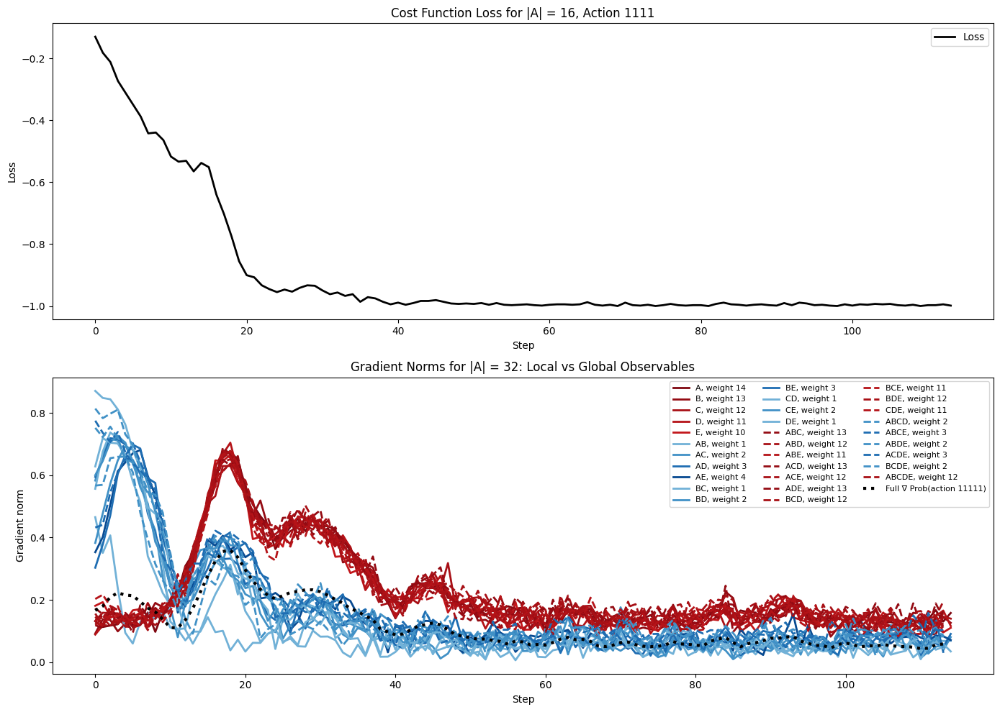

In [ ]:
# ============================================================

# 7. Plot loss and gradient norms with local/global color families

# ============================================================

# We classify by Pauli weight.

# Local: low-weight strings, e.g. 1, 2, 3, 4

# Global: high-weight strings, e.g. near n_qubits

# Intermediate: anything else, if it appears

weights = {

    label: len(wires)

    for label, wires in zip(observable_labels, observable_wires)

}

max_weight = max(weights.values())

min_weight = min(weights.values())

global_cmap = cm.get_cmap("Reds")

local_cmap = cm.get_cmap("Blues")

middle_cmap = cm.get_cmap("Purples")

def color_for_weight(weight):

    """

    Color convention:

        blue   -> local / low-weight terms

        purple -> intermediate terms

        red    -> global / high-weight terms

    """

    if weight <= 4:

        # local family

        # darker blue for larger local support

        t = 0.35 + 0.55 * (weight / 4)

        return local_cmap(t)

    elif weight >= n_qubits // 2:

        # global family

        # darker red for more global support

        t = 0.35 + 0.60 * (weight / n_qubits)

        return global_cmap(t)

    else:

        # intermediate family

        t = 0.55

        return middle_cmap(t)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

# Loss plot

ax1.plot(loss16, label="Loss", color="black", linewidth=2)

ax1.set_xlabel("Step")

ax1.set_ylabel("Loss")

ax1.set_title("Cost Function Loss for |A| = 16, Action 1111")

ax1.legend()

# Gradient norm plot

for label in observable_labels:

    weight = weights[label]

    linestyle = "-" if len(label) <= 2 else "--"

    ax2.plot(

        grad_norms[label],

        label=f"{label}, weight {weight}",

        color=color_for_weight(weight),

        linewidth=2,

        linestyle=linestyle,

    )

# Full action-probability gradient reference

ax2.plot(

    grad_prob_1111_list,

    label="Full ∇ Prob(action 11111)",

    color="black",

    linewidth=3,

    linestyle=":",

)

ax2.set_xlabel("Step")

ax2.set_ylabel("Gradient norm")

ax2.set_title("Gradient Norms for |A| = 32: Local vs Global Observables")

ax2.legend(ncol=3, fontsize=8)

plt.tight_layout()

plt.show()

### Softmax parity-like

n_actions: 16
target_action: 15
target_bits: [1, 1, 1, 1]

Observable order:
 0: A      | weight=14 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13] | obs=ZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13
 1: B      | weight=13 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12] | obs=ZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12
 2: C      | weight=12 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11] | obs=ZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11
 3: D      | weight=11 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10] | obs=ZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10
 4: AB     | weight= 1 | wires=[13] | obs=Z 13
 5: AC     | weight= 2 | wires=[12, 13] | obs=ZZ 12 13
 6: AD     | weight= 3 | wires=[11, 12, 13] | obs=ZZZ 11 12 13
 7: BC     | weight= 1 | wires=[12] | obs=Z 12
 8: BD     | weight= 2 | wires=[11, 12] | obs=ZZ 11 12
 9: CD     | weight= 1 | wires=[11] | obs=Z 11
10: ABC    | weight=13 | wires=[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13] | obs=ZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 13
11: ABD   

KeyboardInterrupt: 

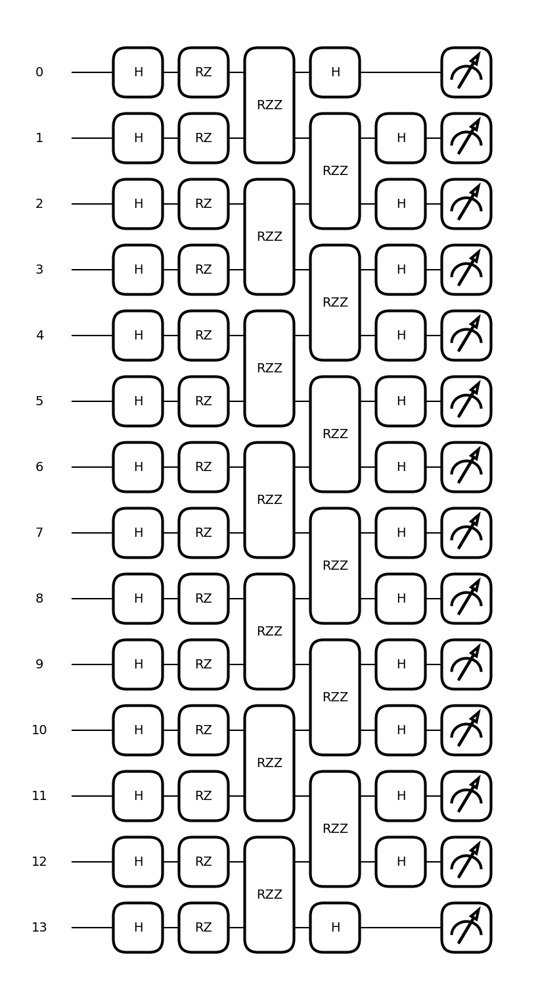

In [ ]:
from pennylane import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from itertools import combinations


# ============================================================
# 1. Helper functions
# ============================================================

def z_string(wires):
    """
    Convert a list of wires into your QASP observable string format.

    Example:
        wires = [0, 1, 3]
        returns "ZZZ 0 1 3"
    """
    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)


def xor_product_wires(list_of_wire_sets):
    """
    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.
    This returns the symmetric difference of all wire sets.
    """
    counts = {}

    for wires in list_of_wire_sets:
        for w in wires:
            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]
    return sorted(product_wires)


def build_parity_observables(n_qubits, n_action_bits):
    """
    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    Base generators:

        A = Z0 Z1 ... Z_{n-1}
        B = Z0 Z1 ... Z_{n-2}
        C = Z0 Z1 ... Z_{n-3}
        D = Z0 Z1 ... Z_{n-4}
        ...

    Then all nontrivial products of these generators.

    Returns:
        observable_labels
        observable_wires
        observables
        subsets
    """
    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    base_wires = [
        list(range(n_qubits - i))
        for i in range(n_action_bits)
    ]

    observable_labels = []
    observable_wires = []
    observables = []
    subsets = []

    for r in range(1, n_action_bits + 1):
        for subset in combinations(range(n_action_bits), r):
            label = "".join(base_labels[i] for i in subset)
            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)
            observable_wires.append(wires)
            observables.append(z_string(wires))
            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets


def action_index_to_bits(action_index, n_action_bits):
    """
    Convert action index to binary bits.

    Example:
        action_index = 15, n_action_bits = 4
        returns [1, 1, 1, 1]
    """
    bitstring = format(action_index, f"0{n_action_bits}b")
    return [int(b) for b in bitstring]


def stable_softmax(logits):
    """
    Numerically stable softmax.
    """
    shifted = logits #- qml.math.max(logits)
    exp_shifted = qml.math.exp(shifted)
    return exp_shifted / qml.math.sum(exp_shifted)


def parity_sign_matrix(n_action_bits, subsets):
    """
    Optional parity-structured initialization matrix.

    Shape:
        (n_actions, n_features)

    Entry:
        sign_matrix[a, ell] = product of signs for feature ell and action a.
    """
    n_actions = 2 ** n_action_bits
    sign_matrix = []

    for a in range(n_actions):
        bits = action_index_to_bits(a, n_action_bits)

        signs = [
            1 if bit == 0 else -1
            for bit in bits
        ]

        row = []

        for subset in subsets:
            coeff = 1
            for i in subset:
                coeff *= signs[i]
            row.append(coeff)

        sign_matrix.append(row)

    return np.array(sign_matrix, requires_grad=False)


# ============================================================
# 2. Main configuration
# ============================================================

n_qubits = 14

# Change this to 2, 3, 4, 5 for |A| = 4, 8, 16, 32
n_action_bits = 4
n_actions = 2 ** n_action_bits

# Target action: all ones
target_action = n_actions - 1
target_bits = action_index_to_bits(target_action, n_action_bits)

print("n_actions:", n_actions)
print("target_action:", target_action)
print("target_bits:", target_bits)


# ============================================================
# 3. Build parity expectation-value features
# ============================================================

observable_labels, observable_wires, observables, subsets = build_parity_observables(
    n_qubits=n_qubits,
    n_action_bits=n_action_bits,
)

n_features = len(observables)

print("\nObservable order:")
for i, (label, wires, obs) in enumerate(zip(observable_labels, observable_wires, observables)):
    print(f"{i:2d}: {label:6s} | weight={len(wires):2d} | wires={wires} | obs={obs}")

print("\nn_features:", n_features)


# ============================================================
# 4. Build IQP ansatz and initialize PQC parameters
# ============================================================

fm = None

imprimitive_pattern = (
    [(i, i + 1) for i in range(0, n_qubits - 1, 2)]
    + [(i, i + 1) for i in range(1, n_qubits - 1, 2)]
)

iqp = IQPAnsatz(
    n_qubits=n_qubits,
    imprimitive_pattern=imprimitive_pattern,
    n_layers=1,
    feature_map=fm,
    reuploading=False,
)

# Robust parameter initialization.
# Your QASP ansatz checks against iqp.n_layers * iqp._block_size.
#expected_total = iqp.n_layers * iqp._block_size
shapes = iqp.get_param_shapes()
expected_total = shapes[0]
pqc_params = np.random.uniform(
    low=-np.pi,
    high=np.pi,
    size=expected_total,
    requires_grad=True,
)

print("\nPQC parameter diagnostics:")
print("get_param_shapes():", iqp.get_param_shapes())
print("expected_total:", expected_total)
print("pqc_params.shape:", pqc_params.shape)
print("pqc_params requires_grad:", getattr(pqc_params, "requires_grad", None))


# ============================================================
# 5. Build and compile QASP circuit
# ============================================================

builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)

builder.set_measurement(
    "expectation",
    observables=observables,
    wires=list(range(n_qubits)),
)

circuit = builder.build()

qtape = builder.compile(
    cut_circuit=False,
    device="lightning.kokkos",
    shots=int(round(14 ** 2.5)),
)

# Optional drawing
qml.draw_mpl(circuit)(params=pqc_params)


# ============================================================
# 6. Initialize full action-specific softmax head
# ============================================================

# Option 1: small random initialization
head_W_init = 0.01 * np.random.normal(
    loc=0.0,
    scale=1.0,
    size=(n_actions, n_features),
)

head_W = np.array(
    head_W_init,
    requires_grad=True,
)

head_b = np.array(
    np.zeros(shape=(n_actions,)),
    requires_grad=True,
)

# Option 2: parity-structured initialization
# Uncomment this block if you want to initialize close to the parity sign structure.
#
# beta = 0.1
# sign_matrix = parity_sign_matrix(n_action_bits, subsets)
#
# head_W = np.array(
#     beta * sign_matrix + 0.01 * np.random.normal(
#         loc=0.0,
#         scale=1.0,
#         size=(n_actions, n_features),
#     ),
#     requires_grad=True,
# )
#
# head_b = np.array(
#     np.zeros(shape=(n_actions,)),
#     requires_grad=True,
# )

print("\nSoftmax head diagnostics:")
print("head_W.shape:", head_W.shape)
print("head_b.shape:", head_b.shape)
print("head_W requires_grad:", getattr(head_W, "requires_grad", None))
print("head_b requires_grad:", getattr(head_b, "requires_grad", None))


# ============================================================
# 7. Softmax policy functions
# ============================================================

def expvals_fn(pqc_params):
    """
    Quantum feature vector x = [<O_1>, ..., <O_M>].
    """
    return qml.math.stack(qtape(pqc_params))


def logits_from_features(expvals, head_W, head_b):
    """
    Full action-specific linear softmax head.

        logits[a] = b[a] + sum_l W[a,l] expvals[l]

    Shapes:
        expvals: (n_features,)
        head_W: (n_actions, n_features)
        head_b: (n_actions,)
        logits: (n_actions,)
    """
    return head_b + qml.math.dot(head_W, expvals)


def policy_probs(pqc_params, head_W, head_b):
    """
    PQC params -> expectation values -> action logits -> softmax probabilities.
    """
    expvals = expvals_fn(pqc_params)
    logits = logits_from_features(expvals, head_W, head_b)
    probs = stable_softmax(logits)
    return probs


def target_action_probability(pqc_params, head_W, head_b):
    """
    Probability of the target action under the softmax policy.
    """
    probs = policy_probs(pqc_params, head_W, head_b)
    return probs[target_action]


def cost_function(pqc_params, head_W, head_b):
    """
    Maximize pi(target_action), so minimize -pi(target_action).
    """
    return -target_action_probability(pqc_params, head_W, head_b)


# ============================================================
# 8. Initial checks
# ============================================================

initial_probs = policy_probs(pqc_params, head_W, head_b)

print("\nInitial policy:")
for a in range(n_actions):
    bits = action_index_to_bits(a, n_action_bits)
    print(f"action {a:2d}, bits={bits}, pi={initial_probs[a]}")

print("\nInitial target probability:", initial_probs[target_action])

# Check gradients before training.
# This verifies that PennyLane sees all three trainable arguments.
grad_test = qml.grad(
    cost_function,
    argnum=[0, 1, 2],
)(
    pqc_params,
    head_W,
    head_b,
)

print("\nGradient test for cost_function:")
print("||grad pqc_params||:", np.linalg.norm(grad_test[0]))
print("||grad head_W||:", np.linalg.norm(grad_test[1]))
print("||grad head_b||:", np.linalg.norm(grad_test[2]))


# ============================================================
# 9. Training loop
# ============================================================

opt = qml.AdamOptimizer(stepsize=0.1)
steps = 400

loss_softmax = []
prob_target_list = []

# Observable gradient norms w.r.t. PQC parameters only
grad_norms = {
    label: []
    for label in observable_labels
}

# Full target-policy gradient norms
grad_cost_pqc_list = []
grad_cost_W_list = []
grad_cost_b_list = []

# Parameter update magnitudes
delta_pqc_list = []
delta_W_list = []
delta_b_list = []

for step in range(steps):

    # Keep copies to verify updates
    old_pqc_params = np.array(pqc_params, requires_grad=False)
    old_head_W = np.array(head_W, requires_grad=False)
    old_head_b = np.array(head_b, requires_grad=False)

    # --------------------------------------------------------
    # Individual observable gradients w.r.t. PQC parameters
    # --------------------------------------------------------
    for i, label in enumerate(observable_labels):
        grad_i = qml.grad(lambda p, idx=i: qtape(p)[idx])(pqc_params)
        grad_norms[label].append(np.linalg.norm(grad_i))

    # --------------------------------------------------------
    # Gradient of the full cost w.r.t. all trainable arguments
    # --------------------------------------------------------
    grad_cost = qml.grad(
        cost_function,
        argnum=[0, 1, 2],
    )(
        pqc_params,
        head_W,
        head_b,
    )

    grad_cost_pqc = grad_cost[0]
    grad_cost_W = grad_cost[1]
    grad_cost_b = grad_cost[2]

    grad_cost_pqc_list.append(np.linalg.norm(grad_cost_pqc))
    grad_cost_W_list.append(np.linalg.norm(grad_cost_W))
    grad_cost_b_list.append(np.linalg.norm(grad_cost_b))

    # --------------------------------------------------------
    # Optimization step
    # --------------------------------------------------------
    (pqc_params, head_W, head_b), curr_loss = opt.step_and_cost(
        cost_function,
        pqc_params,
        head_W,
        head_b,
    )

    curr_prob = -curr_loss

    loss_softmax.append(curr_loss)
    prob_target_list.append(curr_prob)

    # --------------------------------------------------------
    # Check update magnitudes
    # --------------------------------------------------------
    delta_pqc = np.linalg.norm(pqc_params - old_pqc_params)
    delta_W = np.linalg.norm(head_W - old_head_W)
    delta_b = np.linalg.norm(head_b - old_head_b)

    delta_pqc_list.append(delta_pqc)
    delta_W_list.append(delta_W)
    delta_b_list.append(delta_b)

    print(
        f"Step {step + 1}/{steps}, "
        f"Loss: {curr_loss}, "
        f"pi(target={target_action}, bits={target_bits}): {curr_prob}, "
        f"||grad PQC||: {grad_cost_pqc_list[-1]}, "
        f"||grad W||: {grad_cost_W_list[-1]}, "
        f"||grad b||: {grad_cost_b_list[-1]}, "
        f"ΔPQC: {delta_pqc}, "
        f"ΔW: {delta_W}, "
        f"Δb: {delta_b}"
    )


# ============================================================
# 10. Inspect final policy
# ============================================================

final_probs = policy_probs(pqc_params, head_W, head_b)

print("\nFinal policy:")
for a in range(n_actions):
    bits = action_index_to_bits(a, n_action_bits)
    print(f"action {a:2d}, bits={bits}, pi={final_probs[a]}")

print("\nFinal target probability:", final_probs[target_action])






In [ ]:
final_probs = policy_probs(pqc_params, head_W, head_b)

print("\nFinal policy:")
for a in range(n_actions):
    bits = action_index_to_bits(a, n_action_bits)
    print(f"action {a:2d}, bits={bits}, pi={final_probs[a]}")

print("\nFinal target probability:", final_probs[target_action])




Final policy:
action  0, bits=[0, 0, 0, 0], pi=1.435122661214374e-07
action  1, bits=[0, 0, 0, 1], pi=1.458376750740374e-07
action  2, bits=[0, 0, 1, 0], pi=1.42616338736617e-07
action  3, bits=[0, 0, 1, 1], pi=1.4622640758893607e-07
action  4, bits=[0, 1, 0, 0], pi=1.448668444350442e-07
action  5, bits=[0, 1, 0, 1], pi=1.3987871743675357e-07
action  6, bits=[0, 1, 1, 0], pi=1.418510772346256e-07
action  7, bits=[0, 1, 1, 1], pi=1.399423590662018e-07
action  8, bits=[1, 0, 0, 0], pi=1.412322919217297e-07
action  9, bits=[1, 0, 0, 1], pi=1.4248074635486413e-07
action 10, bits=[1, 0, 1, 0], pi=1.4290231016118047e-07
action 11, bits=[1, 0, 1, 1], pi=1.435520338238453e-07
action 12, bits=[1, 1, 0, 0], pi=1.4467160699492393e-07
action 13, bits=[1, 1, 0, 1], pi=1.4022063310682643e-07
action 14, bits=[1, 1, 1, 0], pi=1.4059433510827142e-07
action 15, bits=[1, 1, 1, 1], pi=0.9999978596143568

Final target probability: 0.9999978596143568


In [ ]:
final_probs = policy_probs(np.zeros_like(pqc_params), head_W, head_b)

print("\nFinal policy:")
for a in range(n_actions):
    bits = action_index_to_bits(a, n_action_bits)
    print(f"action {a:2d}, bits={bits}, pi={final_probs[a]}")

print("\nFinal target probability:", final_probs[target_action])




Final policy:
action  0, bits=[0, 0, 0, 0], pi=0.06444393176895462
action  1, bits=[0, 0, 0, 1], pi=0.0686225119752759
action  2, bits=[0, 0, 1, 0], pi=0.06785944626747811
action  3, bits=[0, 0, 1, 1], pi=0.06475798410815134
action  4, bits=[0, 1, 0, 0], pi=0.06829666112554293
action  5, bits=[0, 1, 0, 1], pi=0.06293852623430887
action  6, bits=[0, 1, 1, 0], pi=0.06899853786411468
action  7, bits=[0, 1, 1, 1], pi=0.06536183391315607
action  8, bits=[1, 0, 0, 0], pi=0.0667084611810439
action  9, bits=[1, 0, 0, 1], pi=0.0737738537188713
action 10, bits=[1, 0, 1, 0], pi=0.06346128279700941
action 11, bits=[1, 0, 1, 1], pi=0.06669175496315691
action 12, bits=[1, 1, 0, 0], pi=0.06629338881808973
action 13, bits=[1, 1, 0, 1], pi=0.06306728262069268
action 14, bits=[1, 1, 1, 0], pi=0.06506988539820761
action 15, bits=[1, 1, 1, 1], pi=0.003654657245945975

Final target probability: 0.003654657245945975


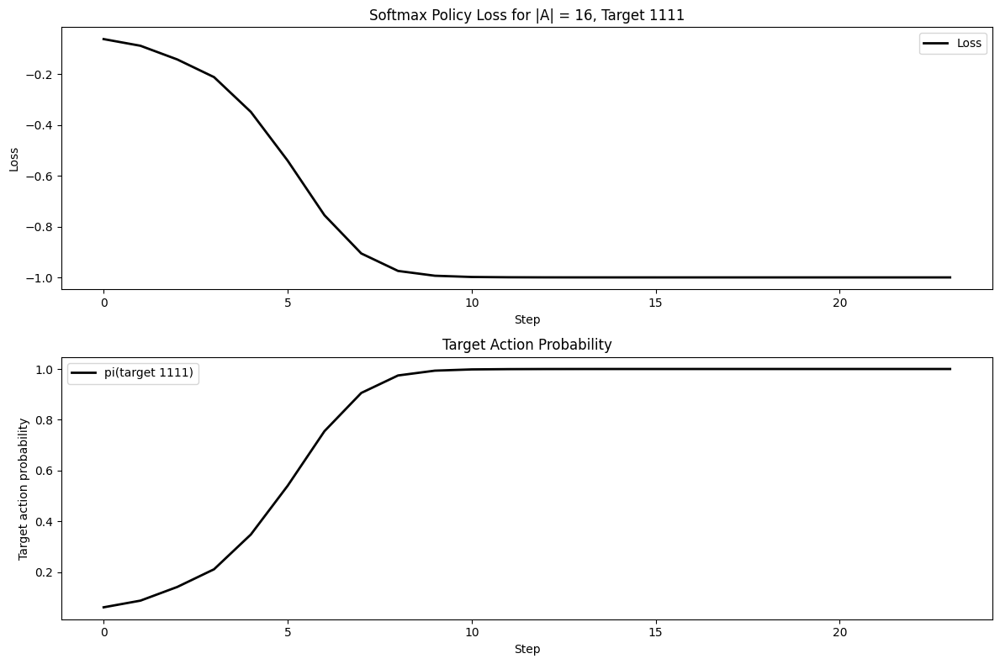

/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3683742023.py:32: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  global_cmap = cm.get_cmap("Reds")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3683742023.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  local_cmap = cm.get_cmap("Blues")
/var/folders/n9/tdqdt7991733xw39nzh49y600000gn/T/ipykernel_29545/3683742023.py:34: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  middle_cmap

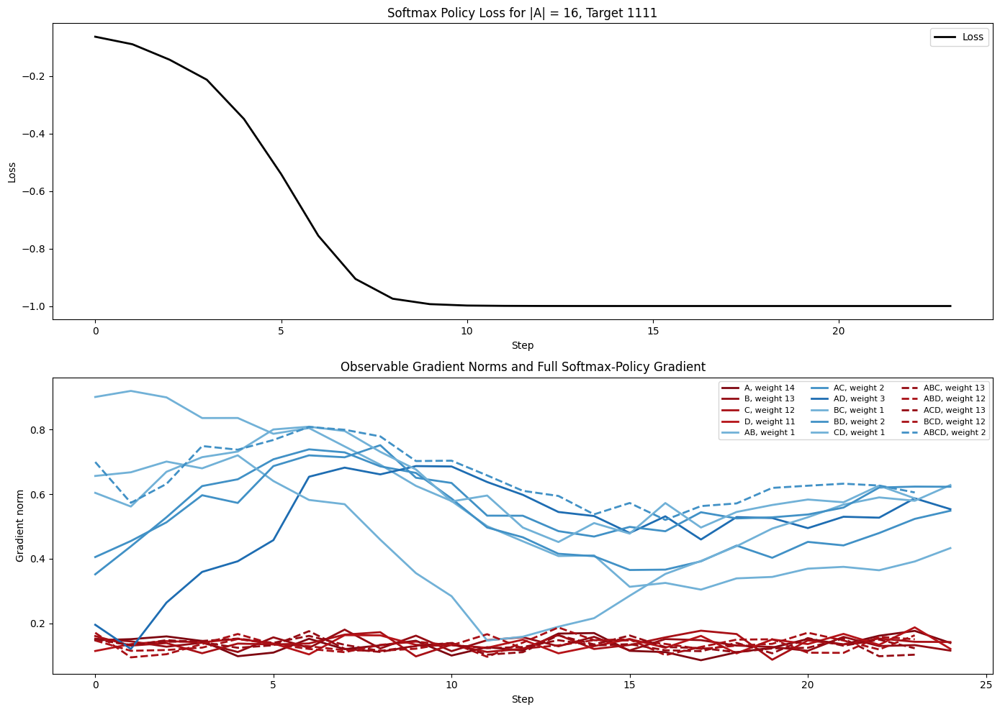

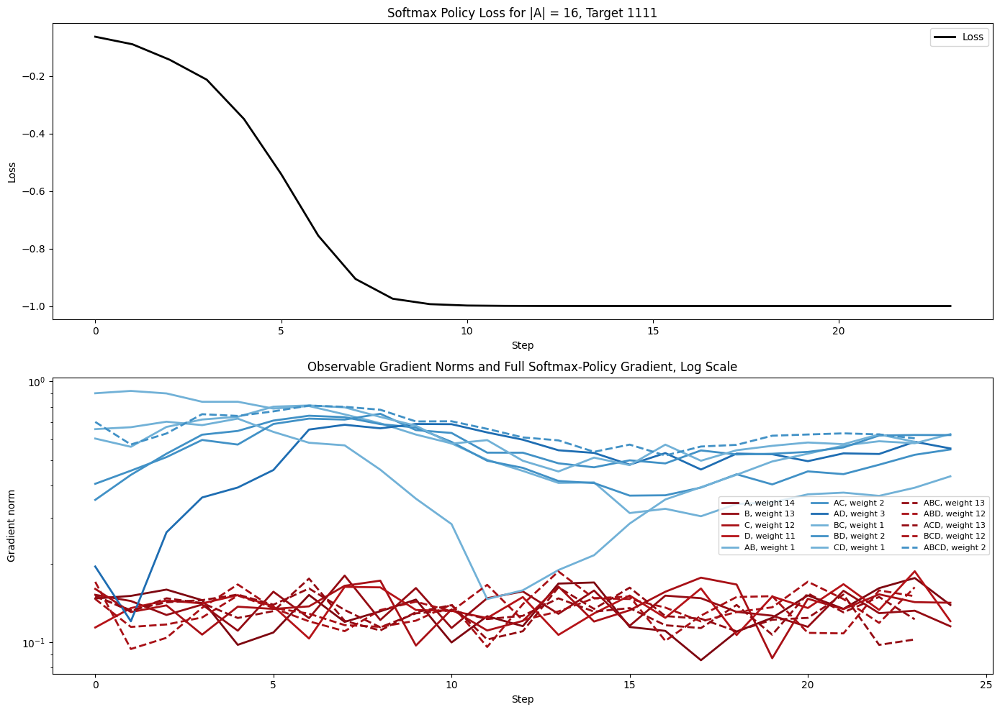

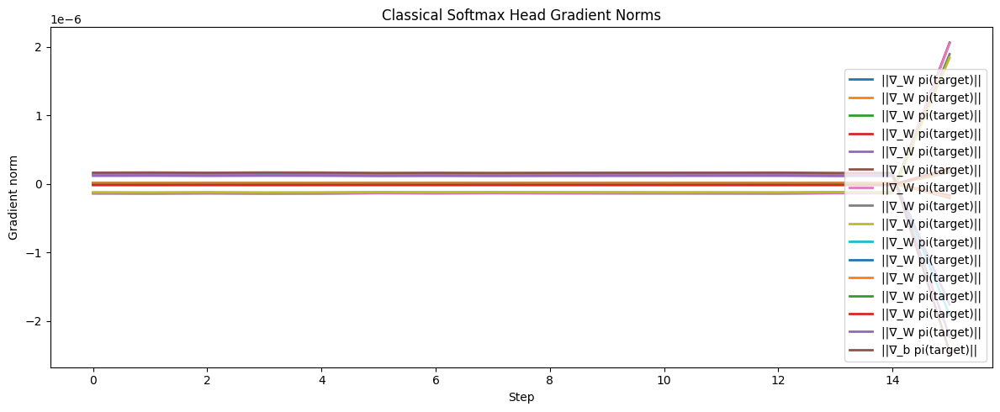

In [ ]:

# ============================================================
# 10. Plot loss and target probability
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8))

ax1.plot(loss_softmax, label="Loss", color="black", linewidth=2)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title(f"Softmax Policy Loss for |A| = {n_actions}, Target {''.join(map(str, target_bits))}")
ax1.legend()

ax2.plot(prob_target_list, label=f"pi(target {''.join(map(str, target_bits))})", color="black", linewidth=2)
ax2.set_xlabel("Step")
ax2.set_ylabel("Target action probability")
ax2.set_title("Target Action Probability")
ax2.legend()

plt.tight_layout()
plt.show()


# ============================================================
# 11. Plot observable gradient norms: local vs global
# ============================================================

weights = {
    label: len(wires)
    for label, wires in zip(observable_labels, observable_wires)
}

global_cmap = cm.get_cmap("Reds")
local_cmap = cm.get_cmap("Blues")
middle_cmap = cm.get_cmap("Purples")

def color_for_weight(weight):
    """
    Color convention:
        blue   -> local / low-weight observables
        purple -> intermediate observables
        red    -> global / high-weight observables
    """
    if weight <= 4:
        t = 0.35 + 0.55 * (weight / 4)
        return local_cmap(t)

    elif weight >= n_qubits // 2:
        t = 0.35 + 0.60 * (weight / n_qubits)
        return global_cmap(t)

    else:
        return middle_cmap(0.60)


fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

ax1.plot(loss_softmax, label="Loss", color="black", linewidth=2)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title(f"Softmax Policy Loss for |A| = {n_actions}, Target {''.join(map(str, target_bits))}")
ax1.legend()

for label in observable_labels:
    weight = weights[label]

    linestyle = "-" if len(label) <= 2 else "--"

    ax2.plot(
        grad_norms[label],
        label=f"{label}, weight {weight}",
        color=color_for_weight(weight),
        linewidth=2,
        linestyle=linestyle,
    )



ax2.set_xlabel("Step")
ax2.set_ylabel("Gradient norm")
ax2.set_title("Observable Gradient Norms and Full Softmax-Policy Gradient")
ax2.legend(ncol=3, fontsize=8)

plt.tight_layout()
plt.show()


# ============================================================
# 12. Log-scale gradient plot
# ============================================================

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10))

ax1.plot(loss_softmax, label="Loss", color="black", linewidth=2)
ax1.set_xlabel("Step")
ax1.set_ylabel("Loss")
ax1.set_title(f"Softmax Policy Loss for |A| = {n_actions}, Target {''.join(map(str, target_bits))}")
ax1.legend()

for label in observable_labels:
    weight = weights[label]

    linestyle = "-" if len(label) <= 2 else "--"

    ax2.plot(
        grad_norms[label],
        label=f"{label}, weight {weight}",
        color=color_for_weight(weight),
        linewidth=2,
        linestyle=linestyle,
    )


ax2.set_yscale("log")
ax2.set_xlabel("Step")
ax2.set_ylabel("Gradient norm")
ax2.set_title("Observable Gradient Norms and Full Softmax-Policy Gradient, Log Scale")
ax2.legend(ncol=3, fontsize=8)

plt.tight_layout()
plt.show()


# ============================================================
# 13. Plot classical head gradient norms
# ============================================================

fig, ax = plt.subplots(1, 1, figsize=(12, 5))

ax.plot(grad_cost_W, label="||∇_W pi(target)||", linewidth=2)
ax.plot(grad_cost_b, label="||∇_b pi(target)||", linewidth=2)

ax.set_xlabel("Step")
ax.set_ylabel("Gradient norm")
ax.set_title("Classical Softmax Head Gradient Norms")
ax.legend()

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
qtape = builder.compile(cut_circuit=False,device="lightning.kokkos", shots=int(round(n_qubits**2)))
qtape(params)

qtape2 = builder2.compile(cut_circuit=False,device="lightning.kokkos", shots=int(round(n_qubits**2)))
qtape2(params)

(array(0.32),
 array(0.7),
 array(0.52),
 array(-0.16),
 array(-0.6),
 array(-0.5),
 array(-0.38),
 array(-0.48),
 array(0.96),
 array(0.5),
 array(0.26),
 array(0.24),
 array(-0.2),
 array(-0.16),
 array(-0.14),
 array(-0.1),
 array(-0.2),
 array(0.32),
 array(0.18),
 array(0.42),
 array(-0.1),
 array(-0.42),
 array(-0.28),
 array(-0.2),
 array(-0.3),
 array(0.66),
 array(0.4),
 array(-0.2),
 array(-0.44),
 array(-0.3),
 array(-0.18),
 array(-0.32),
 array(0.52),
 array(0.14),
 array(0.16),
 array(-0.1),
 array(0.1),
 array(0.12),
 array(-0.12),
 array(-0.1),
 array(0.5),
 array(0.3),
 array(0.32),
 array(-0.6),
 array(-0.3),
 array(0.24),
 array(0.18),
 array(-0.5),
 array(-0.16),
 array(0.62),
 array(-0.34),
 array(-0.12),
 array(-0.48),
 array(-0.18),
 array(0.46),
 array(0.06),
 array(-0.14),
 array(-0.14),
 array(-0.08),
 array(-0.08),
 array(-0.18),
 array(0.26),
 array(0.16),
 array(-0.16),
 array(-0.16),
 array(-0.18),
 array(-0.06),
 array(-0.2),
 array(0.28),
 array(0.06),
 

In [ ]:
#iqp2 = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)
#iqp = AngleAnsatz(n_qubits=len(wires), n_layers=1 , rotations = rotations , feature_map=None , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="chain", reuploading=False, include_hadamards_initial=True)

builder3 = CircuitBuilder(n_qubits=n_qubits)
builder3.set_ansatz(iqp)           # pass the IQPAnsatz instance

builder3.set_measurement("probs", wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit3 = builder3.build()

qtape3 = builder3.compile(cut_circuit=False,device="lightning.kokkos")

In [ ]:
probss=qtape3(params)

print(probss)
print(len(probss))
print(2**n_qubits)

[3.48243636e-04 1.18529100e-04 4.00628799e-06 ... 1.50161299e-03
 5.54352071e-05 4.78054884e-05]
1024
1024


In [ ]:
opt = qml.AdamOptimizer(stepsize=0.1)
steps=400

loss=[]
loss_analytical = []
params= params_copy
def cost_function(params):
    expvals = qtape(params)
    #sum expvals 
    prob = 1
    for expval in expvals:
        prob += expval
    prob = prob/(len_observables+1)
    loss = -prob
    return loss

for step in range(steps):


    #ste_and_cost 
    params, curr_loss = opt.step_and_cost(lambda p: cost_function(p), params)

    loss.append(curr_loss)

    curr_loss_analytical = qtape3(params)[0] # probability of all zeros state
    loss_analytical.append(curr_loss_analytical)
    print(f"Step {step+1}/{steps}, Loss: {curr_loss} , Analytical Loss: {curr_loss_analytical}")



Step 1/400, Loss: -0.15636363636363637 , Analytical Loss: 0.0009196932974754983
Step 2/400, Loss: -0.28 , Analytical Loss: 0.001954204175249922
Step 3/400, Loss: -0.31636363636363635 , Analytical Loss: 0.0035668332791362
Step 4/400, Loss: -0.4018181818181818 , Analytical Loss: 0.005855015511485728
Step 5/400, Loss: -0.4581818181818182 , Analytical Loss: 0.00905070124343687
Step 6/400, Loss: -0.4763636363636363 , Analytical Loss: 0.013444296098759911
Step 7/400, Loss: -0.5036363636363638 , Analytical Loss: 0.01760787441548521
Step 8/400, Loss: -0.5218181818181818 , Analytical Loss: 0.021811986362295574
Step 9/400, Loss: -0.5436363636363636 , Analytical Loss: 0.0270172170102682
Step 10/400, Loss: -0.5927272727272727 , Analytical Loss: 0.03283121008558649
Step 11/400, Loss: -0.6272727272727273 , Analytical Loss: 0.03826007655002197
Step 12/400, Loss: -0.6454545454545454 , Analytical Loss: 0.04388807907383995
Step 13/400, Loss: -0.649090909090909 , Analytical Loss: 0.0502658757481069
Step 

In [ ]:
opt = qml.AdamOptimizer(stepsize=0.1)
steps=400

loss2=[]
loss_analytical2 = []

params = params_copy

def cost_function(params):
    expvals = qtape2(params)
    #sum expvals 
    prob = 1
    for expval in expvals:
        prob += expval
    prob = prob/(len(observables2)+1)
    loss = -prob
    return loss

for step in range(steps):


    #ste_and_cost 
    params, curr_loss = opt.step_and_cost(lambda p: cost_function(p), params)

    loss2.append(curr_loss)

    curr_loss_analytical = qtape3(params)[0] # probability of all zeros state
    loss_analytical2.append(curr_loss_analytical)
    print(f"Step {step+1}/{steps}, Loss: {curr_loss} , Analytical Loss: {curr_loss_analytical}")



Step 1/400, Loss: -0.0026873385012919945 , Analytical Loss: 0.0005908513160711859
Step 2/400, Loss: -0.001860465116279067 , Analytical Loss: 0.0008434824021719336
Step 3/400, Loss: -0.01689922480620157 , Analytical Loss: 0.0011890894174697718
Step 4/400, Loss: -0.00382428940568478 , Analytical Loss: 0.001525874310772439
Step 5/400, Loss: -0.017157622739018167 , Analytical Loss: 0.0022148920547858018
Step 6/400, Loss: -0.04289405684754525 , Analytical Loss: 0.004085716991646295
Step 7/400, Loss: -0.04428940568475448 , Analytical Loss: 0.007436046391429264
Step 8/400, Loss: -0.05488372093023256 , Analytical Loss: 0.012037185493343212
Step 9/400, Loss: -0.06645994832041342 , Analytical Loss: 0.020018311070030825
Step 10/400, Loss: -0.12361757105943146 , Analytical Loss: 0.03377849355274271
Step 11/400, Loss: -0.08537467700258397 , Analytical Loss: 0.05565466822564968
Step 12/400, Loss: -0.18883720930232564 , Analytical Loss: 0.08695980333822584
Step 13/400, Loss: -0.2431007751937988 , Ana

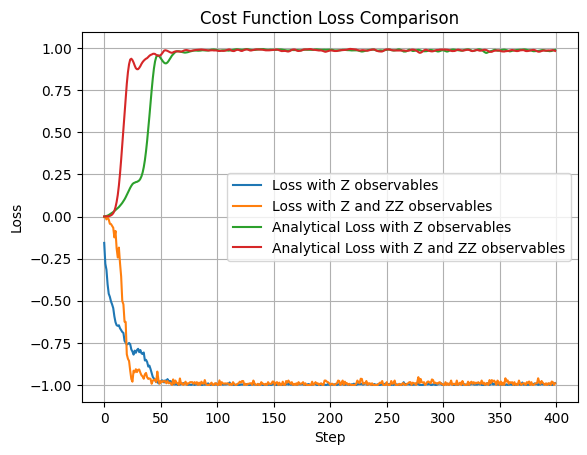

In [ ]:
plt.plot(loss, label='Loss with Z observables')
plt.plot(loss2, label='Loss with Z and ZZ observables')
plt.plot(loss_analytical, label='Analytical Loss with Z observables')
plt.plot(loss_analytical2, label='Analytical Loss with Z and ZZ observables')
plt.xlabel('Step')
plt.ylabel('Loss')      
plt.title('Cost Function Loss Comparison')
plt.legend()
plt.grid()
plt.show()

#### Variance of local-like policy with all to all two qubit pairs and initialized with normal_0_1

In [ ]:
n_qubits_measurement_list = [3,4,5,6,7,8]
samples = 2000 

def cost_function(qtape, params, observables,n):
    expvals = qtape(params)
    #sum expvals 
    prob = 1
    c=1
    for expval in expvals:
        if c <= n:
             prob -= expval
        else:
            prob += expval
        c+=1
    prob = prob/(len(observables)+1)
    return prob

variances_qubit_global=[]
variances_qubit_local=[]
for n_qubits_measurement in n_qubits_measurement_list:
    losses_qubit_global=[]
    losses_qubit_local=[]
    print("Starting sampling for {} measurement qubits...".format(n_qubits_measurement))
    for s in range(samples):
        n_qubits = 2 * n_qubits_measurement + 1
        fm=None
        imprimitive_pattern = [(i, j) for i in range(n_qubits_measurement) for j in range(i+1, n_qubits)]
        iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)
        #iqp = AngleAnsatz(n_qubits=len(wires), n_layers=1 , rotations = rotations , feature_map=None , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="chain", reuploading=False, include_hadamards_initial=True)

        # 2. Query the parameter shapes so you know how to init your params
        shapes = iqp.get_param_shapes()  
        # Create a params array matching that shape

        # Create input scaling params array matching that shape
        #params = np.random.uniform(
        #    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
        #)
        #params=p[:-1]
        # 3. Build your circuit
        builder = CircuitBuilder(n_qubits=n_qubits)
        builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
        builder.set_measurement("probs", wires=list(range(n_qubits_measurement)))  # measure the expectation value of the global Z operator
        circuit = builder.build()
        #qml.draw_mpl(circuit)(params=params)    
        qtape = builder.compile(cut_circuit=False,device="lightning.kokkos")#, shots=int(round(n_qubits**2)))

        #create new circuit with observables Z + ZZ
        observables = ["Z {}".format(i) for i in range(n_qubits_measurement)]
        observables += ["ZZ {} {}".format(i, j) for i in range(n_qubits_measurement-1) for j in range(i+1, n_qubits_measurement)]
        #observables += ["ZZZ {} {} {}".format(i, j, k) for i in range(n_qubits_measurement) for j in range(i+1, n_qubits_measurement) for k in range(j+1, n_qubits_measurement)]
        #observables += ["ZZZZ {} {} {} {}".format(i, j, k, l) for i in range(n_qubits_measurement) for j in range(i+1, n_qubits_measurement) for k in range(j+1, n_qubits_measurement) for l in range(k+1, n_qubits_measurement)]
        #add global Z observable
        globalz = "Z"*n_qubits_measurement+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits_measurement))))
        observables += [globalz]

        builder2 = CircuitBuilder(n_qubits=n_qubits)  
        builder2.set_ansatz(iqp)           # pass the IQPAnsatz instance
        builder2.set_measurement("expectation",observables=observables, wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator

        circuit2 = builder2.build()
        #qml.draw_mpl(circuit)(params=params)    
        qtape2 = builder2.compile(cut_circuit=False,device="lightning.kokkos")#, shots=int(round(n_qubits**2)))

    
        params = np.random.normal(loc=0, scale=0.3, size=shapes[0], requires_grad=True)
        losses_qubit_global.append(qtape(params)[-1]) # probability of all zeros state

        losses_qubit_local.append(cost_function(qtape2, params, observables,n_qubits_measurement)) # probability of all zeros state

    variances_qubit_global.append(np.var(losses_qubit_global))
    variances_qubit_local.append(np.var(losses_qubit_local))
    

Starting sampling for 3 measurement qubits...
Starting sampling for 4 measurement qubits...
Starting sampling for 5 measurement qubits...
Starting sampling for 6 measurement qubits...
Starting sampling for 7 measurement qubits...
Starting sampling for 8 measurement qubits...


KeyboardInterrupt: 

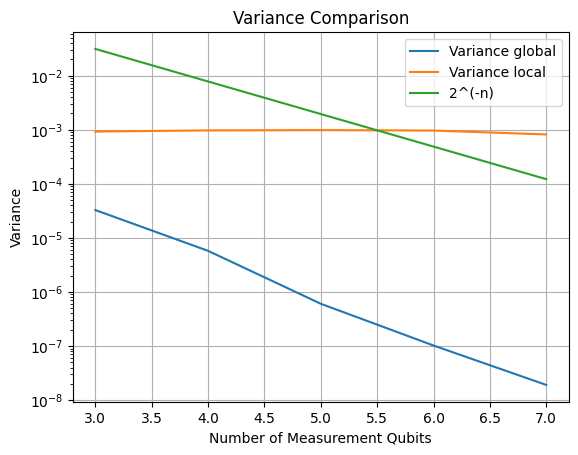

In [ ]:
plt.plot(n_qubits_measurement_list[:-1], variances_qubit_global, label='Variance global')
plt.plot(n_qubits_measurement_list[:-1], variances_qubit_local, label='Variance local')
plt.plot(n_qubits_measurement_list[:-1], [2**(-2*n+1) for n in n_qubits_measurement_list[:-1]], label='2^(-n)')
plt.yscale('log')
plt.xlabel('Number of Measurement Qubits')
plt.ylabel('Variance')
plt.title('Variance Comparison')
plt.legend()
plt.grid()
plt.show()


#### TEST softmax policy with trainable parity like observables 

In [ ]:
from qasp import *
import qasp
import torch 
from pennylane import numpy as np
import matplotlib.pyplot as plt

In [ ]:

n_qubits = 14
fm=None
imprimitive_pattern = [(i, i+1) for i in range(0,n_qubits-1,2)] + [(i, i+1) for i in range(1,n_qubits-1,2)]
iqp = IQPAnsatz(n_qubits=n_qubits, imprimitive_pattern=imprimitive_pattern, n_layers=1, feature_map=fm, reuploading=False)
#iqp = AngleAnsatz(n_qubits=len(wires), n_layers=1 , rotations = rotations , feature_map=None , include_imprimitive=False, imprimitive = "CNOT" , imprimitive_pattern="chain", reuploading=False, include_hadamards_initial=True)

# 2. Query the parameter shapes so you know how to init your params
shapes = iqp.get_param_shapes()  
# Create a params array matching that shape

# Create input scaling params array matching that shape
params = np.random.uniform(
    low=-np.pi, high=np.pi, size=shapes[0], requires_grad=True
) 
#params=p[:-1]
# 3. Build your circuit
builder = CircuitBuilder(n_qubits=n_qubits)
builder.set_ansatz(iqp)           # pass the IQPAnsatz instance
#create observable for the projector in the all ones state 
#[qml.Projector([1]*len(wires),wires=list(wires))]
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
builder.set_measurement("expectation",observables=[globalz,globalz2,zlast], wires=list(range(n_qubits)))  # measure the expectation value of the global Z operator
circuit = builder.build()

qtape = builder.compile(cut_circuit=False,device="lightning.kokkos")#, shots=int(round(n_qubits**2)))

In [ ]:
params

tensor([-1.8193266 , -2.32700536, -2.12229331, -1.134601  , -1.90807811,
        -0.56724877,  1.57107381,  1.0903667 ,  2.42241886, -2.8477076 ,
         2.53013104, -2.83716308, -0.50899127,  2.06223524,  1.472326  ,
         1.86559992, -1.31575653, -0.18627578, -0.43517472,  2.9714873 ,
        -2.24410401, -0.40551571, -2.40249902,  0.49536115,  2.53875924,
         1.42215251, -1.97843533], requires_grad=True)

In [ ]:
params_torch = torch.tensor(params, requires_grad=True)

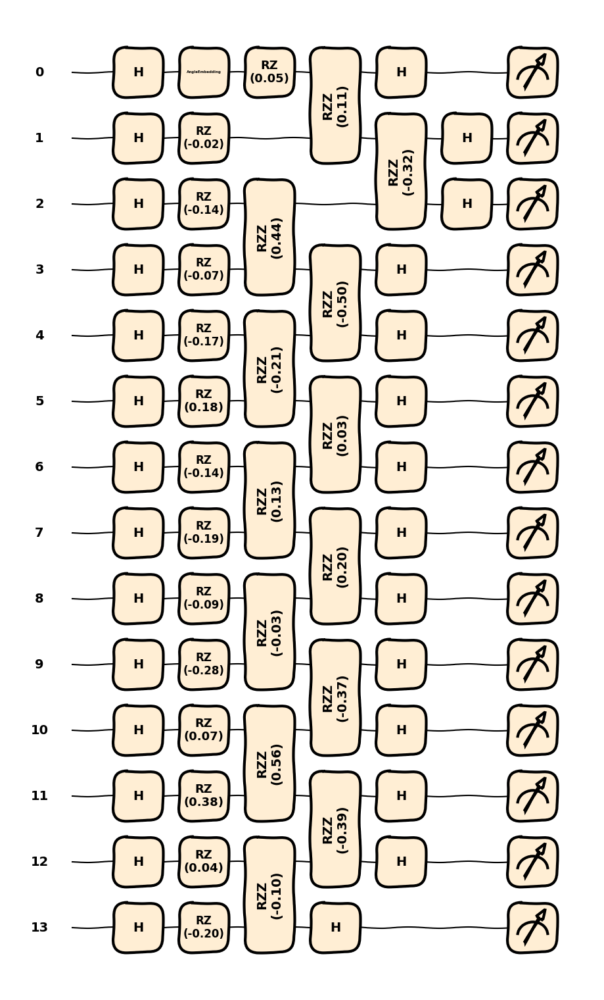

In [ ]:
n_qubits = 14
fm_config = {
    "features": 1,
    "rotations": "Z",
    #"imprimitive_pattern": "all_to_all",# [(i,j) for i in range(4) for j in range(i+1, 4)],
    #"imprimitive": "CZ",
    "input_scaling": False
}

ansatz_config = {
    "n_layers": 1,
    "imprimitive_pattern": [(i, i + 1) for i in range(0, n_qubits - 1, 2)] + [(i, i + 1) for i in range(1, n_qubits - 1, 2)],   
    "reuploading": False,
    # "include_imprimitive": True,
    # "imprimitive": "CNOT",
}

policy_model_config = {
    "ansatz": "IQPAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "AngleEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "fc_layer":True,
    "shots": None,
    "observables": [globalz,globalz2,zlast]
}


policy_model = create_model("PQCSoftmax", policy_model_config, n_qubits=n_qubits)
#policy2.qlayer.load_state_dict(policy1.qlayer.state_dict())
#print(policy2.qlayer.state_dict()["params"])

fig, ax = draw_model(model=policy_model,policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=1, inputs=torch.zeros(1))


In [ ]:
print(qtape(params))

(array(3.09984877e-07), array(4.09622659e-07), array(0.29426203))


In [ ]:
#load params_torch as dictionary to the qlayer of the policy model
policy_model.set_weights({"params": params_torch})

In [ ]:
policy_model.forward(torch.zeros(1))

tensor([3.0994e-07, 4.0956e-07, 2.9426e-01], grad_fn=<ViewBackward0>)


tensor([0.6267, 0.3733], grad_fn=<SoftmaxBackward0>)

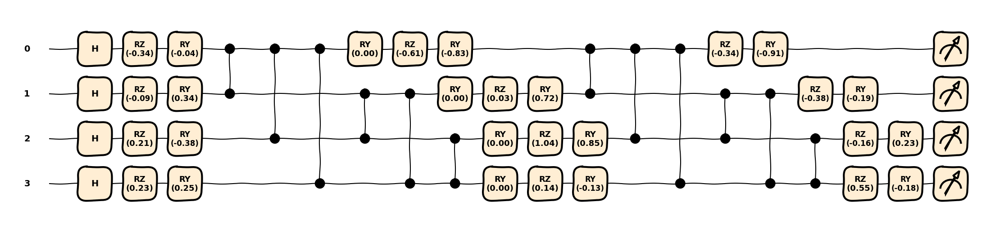

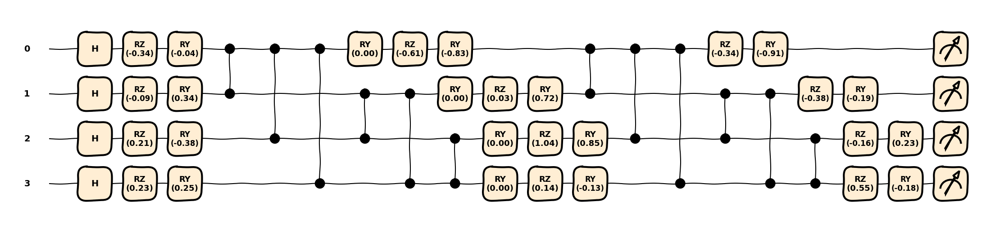

In [ ]:
n_qubits = 4
fm_config = {
    "features": 4,
    "rotations": "Y",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}

policy_model_config_sm_activation = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": True,
    "output_scaling": True,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}

pqc_parity_like = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
pqc_parity_lik_sm = create_model("PQCBorn", policy_model_config_sm_activation, n_qubits=n_qubits)
fig, ax = draw_model(
    model=pqc_parity_like,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)

globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
for i in range(n_qubits-1):
    for j in range(i+1, n_qubits):
        observables.append("ZZ {} {}".format(i, j))

observables.append(globalz)
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "fc_layer":True,
    #"shots": int(n_qubits**(2))
    "observables": observables
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)
pqc_softmax.qlayer.load_state_dict(pqc_parity_like.qlayer.state_dict())
pqc_parity_lik_sm.qlayer.load_state_dict(pqc_parity_like.qlayer.state_dict())

fig, ax = draw_model(model=pqc_softmax,policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))



In [ ]:
#print every parameter of every model to check they are the same
print("PQC Parity-like parameters:")
for name, param in pqc_parity_like.named_parameters():
    print(f"{name}: {param.data}")  
print("\nPQC Parity-like with Softmax parameters:")
for name, param in pqc_parity_lik_sm.named_parameters():
    print(f"{name}: {param.data}")
print("\nPQC Softmax parameters:")          
for name, param in pqc_softmax.named_parameters():
    print(f"{name}: {param.data}")     
    

PQC Parity-like parameters:
qlayer.input_scaling_params: tensor([-0.3670,  0.4727,  0.4473, -0.5707, -0.4330,  0.2973,  0.7485, -0.4750,
        -0.6335,  0.2902,  0.3239,  0.3199,  0.0686,  0.9948, -0.1342,  0.1805,
         0.0781,  0.5458,  0.5650, -0.2544,  0.5691,  0.4358, -0.8542,  0.8045,
         0.6300, -0.0171, -0.3760,  0.6490, -0.7205,  0.0732,  1.0956, -0.6361,
        -0.7151, -0.4938,  0.1016,  0.2044,  0.6107, -0.2502,  0.0891,  0.5741,
        -0.2755,  0.2256,  0.0502, -0.5108, -0.8108,  0.3845, -0.4111, -0.4421])
qlayer.params: tensor([-0.2831, -0.2477, -0.3218,  0.1450, -0.4784,  0.1383,  1.0086,  0.1940,
        -0.6097,  0.1840, -0.2240, -0.6568,  0.0313,  0.0264, -0.0235,  0.2249,
        -1.0549,  1.4560, -0.5844, -0.1273,  0.0983, -0.6540,  0.4221,  0.5912])

PQC Parity-like with Softmax parameters:
output_scaling_weight: tensor([1.])
qlayer.input_scaling_params: tensor([-0.3670,  0.4727,  0.4473, -0.5707, -0.4330,  0.2973,  0.7485, -0.4750,
        -0.6335,  0

In [ ]:
'''
cfg = qasp.rl.torchrl.ReinforceConfig(
        env_name          = "CartPole-v0",
        n_episodes        = 500,
        n_batch           = 4,
        gamma             = 0.99,
        lr_policy         = 0.1,
        entropy_coef      = 0.01,
        grad_clip         = 1.0,
        normalise_state   = False,
        log_every         = 1,
        eval_every        = 50,
        # ── Baseline: pick one ──────────────────────────────────────────────
        baseline_type     = "mean_return",  # simple EMA of episode returns
        baseline_momentum = 0.05,           # EMA smoothing (ignored for "mlp")
        # baseline_type  = "mlp",           # state-dependent classical network
        # lr_baseline    = 1e-3,            # learning rate for mlp baseline
    )

trainer = qasp.rl.torchrl.Reinforce(pqc_parity_like, config=cfg)
results = trainer.train()
'''
agent = REINFORCE(

    policy=pqc_parity_like,

    env_name="CartPole-v0",

    gamma=0.99,

    lr=1e-1,

    batch_episodes=5,

    logits=False,

    normalize_mode="clip",

    normalize_returns=True,

    fc_layer=False

)

returns = agent.train(num_episodes=500)



/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 29.6
Episode 0020 | avg(return_last20) = 28.1
Episode 0030 | avg(return_last20) = 21.1
Episode 0040 | avg(return_last20) = 25.5
Episode 0050 | avg(return_last20) = 36.5
Episode 0060 | avg(return_last20) = 55.9
Episode 0070 | avg(return_last20) = 65.0
Episode 0080 | avg(return_last20) = 60.6
Episode 0090 | avg(return_last20) = 74.7
Episode 0100 | avg(return_last20) = 76.7
Episode 0110 | avg(return_last20) = 97.5
Episode 0120 | avg(return_last20) = 154.5
Episode 0130 | avg(return_last20) = 155.4
Episode 0140 | avg(return_last20) = 115.5
Episode 0150 | avg(return_last20) = 118.1
Episode 0160 | avg(return_last20) = 146.5
Episode 0170 | avg(return_last20) = 147.6
Episode 0180 | avg(return_last20) = 129.1
Episode 0190 | avg(return_last20) = 133.3
Episode 0200 | avg(return_last20) = 131.1
Episode 0210 | avg(return_last20) = 155.9
Episode 0220 | avg(return_last20) = 174.1
Episode 0230 | avg(return_last20) = 158.8
Episode 0240 | avg(return_last20) = 172.2
Epi

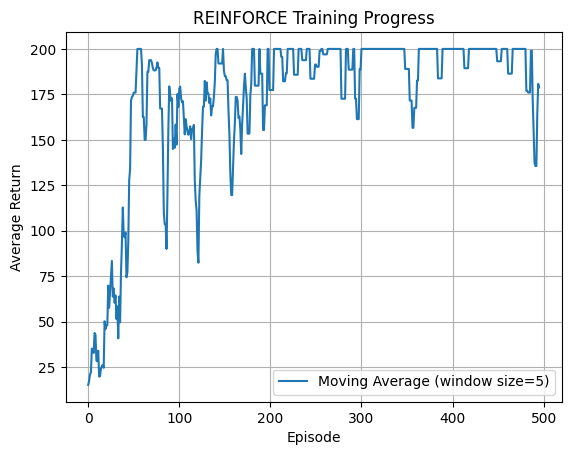

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(returns, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



In [ ]:
agent = REINFORCE(

    policy=pqc_softmax,

    env_name="CartPole-v0",

    gamma=0.99,

    lr=1e-1,

    batch_episodes=5,

    logits=False,

    normalize_mode="clip",

    normalize_returns=True,

    fc_layer=True

)

returns = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 20.8
Episode 0020 | avg(return_last20) = 20.8
Episode 0030 | avg(return_last20) = 21.6
Episode 0040 | avg(return_last20) = 25.6
Episode 0050 | avg(return_last20) = 27.3
Episode 0060 | avg(return_last20) = 26.7
Episode 0070 | avg(return_last20) = 31.8
Episode 0080 | avg(return_last20) = 34.6
Episode 0090 | avg(return_last20) = 30.5
Episode 0100 | avg(return_last20) = 45.4
Episode 0110 | avg(return_last20) = 51.1
Episode 0120 | avg(return_last20) = 53.0
Episode 0130 | avg(return_last20) = 76.7
Episode 0140 | avg(return_last20) = 100.8
Episode 0150 | avg(return_last20) = 103.8
Episode 0160 | avg(return_last20) = 104.6
Episode 0170 | avg(return_last20) = 138.6
Episode 0180 | avg(return_last20) = 171.4
Episode 0190 | avg(return_last20) = 188.8
Episode 0200 | avg(return_last20) = 194.0
Episode 0210 | avg(return_last20) = 192.2
Episode 0220 | avg(return_last20) = 183.5
Episode 0230 | avg(return_last20) = 184.1
Episode 0240 | avg(return_last20) = 187.7
Episo

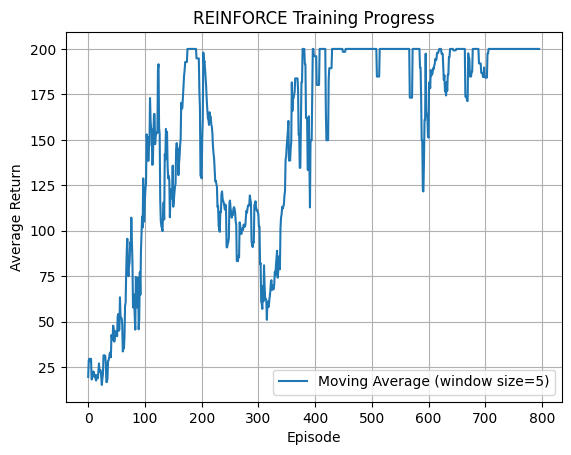

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(returns, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



In [ ]:
'''
cfg = qasp.rl.torchrl.ReinforceConfig(
        env_name          = "CartPole-v0",
        n_episodes        = 250,
        n_batch           = 4,
        gamma             = 0.99,
        lr_policy         = 0.1,
        entropy_coef      = 0.01,
        grad_clip         = 1.0,
        normalise_state   = False,
        log_every         = 1,
        eval_every        = 50,
        # ── Baseline: pick one ──────────────────────────────────────────────
        baseline_type     = "mean_return",  # simple EMA of episode returns
        baseline_momentum = 0.05,           # EMA smoothing (ignored for "mlp")
        # baseline_type  = "mlp",           # state-dependent classical network
        # lr_baseline    = 1e-3,            # learning rate for mlp baseline
        #fc_layer=True
    )

trainer = qasp.rl.torchrl.Reinforce(pqc_parity_lik_sm, config=cfg)
results = trainer.train()
'''
agent = REINFORCE(

    policy=pqc_parity_lik_sm,

    env_name="CartPole-v0",

    gamma=0.99,

    lr=1e-1,

    batch_episodes=5,

    logits=False,

    normalize_mode="clip",

    normalize_returns=True,

    fc_layer=False

)

returns = agent.train(num_episodes=800)



Episode 0010 | avg(return_last20) = 10.8
Episode 0020 | avg(return_last20) = 11.8
Episode 0030 | avg(return_last20) = 17.4
Episode 0040 | avg(return_last20) = 50.0
Episode 0050 | avg(return_last20) = 71.1
Episode 0060 | avg(return_last20) = 55.4
Episode 0070 | avg(return_last20) = 47.6
Episode 0080 | avg(return_last20) = 66.8
Episode 0090 | avg(return_last20) = 98.3
Episode 0100 | avg(return_last20) = 132.2
Episode 0110 | avg(return_last20) = 157.8
Episode 0120 | avg(return_last20) = 172.8
Episode 0130 | avg(return_last20) = 153.2
Episode 0140 | avg(return_last20) = 120.2
Episode 0150 | avg(return_last20) = 112.7
Episode 0160 | avg(return_last20) = 120.5
Episode 0170 | avg(return_last20) = 144.8
Episode 0180 | avg(return_last20) = 154.2
Episode 0190 | avg(return_last20) = 172.5
Episode 0200 | avg(return_last20) = 196.8
Episode 0210 | avg(return_last20) = 200.0
Episode 0220 | avg(return_last20) = 200.0
Episode 0230 | avg(return_last20) = 182.8
Episode 0240 | avg(return_last20) = 169.5
E

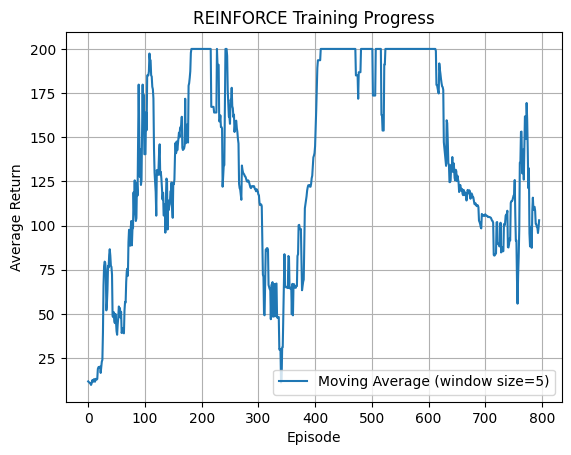

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(returns, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



In [ ]:
agent = qasp.rl.torchrl.PPO(
    policy=pqc_softmax,
    env_name="CartPole-v0",
    logits=False,
    actor_lr=1e-4,
    critic_lr=1e-3,
    steps_per_rollout=400,
    epochs=3,
    minibatch_size=16,
    clip_eps=0.2,
    entropy_coef=0.0,
)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


In [ ]:
h = agent.train(total_updates=200, log_every=1)

Update 0001 | avg(update_return_last10) = 22.1 | avg(episode_return_last20) = 22.1 | episodes_seen = 17
Update 0002 | avg(update_return_last10) = 22.8 | avg(episode_return_last20) = 22.7 | episodes_seen = 34
Update 0003 | avg(update_return_last10) = 23.4 | avg(episode_return_last20) = 26.9 | episodes_seen = 49
Update 0004 | avg(update_return_last10) = 23.1 | avg(episode_return_last20) = 21.6 | episodes_seen = 67
Update 0005 | avg(update_return_last10) = 23.0 | avg(episode_return_last20) = 23.1 | episodes_seen = 84
Update 0006 | avg(update_return_last10) = 24.1 | avg(episode_return_last20) = 26.9 | episodes_seen = 97
Update 0007 | avg(update_return_last10) = 24.4 | avg(episode_return_last20) = 25.3 | episodes_seen = 112
Update 0008 | avg(update_return_last10) = 26.4 | avg(episode_return_last20) = 31.8 | episodes_seen = 122
Update 0009 | avg(update_return_last10) = 25.7 | avg(episode_return_last20) = 23.1 | episodes_seen = 139
Update 0010 | avg(update_return_last10) = 25.1 | avg(episode_

In [ ]:
agent = qasp.rl.torchrl.PPO(
    policy=pqc_parity_like,
    env_name="CartPole-v0",
    logits=False,          # if your PQC returns probabilities
    actor_lr=3e-2,
    critic_lr=1e-3,
    steps_per_rollout=400,
    epochs=4,
    minibatch_size=16,
    clip_eps=0.2,
    entropy_coef=0.001,
)

In [ ]:
agent.train(total_updates=200, log_every=1)

Update 0001 | avg(update_return_last10) = 16.1 | avg(episode_return_last20) = 16.9 | episodes_seen = 24
Update 0002 | avg(update_return_last10) = 20.0 | avg(episode_return_last20) = 24.1 | episodes_seen = 40
Update 0003 | avg(update_return_last10) = 25.1 | avg(episode_return_last20) = 31.8 | episodes_seen = 51
Update 0004 | avg(update_return_last10) = 35.9 | avg(episode_return_last20) = 42.6 | episodes_seen = 56
Update 0005 | avg(update_return_last10) = 41.2 | avg(episode_return_last20) = 50.8 | episodes_seen = 61
Update 0006 | avg(update_return_last10) = 61.9 | avg(episode_return_last20) = 65.2 | episodes_seen = 63
Update 0007 | avg(update_return_last10) = 75.2 | avg(episode_return_last20) = 75.9 | episodes_seen = 65
Update 0008 | avg(update_return_last10) = 80.3 | avg(episode_return_last20) = 82.8 | episodes_seen = 67
Update 0009 | avg(update_return_last10) = 91.8 | avg(episode_return_last20) = 97.1 | episodes_seen = 69
Update 0010 | avg(update_return_last10) = 99.8 | avg(episode_ret

{'episode_returns': [10.0,
  11.0,
  14.0,
  14.0,
  17.0,
  13.0,
  17.0,
  14.0,
  13.0,
  21.0,
  14.0,
  11.0,
  13.0,
  12.0,
  10.0,
  11.0,
  13.0,
  23.0,
  22.0,
  14.0,
  11.0,
  35.0,
  16.0,
  37.0,
  18.0,
  26.0,
  13.0,
  23.0,
  24.0,
  15.0,
  16.0,
  13.0,
  9.0,
  36.0,
  21.0,
  47.0,
  41.0,
  39.0,
  19.0,
  23.0,
  27.0,
  16.0,
  25.0,
  29.0,
  68.0,
  26.0,
  67.0,
  65.0,
  18.0,
  25.0,
  22.0,
  53.0,
  15.0,
  16.0,
  117.0,
  141.0,
  13.0,
  49.0,
  39.0,
  41.0,
  170.0,
  196.0,
  135.0,
  170.0,
  140.0,
  200.0,
  32.0,
  173.0,
  195.0,
  176.0,
  167.0,
  108.0,
  162.0,
  166.0,
  154.0,
  165.0,
  200.0,
  200.0,
  200.0,
  200.0,
  165.0,
  138.0,
  200.0,
  179.0,
  200.0,
  200.0,
  200.0,
  130.0,
  200.0,
  184.0,
  157.0,
  193.0,
  142.0,
  176.0,
  200.0,
  9.0,
  129.0,
  65.0,
  124.0,
  183.0,
  93.0,
  92.0,
  200.0,
  188.0,
  138.0,
  200.0,
  100.0,
  200.0,
  200.0,
  124.0,
  200.0,
  200.0,
  200.0,
  200.0,
  200.0,
  200.0,
  

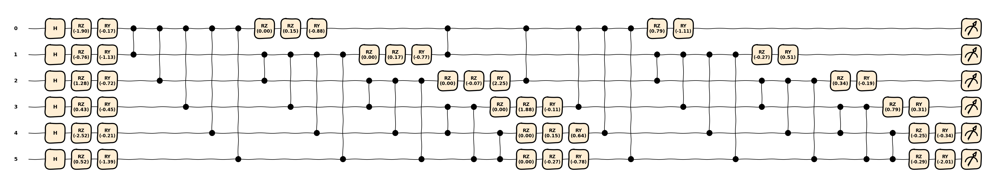

In [ ]:
n_qubits = 6
fm_config = {
    "features": 4,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.kokkos",
    "diff_method": "best",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=4,
    inputs=torch.zeros(4),
)


In [ ]:
agent = REINFORCE(
    policy=policy1,
    env_name="CartPole-v1",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    #normalize_mode="expand 10",
    normalize_mode="clip",
    normalize_returns=True,
    #entropy_coef=0.001,
    max_steps=200,
    baseline_type="ema",
    max_grad_norm=None,
)

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 21.3 | baseline = ema=13.0
Episode 0020 | avg(return_last20) = 19.9 | baseline = ema=11.4
Episode 0030 | avg(return_last20) = 18.6 | baseline = ema=10.5
Episode 0040 | avg(return_last20) = 24.6 | baseline = ema=11.9
Episode 0050 | avg(return_last20) = 45.6 | baseline = ema=16.7
Episode 0060 | avg(return_last20) = 61.8 | baseline = ema=20.2
Episode 0070 | avg(return_last20) = 61.2 | baseline = ema=21.7
Episode 0080 | avg(return_last20) = 73.6 | baseline = ema=26.0
Episode 0090 | avg(return_last20) = 107.0 | baseline = ema=32.0
Episode 0100 | avg(return_last20) = 121.5 | baseline = ema=35.6
Episode 0110 | avg(return_last20) = 113.5 | baseline = ema=36.4
Episode 0120 | avg(return_last20) = 122.5 | baseline = ema=39.4
Episode 0130 | avg(return_last20) = 141.8 | baseline = ema=42.8
Episode 0140 | avg(return_last20) = 149.2 | baseline = ema=44.6
Episode 0150 | avg(return_last20) = 169.7 | baseline = ema=49.1
Episode 0160 | avg(return_last20) = 184.4 | base

KeyboardInterrupt: 

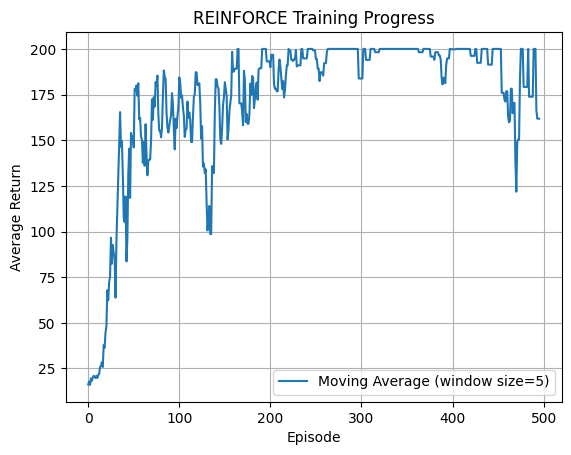

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()



In [1]:
from qasp import *
import qasp
import torch 
from pennylane import numpy as np
import matplotlib.pyplot as plt

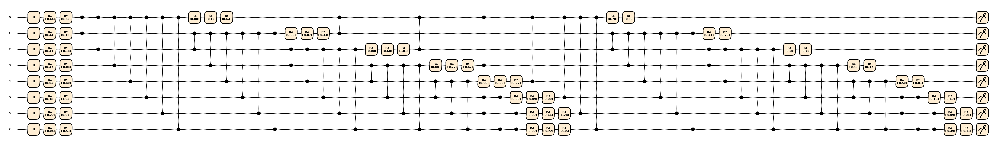

In [ ]:
n_qubits = 8
fm_config = {
    "features": 8,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    #"shots": 10000, #int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}


policy1 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy1,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=8,
    inputs=torch.zeros(8),
)


In [ ]:
#save parameters of the model to variables and copy 

for name, param in policy1.named_parameters():
    if name == "qlayer.params":
        p_copy = param.data.clone()
    elif name == "qlayer.input_scaling_params":
        s_copy = param.data.clone()

In [ ]:
print("Original parameters:")
print("p:", p_copy)
print("s:", s_copy)


Original parameters:
p: tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.0051, -0.1146])
s: tensor([ 7.0577e-01,  1.2353e-01,  5.9847e-01,  2.1106e-02, -4.5847e-01,
         2.2312e-01, -9.4125e-02, -5.4173e-01, -1.4879e-01, -6.0492e-01,
         3.7052e-02, -5.0882e-01,  1.2245e-01,  2.9244e-01,  5.0930e-01,
         3.8884e-01, -8.0083e-01, -3.0960e-01,  5.3245e-01, -5.6961e-02,
        -3.9287e-01, -2.2581e-01, -6.1854e-01, -1.0019e-01,  2.4218e-02,
        -3.2367e-01, -3.8567e-01, -8.1430e-01,  8.2724e-01, -4.0241e-01,
        -5.2858e-01,  8.5885e-01,  1.6700e-01, -1.5245

In [ ]:
agent = REINFORCE(
    policy=policy1,
    env_name="CartPole-v0",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    normalize_mode="expand 8",
    #normalize_mode="clip",
    normalize_returns=True,
    entropy_coef=0.001,
    max_grad_norm=None,
)

r = agent.train(num_episodes=500)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 15.2 | baseline = 16.3
Episode 0020 | avg(return_last20) = 18.9 | baseline = 18.7
Episode 0030 | avg(return_last20) = 23.3 | baseline = 20.4
Episode 0040 | avg(return_last20) = 24.1 | baseline = 22.1
Episode 0050 | avg(return_last20) = 26.0 | baseline = 23.9
Episode 0060 | avg(return_last20) = 28.6 | baseline = 25.5
Episode 0070 | avg(return_last20) = 27.8 | baseline = 25.4
Episode 0080 | avg(return_last20) = 31.1 | baseline = 29.5
Episode 0090 | avg(return_last20) = 41.4 | baseline = 36.0
Episode 0100 | avg(return_last20) = 49.8 | baseline = 43.7
Episode 0110 | avg(return_last20) = 88.4 | baseline = 75.3
Episode 0120 | avg(return_last20) = 130.8 | baseline = 100.9
Episode 0130 | avg(return_last20) = 137.0 | baseline = 114.2
Episode 0140 | avg(return_last20) = 134.0 | baseline = 123.2
Episode 0150 | avg(return_last20) = 124.5 | baseline = 120.1
Episode 0160 | avg(return_last20) = 128.9 | baseline = 128.5
Episode 0170 | avg(return_last20) = 144.8 | ba

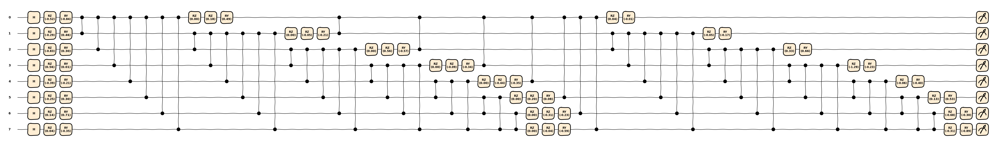

In [ ]:
n_qubits = 8
fm_config = {
    "features": 8,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "policy": "parity-like",
    "device": "lightning.qubit",
    "diff_method": "spsa",
    "spsa_num_directions": 2,
    "softmax_activation": False,
    "output_scaling": None,
    "training_method": "expectation",
    "torchrl": False,
    #"measurement_qubits": [0, 1, 2, 3],
    "shots": 5000, #int(n_qubits**(2)),
    "parity_cnot_decomposition": False,
}


policy2 = create_model("PQCBorn", policy_model_config, n_qubits=n_qubits)
fig, ax = draw_model(
    model=policy2,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=8,
    inputs=torch.zeros(8),
)


In [ ]:
#load parameters of the model from variables
print(p_copy)
policy2.qlayer.load_state_dict({"params": p_copy, "input_scaling_params": s_copy})
print("Model parameters after loading:")
for name, param in policy2.named_parameters():
    print(f"{name}: {param.data}")

tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.0051, -0.1146])
Model parameters after loading:
qlayer.input_scaling_params: tensor([ 7.0577e-01,  1.2353e-01,  5.9847e-01,  2.1106e-02, -4.5847e-01,
         2.2312e-01, -9.4125e-02, -5.4173e-01, -1.4879e-01, -6.0492e-01,
         3.7052e-02, -5.0882e-01,  1.2245e-01,  2.9244e-01,  5.0930e-01,
         3.8884e-01, -8.0083e-01, -3.0960e-01,  5.3245e-01, -5.6961e-02,
        -3.9287e-01, -2.2581e-01, -6.1854e-01, -1.0019e-01,  2.4218e-02,
        -3.2367e-01, -3.8567e-01, -8.1430e-01,  8.2724e-01, -4.0241e-01,
        -5.2858e-01,

In [ ]:
agent = REINFORCE(
    policy=policy2,
    env_name="CartPole-v0",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    normalize_mode="expand 8",
    #normalize_mode="clip",
    normalize_returns=True,
    entropy_coef=0.001,
    max_grad_norm=None,
)

r = agent.train(num_episodes=1000)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 16.8 | baseline = 15.3
Episode 0020 | avg(return_last20) = 16.4 | baseline = 15.6
Episode 0030 | avg(return_last20) = 19.1 | baseline = 18.1
Episode 0040 | avg(return_last20) = 24.5 | baseline = 21.9
Episode 0050 | avg(return_last20) = 23.7 | baseline = 21.4
Episode 0060 | avg(return_last20) = 21.7 | baseline = 21.8
Episode 0070 | avg(return_last20) = 24.1 | baseline = 23.5
Episode 0080 | avg(return_last20) = 25.2 | baseline = 23.8
Episode 0090 | avg(return_last20) = 26.4 | baseline = 25.5
Episode 0100 | avg(return_last20) = 25.8 | baseline = 24.9
Episode 0110 | avg(return_last20) = 23.6 | baseline = 24.4
Episode 0120 | avg(return_last20) = 22.1 | baseline = 23.2
Episode 0130 | avg(return_last20) = 20.4 | baseline = 22.1
Episode 0140 | avg(return_last20) = 21.1 | baseline = 22.1
Episode 0150 | avg(return_last20) = 25.1 | baseline = 24.6
Episode 0160 | avg(return_last20) = 26.9 | baseline = 24.8
Episode 0170 | avg(return_last20) = 25.8 | baseline = 24

KeyboardInterrupt: 

In [ ]:
n_qubits = 8
fm_config = {
    "features": 8,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
observables = [globalz,globalz2,zlast]

observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
for i in range(n_qubits-1):
    for j in range(i+1, n_qubits):
        observables.append("ZZ {} {}".format(i, j))

observables.append(globalz)

policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    #"spsa_num_directions": 10,
    "softmax_activation": False,
    "fc_layer":True,
    #"shots": 5000,
    "observables": observables
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

In [ ]:
#load parameters of the model from variables
print(p_copy)
pqc_softmax.qlayer.load_state_dict({"params": p_copy, "input_scaling_params": s_copy})
print("Model parameters after loading:")
print(pqc_softmax.get_weights()["params"])
print("Input scaling parameters after loading:")
print(pqc_softmax.get_weights()["input_scaling_params"])

tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.0051, -0.1146])
Model parameters after loading:
Parameter containing:
tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.

In [ ]:
agent = REINFORCE(
    policy=pqc_softmax,
    env_name="CartPole-v0",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=False,
    normalize_mode="expand 8",
    #normalize_mode="clip",
    normalize_returns=True,
    entropy_coef=0.001,
    max_grad_norm=None,
    fc_layer=True
)

r = agent.train(num_episodes=500)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 23.7 | baseline = 24.4
Episode 0020 | avg(return_last20) = 26.2 | baseline = 26.4
Episode 0030 | avg(return_last20) = 25.4 | baseline = 24.5
Episode 0040 | avg(return_last20) = 24.1 | baseline = 25.3
Episode 0050 | avg(return_last20) = 23.3 | baseline = 23.4
Episode 0060 | avg(return_last20) = 21.6 | baseline = 23.1
Episode 0070 | avg(return_last20) = 26.0 | baseline = 25.4
Episode 0080 | avg(return_last20) = 28.7 | baseline = 26.1
Episode 0090 | avg(return_last20) = 28.2 | baseline = 26.8
Episode 0100 | avg(return_last20) = 36.5 | baseline = 34.5
Episode 0110 | avg(return_last20) = 45.9 | baseline = 39.0
Episode 0120 | avg(return_last20) = 48.6 | baseline = 44.1
Episode 0130 | avg(return_last20) = 57.0 | baseline = 52.7
Episode 0140 | avg(return_last20) = 62.9 | baseline = 56.5
Episode 0150 | avg(return_last20) = 68.0 | baseline = 64.1
Episode 0160 | avg(return_last20) = 71.5 | baseline = 66.9
Episode 0170 | avg(return_last20) = 94.4 | baseline = 88

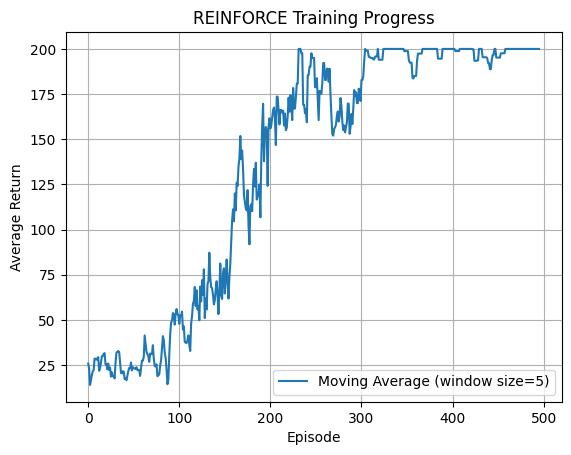

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size
))
plt.xlabel('Episode')   
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')
plt.legend()
plt.grid()
plt.show()

(<Figure size 6200x900 with 1 Axes>, <Axes: >)

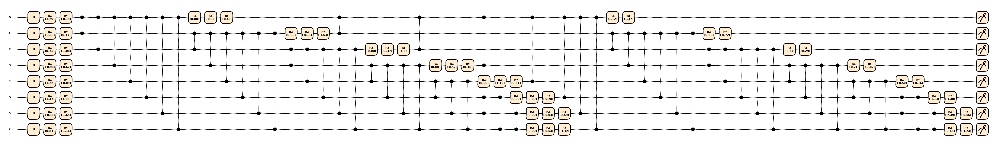

In [3]:
n_qubits = 8
fm_config = {
    "features": 8,
    "rotations": "Z",
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
observables = [globalz,globalz2,zlast]

observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
for i in range(n_qubits-1):
    for j in range(i+1, n_qubits):
        observables.append("ZZ {} {}".format(i, j))

observables.append(globalz)

policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2,
    "init": "normal_0_1",
    "device": "lightning.kokkos",
    "diff_method": "spsa",
    "spsa_num_directions": 2,
    "softmax_activation": False,
    "fc_layer":True,
    "shots": 2000,
    "observables": observables
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

draw_model(
    model=pqc_softmax,
    policy_class="PQCSoftmax",
    n_qubits=n_qubits,
    num_inputs=8,
    inputs=torch.zeros(8),
)

In [ ]:
#load parameters of the model from variables
print(p_copy)
pqc_softmax.qlayer.load_state_dict({"params": p_copy, "input_scaling_params": s_copy})
print("Model parameters after loading:")
print(pqc_softmax.get_weights()["params"])
print("Input scaling parameters after loading:")
print(pqc_softmax.get_weights()["input_scaling_params"])

tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.0051, -0.1146])
Model parameters after loading:
Parameter containing:
tensor([-0.6432,  0.4404,  0.4069,  0.4660,  0.0485,  0.1809, -0.1967, -0.0400,
         0.2516,  0.1554, -0.1756, -0.0782, -0.3987,  1.0538,  0.0650, -0.5252,
        -0.1175, -0.0747,  0.6004, -0.7746,  0.3311, -0.0870,  0.6580, -0.2174,
         0.6351, -0.3347,  1.0054, -0.4733,  0.2652,  0.0032,  1.2798,  0.3493,
         0.7800,  0.4106, -0.5006, -0.5750, -0.5035,  0.1820, -0.0885, -0.4900,
        -0.5014,  0.7261, -0.4642,  0.1716, -0.0097,  0.4018,  0.

In [ ]:
agent = REINFORCE(
    policy=pqc_softmax,
    env_name="CartPole-v0",
    gamma=0.99,
    lr=1e-1,
    batch_episodes=10,
    logits=False,
    normalize_mode="expand 8",
    #normalize_mode="clip",
    normalize_returns=True,
    entropy_coef=0.001,
    max_grad_norm=None,
    fc_layer=True
)

r = agent.train(num_episodes=1000)

Episode 0010 | avg(return_last20) = 25.2 | baseline = 16.7
Episode 0020 | avg(return_last20) = 20.9 | baseline = 16.8
Episode 0030 | avg(return_last20) = 18.9 | baseline = 18.8
Episode 0040 | avg(return_last20) = 21.1 | baseline = 19.9
Episode 0050 | avg(return_last20) = 19.6 | baseline = 19.2
Episode 0060 | avg(return_last20) = 19.0 | baseline = 19.4
Episode 0070 | avg(return_last20) = 21.9 | baseline = 20.9
Episode 0080 | avg(return_last20) = 24.3 | baseline = 22.4
Episode 0090 | avg(return_last20) = 26.4 | baseline = 24.5
Episode 0100 | avg(return_last20) = 28.2 | baseline = 26.4
Episode 0110 | avg(return_last20) = 27.3 | baseline = 26.4
Episode 0120 | avg(return_last20) = 27.9 | baseline = 27.3
Episode 0130 | avg(return_last20) = 27.4 | baseline = 26.1
Episode 0140 | avg(return_last20) = 26.6 | baseline = 26.7
Episode 0150 | avg(return_last20) = 26.8 | baseline = 26.2
Episode 0160 | avg(return_last20) = 21.9 | baseline = 23.1
Episode 0170 | avg(return_last20) = 19.1 | baseline = 21

#### Training for Acrobot


In [ ]:
from qasp import *
import qasp
import torch 
from pennylane import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [5]:
from itertools import combinations
def z_string(wires):
    """
    Convert a list of wires into your QASP observable string format.

    Example:
        wires = [0, 1, 3]
        returns "ZZZ 0 1 3"
    """
    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)

def xor_product_wires(list_of_wire_sets):
    """
    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.
    This returns the symmetric difference of all wire sets.
    """
    counts = {}

    for wires in list_of_wire_sets:
        for w in wires:
            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]
    return sorted(product_wires)

def build_parity_observables(n_qubits, n_action_bits):

    """

    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    For |A|=16, n_action_bits=4.

    We define the base parity generators:

        A = Z0 Z1 ... Z_{n-1}

        B = Z0 Z1 ... Z_{n-2}

        C = Z0 Z1 ... Z_{n-3}

        D = Z0 Z1 ... Z_{n-4}

    Then generate all products:

        A, B, C, D,

        AB, AC, AD, BC, BD, CD,

        ABC, ABD, ACD, BCD,

        ABCD.

    Returns:

        observable_labels: list[str]

        observable_wires: list[list[int]]

        observables: list[str]

        subsets: list[tuple[int]]

    """

    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    # A has n wires, B has n-1 wires, C has n-2 wires, ...

    base_wires = [

        list(range(n_qubits - i))

        for i in range(n_action_bits)

    ]

    observable_labels = []

    observable_wires = []

    observables = []

    subsets = []

    for r in range(1, n_action_bits + 1):

        for subset in combinations(range(n_action_bits), r):

            label = "".join(base_labels[i] for i in subset)

            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)

            observable_wires.append(wires)

            observables.append(z_string(wires))

            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets


observable_labels, observable_wires, observables_parity, subsets = build_parity_observables(n_qubits=6, n_action_bits=3)

print("Observable:", observables_parity)

Observable: ['ZZZZZZ 0 1 2 3 4 5', 'ZZZZZ 0 1 2 3 4', 'ZZZZ 0 1 2 3', 'Z 5', 'ZZ 4 5', 'Z 4', 'ZZZZZ 0 1 2 3 5']


(<Figure size 2900x700 with 1 Axes>, <Axes: >)

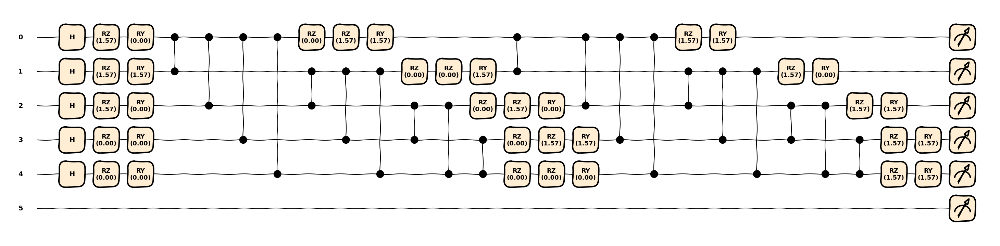

In [8]:
n_qubits = 5
fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
observables = [globalz,globalz2,zlast]

observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
#for i in range(n_qubits-1):
#   for j in range(i+1, n_qubits):
#        observables.append("ZZ {} {}".format(i, j))

#observables.append(globalz)

policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "discrete_0_pi_over_2",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    #"diff_method": "spsa",
    #"spsa_num_directions": 4,
    "softmax_activation": False,
    "fc_layer":True,
    #"shots": 10000,
    "observables": observables_parity
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

 

draw_model(model=pqc_softmax, policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

In [9]:
#print model parameters
for name, param in pqc_softmax.named_parameters():
    print(f"{name}: {param.data}")
    

fc_layer.weight: tensor([[-0.7718,  0.7078, -1.8161, -0.7003,  1.0494,  0.1005, -0.9065],
        [ 0.8910, -1.1701,  1.7981, -1.4010,  0.8039,  0.2140,  0.2240]])
fc_layer.bias: tensor([0., 0.])
qlayer.input_scaling_params: tensor([1.5708, 0.0000, 0.0000, 1.5708, 1.5708, 1.5708, 0.0000, 0.0000, 0.0000,
        1.5708, 1.5708, 0.0000, 1.5708, 1.5708, 1.5708, 1.5708, 0.0000, 1.5708,
        1.5708, 1.5708, 0.0000, 1.5708, 1.5708, 1.5708, 1.5708, 1.5708, 1.5708,
        1.5708, 0.0000, 0.0000, 1.5708, 1.5708, 1.5708, 0.0000, 1.5708, 1.5708,
        1.5708, 0.0000, 0.0000, 0.0000, 1.5708, 1.5708, 0.0000, 0.0000, 0.0000,
        0.0000, 1.5708, 1.5708, 1.5708, 1.5708, 1.5708, 0.0000, 0.0000, 0.0000,
        1.5708, 0.0000, 1.5708, 1.5708, 0.0000, 1.5708])
qlayer.params: tensor([1.5708, 1.5708, 1.5708, 0.0000, 0.0000, 0.0000, 1.5708, 0.0000, 0.0000,
        0.0000, 1.5708, 0.0000, 1.5708, 1.5708, 0.0000, 1.5708, 1.5708, 0.0000,
        1.5708, 0.0000, 1.5708, 1.5708, 1.5708, 1.5708, 1.5708,

In [ ]:
agent = REINFORCE(
        policy=pqc_softmax,
        #env_name="Acrobot-v1",
        env_name="CartPole-v0",
        gamma=0.99,
        lr=0.1,                 # variational + input-scaling lr (fc head is fixed at 1e-2 inside)
        max_steps=500,
        batch_episodes=4,        # PQC gradients are noisy -> larger batch
        logits=True,
        normalize_mode="clip",    # features land in ~[-1,1], velocities clipped to [-3,3]
        acrobot_use_angles=False, # raw 6D cos/sin rep (smooth, no wraparound)
        normalize_returns=True,
        #entropy_coef=0.02,
        baseline_type="ema",    # state-dependent baseline (now correct after the squeeze fix)
        #baseline_type="value", 
        baseline_lr=1e-2,
        #use_reward_shaping=True, 
        use_reward_shaping=False, 
        shaping_mode="dense",
        shaping_coef=0.5,
        max_grad_norm=1.0,
        fc_layer=True,            # tells REINFORCE to build the split-lr optimiser
    )

r = agent.train(num_episodes=500)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:519: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 21.4 | baseline = ema=16.9
Episode 0020 | avg(return_last20) = 22.8 | baseline = ema=14.7
Episode 0030 | avg(return_last20) = 23.8 | baseline = ema=13.3
Episode 0040 | avg(return_last20) = 25.4 | baseline = ema=13.1
Episode 0050 | avg(return_last20) = 27.8 | baseline = ema=13.1
Episode 0060 | avg(return_last20) = 39.2 | baseline = ema=16.5
Episode 0070 | avg(return_last20) = 66.0 | baseline = ema=22.5
Episode 0080 | avg(return_last20) = 91.5 | baseline = ema=27.6
Episode 0090 | avg(return_last20) = 125.2 | baseline = ema=35.6
Episode 0100 | avg(return_last20) = 152.4 | baseline = ema=40.3
Episode 0110 | avg(return_last20) = 164.2 | baseline = ema=44.6
Episode 0120 | avg(return_last20) = 166.9 | baseline = ema=46.4
Episode 0130 | avg(return_last20) = 172.9 | baseline = ema=49.1
Episode 0140 | avg(return_last20) = 185.9 | baseline = ema=51.3
Episode 0150 | avg(return_last20) = 182.2 | baseline = ema=51.8
Episode 0160 | avg(return_last20) = 142.4 | base

In [ ]:
agent = REINFORCE(
        policy=pqc_softmax,
        #env_name="Acrobot-v1",
        env_name="CartPole-v1",
        gamma=0.99,
        lr=0.1,                 # variational + input-scaling lr (fc head is fixed at 1e-2 inside)
        max_steps=200,
        batch_episodes=4,        # PQC gradients are noisy -> larger batch
        logits=True,
        normalize_mode="clip",    # features land in ~[-1,1], velocities clipped to [-3,3]
        acrobot_use_angles=False, # raw 6D cos/sin rep (smooth, no wraparound)
        normalize_returns=True,
        #entropy_coef=0.02,
        baseline_type="ema",    # state-dependent baseline (now correct after the squeeze fix)
        #baseline_type="value", 
        baseline_lr=1e-2,
        use_reward_shaping=False, 
        #use_reward_shaping=False, 
        shaping_mode="dense",
        shaping_coef=0.5,
        max_grad_norm=1.0,
        fc_layer=True,            # tells REINFORCE to build the split-lr optimiser
    )

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 28.4 | baseline = ema=15.4
Episode 0020 | avg(return_last20) = 23.7 | baseline = ema=13.0
Episode 0030 | avg(return_last20) = 21.1 | baseline = ema=12.3
Episode 0040 | avg(return_last20) = 21.6 | baseline = ema=11.2
Episode 0050 | avg(return_last20) = 22.9 | baseline = ema=11.5
Episode 0060 | avg(return_last20) = 20.9 | baseline = ema=10.2
Episode 0070 | avg(return_last20) = 15.2 | baseline = ema=9.0
Episode 0080 | avg(return_last20) = 21.4 | baseline = ema=10.7
Episode 0090 | avg(return_last20) = 24.3 | baseline = ema=10.4
Episode 0100 | avg(return_last20) = 17.7 | baseline = ema=9.4
Episode 0110 | avg(return_last20) = 17.1 | baseline = ema=9.3
Episode 0120 | avg(return_last20) = 17.8 | baseline = ema=9.1
Episode 0130 | avg(return_last20) = 17.9 | baseline = ema=9.3
Episode 0140 | avg(return_last20) = 21.8 | baseline = ema=10.1
Episode 0150 | avg(return_last20) = 25.2 | baseline = ema=10.9
Episode 0160 | avg(return_last20) = 28.1 | baseline = ema=12

KeyboardInterrupt: 

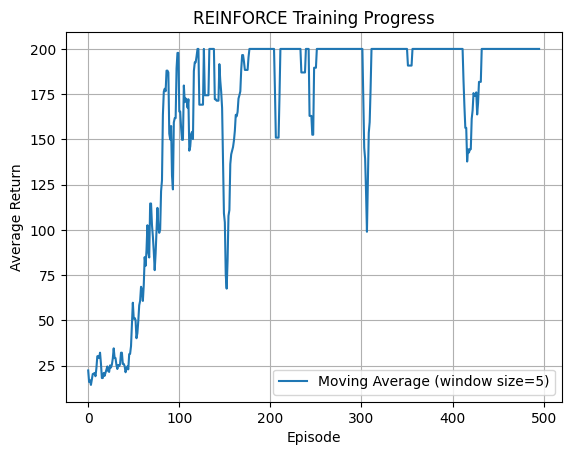

In [ ]:
#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size
))
plt.xlabel('Episode')   
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')
plt.legend()
plt.grid()
plt.show()

In [ ]:
import torch
import torch.nn as nn


class MLPPolicy(nn.Module):
    def __init__(self, input_dim: int, n_actions: int, hidden_dim: int = 64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, hidden_dim),
            nn.Tanh(),
            nn.Linear(hidden_dim, n_actions),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:

        return self.net(x)

In [ ]:
mlp_policy = MLPPolicy(input_dim=6, n_actions=3, hidden_dim=64)

agent = REINFORCE(
    policy=mlp_policy,
    env_name="Acrobot-v1",
    gamma=0.99,
    lr=1e-3,
    batch_episodes=10,
    logits=True,
    normalize_mode=None,
    acrobot_use_angles=False,
    baseline_type="value",
    baseline_hidden_dim=64,
    baseline_lr=1e-2,
    baseline_updates_per_batch=10,
    normalize_returns=True,
    use_reward_shaping=True,   # tip-height potential shaping
    shaping_coef=0.5,
    shaping_mode="dense",
    entropy_coef=0.001,
    max_grad_norm=1.0,
    fc_layer=False,
)

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = -490.3 | baseline = value_loss=20511.5977, value_mean=-7.0
Episode 0020 | avg(return_last20) = -482.5 | baseline = value_loss=16739.3125, value_mean=-13.6
Episode 0030 | avg(return_last20) = -442.1 | baseline = value_loss=12508.6045, value_mean=-20.5
Episode 0040 | avg(return_last20) = -368.4 | baseline = value_loss=10247.7637, value_mean=-27.3
Episode 0050 | avg(return_last20) = -304.9 | baseline = value_loss=7298.0269, value_mean=-33.9
Episode 0060 | avg(return_last20) = -263.4 | baseline = value_loss=5483.0234, value_mean=-40.5
Episode 0070 | avg(return_last20) = -242.6 | baseline = value_loss=4584.5015, value_mean=-46.6
Episode 0080 | avg(return_last20) = -222.3 | baseline = value_loss=3753.0308, value_mean=-51.6
Episode 0090 | avg(return_last20) = -209.3 | baseline = value_loss=3122.9065, value_mean=-57.1
Episode 0100 | avg(return_last20) = -202.5 | baseline = value_loss=2401.5886, value_mean=-57.3
Episode 0110 | avg(return_last20) = -186.4 | ba

KeyboardInterrupt: 

In [1]:
import qasp 
from qasp import * 
import torch 
import matplotlib.pyplot as plt

Number of observables: 12
['Z 0', 'Z 1', 'Z 2', 'Z 3', 'Z 4', 'Z 5', 'ZZ 0 1', 'ZZ 1 2', 'ZZ 2 3', 'ZZ 3 4', 'ZZ 4 5', 'ZZ 5 0']


(<Figure size 4000x700 with 1 Axes>, <Axes: >)

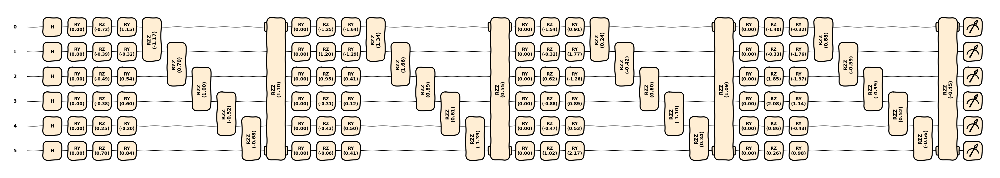

In [3]:
# ============================================================
# Acrobot-v1 uses six default observations:
#
# [cos(theta_1), sin(theta_1),
#  cos(theta_2), sin(theta_2),
#  theta_dot_1, theta_dot_2]
# ============================================================

n_qubits = 6
n_actions = 3


# ============================================================
# Feature map
# ============================================================

fm_config = {
    "features": 6,

    # One data-dependent rotation per feature is a good
    # initial choice. "YZ" can be tested later if needed.
    "rotations": "Y",

    # Trainable feature scaling can adapt the relative
    # frequency assigned to each Acrobot observation.
    #"input_scaling": True,
}


# ============================================================
# Variational circuit
# ============================================================

ansatz_config = {
    # A moderate depth is preferable for policy-gradient
    # training. Start at 3 rather than 5.
    "n_layers": 4,

    # Per layer:
    #   - local Z rotations
    #   - local Y rotations
    #   - nearest-neighbour parameterized ZZ rotations
    "rotations": (
        [f"Z {i}" for i in range(n_qubits)]
        + [f"Y {i}" for i in range(n_qubits)]
        + [
            f"ZZ {i} {(i + 1) % n_qubits}"
            for i in range(n_qubits)
        ]
    ),

    # Re-upload the six-dimensional Acrobot state.
    "reuploading": True,

    # Entanglement is already introduced by the parameterized
    # ZZ rotations, so an additional fixed entangler is not
    # initially necessary.
    "include_imprimitive": False,
    "imprimitive": "CZ",
    "imprimitive_pattern": "ring",

    "include_final_imprimitive": False,

    # Encode the state before the first variational block.
    "include_feature_map_first": True,

    "include_hadamards_initial": True,
}


# ============================================================
# Local measurement features
# ============================================================

observables = []

# Six one-local observables
observables.extend(
    f"Z {i}"
    for i in range(n_qubits)
)

# Six nearest-neighbour two-local observables on a ring
observables.extend(
    f"ZZ {i} {(i + 1) % n_qubits}"
    for i in range(n_qubits)
)

print(f"Number of observables: {len(observables)}")
print(observables)

policy_model_config = {
    "ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,

    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,

    "n_actions": n_actions,

    # Much safer than N(0, 1) for policy-gradient training.
    "init": "normal_0_1",

    "device": "default.qubit",
    "diff_method": "backprop",
    "training_method": "probs",

    # Return unnormalized action logits.
    "softmax_activation": False,

    # Map the 12 quantum features to 3 action logits.
    #"fc_layer": True,

    #"observables": observables,
    "measurement_qubits": list(range(n_qubits)), #lambda n: [i for i in range(int(np.log2(n)))],

}


pqc_softmax = create_model(
    "PQCBorn",
    policy_model_config,
    n_qubits=n_qubits,
)


draw_model(
    model=pqc_softmax,
    policy_class="PQCBorn",
    n_qubits=n_qubits,
    num_inputs=6,
    inputs=torch.zeros(6),
)

In [8]:
print(pqc_softmax.qlayer.input_scaling_params) 

print("PQC Softmax  nn linear parameters:")
print(pqc_softmax.fc_layer.state_dict())

Parameter containing:
tensor([ 0.2125, -1.3020,  2.5784,  0.7463, -1.0579, -0.5561,  1.3115,  0.5125,
        -1.0079,  1.3513,  1.0990, -0.6919,  0.0147,  0.1452, -0.4343, -0.8900,
        -0.8322, -1.8130, -0.0482, -0.6699,  0.3792, -0.1929,  1.7829,  1.7487,
        -0.8941, -0.7555, -0.5636,  0.8032,  0.3896, -0.9309, -1.5604,  0.3381,
         2.7312, -1.9788,  1.7663, -1.6613, -0.0470,  0.4667,  1.1548, -1.4084,
         1.3165, -1.3805,  0.5749,  1.6232, -0.0911,  0.1191, -0.3334,  1.0085],
       requires_grad=True)
PQC Softmax  nn linear parameters:
OrderedDict([('weight', tensor([[ 0.1615,  0.0280,  0.0878,  0.0628,  0.1109,  0.0464,  0.1718,  0.0338,
         -0.0500,  0.0390, -0.0903,  0.0292],
        [-0.2093, -0.0063, -0.1318, -0.0776, -0.0319, -0.0152, -0.0821, -0.2533,
          0.0426,  0.0278, -0.1093, -0.1187],
        [ 0.1375,  0.0232,  0.3434,  0.0999,  0.1208, -0.0952,  0.1242, -0.2967,
          0.1028, -0.1353, -0.0205,  0.1693]])), ('bias', tensor([-0.1419,  

In [5]:
agent = REINFORCE(
    policy=pqc_softmax,
    env_name="Acrobot-v1",

    max_steps=500,
    gamma=0.99,

    # 0.09 is very aggressive for this hybrid model.
    lr=0.01,

    # Larger batches reduce policy-gradient variance.
    batch_episodes=10,

    # The policy returns raw logits because
    # softmax_activation=False.
    logits=True,

    # Use the six standard Acrobot observations.
    acrobot_use_angles=False,

    normalize_mode="clip",

    baseline_type="ema",
    normalize_returns=True,

    # Preserve exploration during the early phase.
    entropy_coef=0.003,

    max_grad_norm=1.0,

    fc_layer=False,
)


returns = agent.train(
    num_episodes=500,
)

Episode 0010 | avg(return_last20) = -500.0 | baseline = ema=-80.3


KeyboardInterrupt: 

In [8]:
agent = REINFORCE(
    policy=pqc_softmax,
    env_name="CartPole-v1",
    max_steps=200,
    gamma=0.99,
    lr=1e-1,
    batch_episodes=5,
    logits=True,
    normalize_mode="clip", #"expand 8",
    #normalize_mode="clip",
    baseline_type="ema",
    normalize_returns=True,
    entropy_coef=0.0,
    max_grad_norm=None,
    fc_layer=True
)

r = agent.train(num_episodes=500)

Episode 0010 | avg(return_last20) = 25.2 | baseline = ema=9.3
Episode 0020 | avg(return_last20) = 36.5 | baseline = ema=14.0
Episode 0030 | avg(return_last20) = 52.9 | baseline = ema=17.8
Episode 0040 | avg(return_last20) = 73.2 | baseline = ema=23.5
Episode 0050 | avg(return_last20) = 137.5 | baseline = ema=36.1
Episode 0060 | avg(return_last20) = 189.5 | baseline = ema=44.1
Episode 0070 | avg(return_last20) = 181.9 | baseline = ema=47.1
Episode 0080 | avg(return_last20) = 175.8 | baseline = ema=49.8
Episode 0090 | avg(return_last20) = 189.3 | baseline = ema=52.6
Episode 0100 | avg(return_last20) = 197.4 | baseline = ema=54.2
Episode 0110 | avg(return_last20) = 191.3 | baseline = ema=54.5
Episode 0120 | avg(return_last20) = 193.1 | baseline = ema=55.6
Episode 0130 | avg(return_last20) = 200.0 | baseline = ema=56.2
Episode 0140 | avg(return_last20) = 200.0 | baseline = ema=56.6
Episode 0150 | avg(return_last20) = 200.0 | baseline = ema=56.8
Episode 0160 | avg(return_last20) = 183.2 | b

KeyboardInterrupt: 

### lightning.kokkos vs lightning.pp

In [1]:
from qasp import *
import torch
import qasp 
from pennylane import numpy as np

In [ ]:
from itertools import combinations
def z_string(wires):
    """
    Convert a list of wires into your QASP observable string format.

    Example:
        wires = [0, 1, 3]
        returns "ZZZ 0 1 3"
    """
    return "Z" * len(wires) + " " + " ".join(str(w) for w in wires)

def xor_product_wires(list_of_wire_sets):
    """
    Product of Pauli-Z strings.

    Since Z_i * Z_i = I, repeated wires cancel mod 2.
    This returns the symmetric difference of all wire sets.
    """
    counts = {}

    for wires in list_of_wire_sets:
        for w in wires:
            counts[w] = counts.get(w, 0) + 1

    product_wires = [w for w, c in counts.items() if c % 2 == 1]
    return sorted(product_wires)

def build_parity_observables(n_qubits, n_action_bits):

    """

    Build all nontrivial parity-product observables for |A| = 2^n_action_bits.

    For |A|=16, n_action_bits=4.

    We define the base parity generators:

        A = Z0 Z1 ... Z_{n-1}

        B = Z0 Z1 ... Z_{n-2}

        C = Z0 Z1 ... Z_{n-3}

        D = Z0 Z1 ... Z_{n-4}

    Then generate all products:

        A, B, C, D,

        AB, AC, AD, BC, BD, CD,

        ABC, ABD, ACD, BCD,

        ABCD.

    Returns:

        observable_labels: list[str]

        observable_wires: list[list[int]]

        observables: list[str]

        subsets: list[tuple[int]]

    """

    base_labels = [chr(ord("A") + i) for i in range(n_action_bits)]

    # A has n wires, B has n-1 wires, C has n-2 wires, ...

    base_wires = [

        list(range(n_qubits - i))

        for i in range(n_action_bits)

    ]

    observable_labels = []

    observable_wires = []

    observables = []

    subsets = []

    for r in range(1, n_action_bits + 1):

        for subset in combinations(range(n_action_bits), r):

            label = "".join(base_labels[i] for i in subset)

            wires = xor_product_wires([base_wires[i] for i in subset])

            observable_labels.append(label)

            observable_wires.append(wires)

            observables.append(z_string(wires))

            subsets.append(subset)

    return observable_labels, observable_wires, observables, subsets


observable_labels, observable_wires, observables_parity, subsets = build_parity_observables(n_qubits=6, n_action_bits=3)

print("Observable:", observables_parity)

In [53]:
n_qubits = 20
fm_config = {
    "features": 4,
    "rotations": "Z",
}

observable_labels, observable_wires, observables_parity, subsets = build_parity_observables(n_qubits=n_qubits, n_action_bits=6)

print("Observable:", observables_parity)
ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
print(globalz)
observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
#for i in range(0,n_qubits-1,2):
#for i in range(n_qubits-1):
#    observables.append("ZZ {} {}".format(i, i+1))

print(observables)
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "small_normal",
    "device": "lightning.pp",
    "diff_method": "adjoint",
    #"spsa_num_directions": 10,
    #"softmax_activation": False,
    "fc_layer":True,
    #"shots": 5000,
    "observables": observables_parity,
    "pp_truncation": 4,  # for 5% error and probability set k in np.log2((0.05)**(-1) * (0.05)**(-1)) Theorem 2 Rudolph et al (2024),
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

#draw_model(model=pqc_softmax, policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

Observable: ['ZZZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19', 'ZZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18', 'ZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17', 'ZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16', 'ZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15', 'ZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14', 'Z 19', 'ZZ 18 19', 'ZZZ 17 18 19', 'ZZZZ 16 17 18 19', 'ZZZZZ 15 16 17 18 19', 'Z 18', 'ZZ 17 18', 'ZZZ 16 17 18', 'ZZZZ 15 16 17 18', 'Z 17', 'ZZ 16 17', 'ZZZ 15 16 17', 'Z 16', 'ZZ 15 16', 'Z 15', 'ZZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 19', 'ZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 19', 'ZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 19', 'ZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 19', 'ZZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 18 19', 'ZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 18 19', 'ZZZZZZZZZZ

In [54]:
n_qubits = 20
fm_config = {
    "features": 4,
    "rotations": "Z",
}

observable_labels, observable_wires, observables_parity, subsets = build_parity_observables(n_qubits=n_qubits, n_action_bits=6)

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY",#["Y {}".format(i) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
print(globalz)
observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
#for i in range(0,n_qubits-1,2):
#for i in range(n_qubits-1):
#    observables.append("ZZ {} {}".format(i, i+1))

print(observables)
policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 4,
    "init": "small_normal",
    "device": "lightning.kokkos",
    "diff_method": "adjoint",
    #"spsa_num_directions": 10,
    #"softmax_activation": False,
    "fc_layer":True,
    #"shots": 5000,
    "observables": observables_parity
}



pqc_softmax_2 = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

#draw_model(model=pqc_softmax, policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

ZZZZZZZZZZZZZZZZZZZZ 0 1 2 3 4 5 6 7 8 9 10 11 12 13 14 15 16 17 18 19
['Z 0', 'Z 1', 'Z 2', 'Z 3', 'Z 4', 'Z 5', 'Z 6', 'Z 7', 'Z 8', 'Z 9', 'Z 10', 'Z 11', 'Z 12', 'Z 13', 'Z 14', 'Z 15', 'Z 16', 'Z 17', 'Z 18', 'Z 19']


In [55]:
#load pqc_softmax parameters into pqc_softmax_2
pqc_softmax_2.qlayer.load_state_dict(pqc_softmax.qlayer.state_dict())
pqc_softmax_2.fc_layer.load_state_dict(pqc_softmax.fc_layer.state_dict())

<All keys matched successfully>

In [56]:
#calculate total variation distance between policy and policy2
state = torch.randn(1, 4)
p1 = pqc_softmax(state)
p2 = pqc_softmax_2(state)
print("Policy output:", p1)
print("Policy2 output:", p2)

tv_distance = 0.5 * torch.sum(torch.abs(p1 - p2))
print("Total variation distance between policy and policy2:", tv_distance.item())

Policy output: tensor([-0.3033, -0.4583,  0.1115,  0.4787], grad_fn=<ViewBackward0>)
Policy2 output: tensor([-0.0148, -0.3423,  0.0488,  0.4198], grad_fn=<ViewBackward0>)
Total variation distance between policy and policy2: 0.26300865411758423


### Test contextual bandit 

In [1]:
from qasp.rl.torchrl import ContextualBanditEnv
import qasp
from qasp import *
import torch
import matplotlib.pyplot as plt

In [3]:
env = ContextualBanditEnv(
    n_features=6,
    n_actions=20,
    n_contexts=100,
    seed=123,
    reward_mode="dense_normalized",
    base_reward_scale=10.0,
    optimal_reward_bonus=2.0,
    reward_shift=0,
    temperature=1.0,
)


In [3]:
env.reset()

env.get_oracle_value()

12.0

In [4]:
env.render()

Current context index: 5
Current context: [ 0.83424515  0.7293805  -0.56371427  0.73225486  0.46150386 -0.44426942]
Action probabilities: [0.18683015 0.51264036 0.53344625 0.26286286 0.63674504 0.2631313
 0.81499946 0.6192262  0.01813093 0.07774543 0.08737879 0.53778476
 0.5533937  0.46142486 0.03354393 0.31823924 0.6724075  0.15341434
 0.7286751  0.24183288]
Optimal action(s): [6] | best probability: 0.8149994611740112
Oracle value: 12.0
Reward bounds: (0.0, 12.0)


In [12]:
env.save("bandit_env_6f_20a_100c.npz")

In [4]:
env.load("bandit_env_6f_20a_100c.npz")

In [4]:
from qasp import * 


(<Figure size 3000x600 with 1 Axes>, <Axes: >)

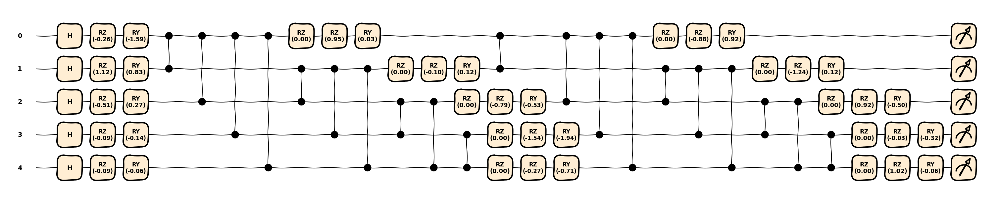

In [ ]:
n_qubits = 5
fm_config = {
    "features": 6,
    "rotations": "Z", # Rz (feature 0 ) |0> Rz(feature 1) |0>  ... 
}

#observable_labels, observable_wires, observables_parity, subsets = build_parity_observables(n_qubits=6, n_action_bits=5)

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY", #Ry (theta0 ) Rz(theta 1) |0>  \otimes Ry (theta2 ) Rz(theta3) |0>   
    #"rotations" : ["Y 0" , "X 2" , "YY 0 1"]

    "reuploading": True,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}


observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
#for i in range(n_qubits-1):
#    observables.append("ZZ {} {}".format(i, i+1))

observables = ["Z 1" , "Z 3" , "ZZ 0 1"]
#observables.append(globalz)

policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 20,
    "init": "normal_0_1",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    #"spsa_num_directions": 10,
    #"softmax_activation": False,
    "fc_layer":True,
    #"shots": 5000,
    "observables": observables
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

draw_model(model=pqc_softmax, policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=6, inputs=torch.zeros(6))

In [13]:
agent = REINFORCE(
    policy=pqc_softmax,
    env_name=env,
    max_steps=1,
    gamma=1.0,
    lr=1e-1,
    batch_episodes=30,
    logits=True,
    #normalize_mode="expand 8",
    normalize_mode=None,
    baseline_type="ema",
    normalize_returns=True,
    entropy_coef=0.01,
    max_grad_norm=1.0,
    fc_layer=True
)

r = agent.train(num_episodes=5000)

Episode 0010 | avg(return_last20) = 5.4 | baseline = ema=7.9
Episode 0020 | avg(return_last20) = 4.6 | baseline = ema=6.3
Episode 0030 | avg(return_last20) = 5.2 | baseline = ema=6.5
Episode 0040 | avg(return_last20) = 5.7 | baseline = ema=5.8


Episode 0050 | avg(return_last20) = 4.8 | baseline = ema=5.4
Episode 0060 | avg(return_last20) = 5.2 | baseline = ema=5.4
Episode 0070 | avg(return_last20) = 5.0 | baseline = ema=4.9
Episode 0080 | avg(return_last20) = 4.6 | baseline = ema=4.9
Episode 0090 | avg(return_last20) = 5.3 | baseline = ema=5.2
Episode 0100 | avg(return_last20) = 5.1 | baseline = ema=5.0
Episode 0110 | avg(return_last20) = 5.0 | baseline = ema=5.1
Episode 0120 | avg(return_last20) = 5.6 | baseline = ema=5.5
Episode 0130 | avg(return_last20) = 5.0 | baseline = ema=5.0
Episode 0140 | avg(return_last20) = 4.4 | baseline = ema=4.7
Episode 0150 | avg(return_last20) = 4.5 | baseline = ema=4.6
Episode 0160 | avg(return_last20) = 5.7 | baseline = ema=5.5
Episode 0170 | avg(return_last20) = 6.4 | baseline = ema=5.6
Episode 0180 | avg(return_last20) = 5.9 | baseline = ema=5.7
Episode 0190 | avg(return_last20) = 5.3 | baseline = ema=5.3
Episode 0200 | avg(return_last20) = 3.6 | baseline = ema=4.2
Episode 0210 | avg(retur

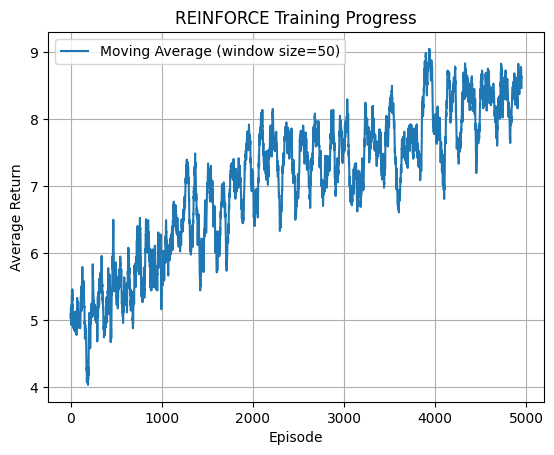

In [14]:
window_size = 50

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size))
plt.xlabel('Episode')
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')

plt.legend()
plt.grid()
plt.show()


(<Figure size 2900x600 with 1 Axes>, <Axes: >)

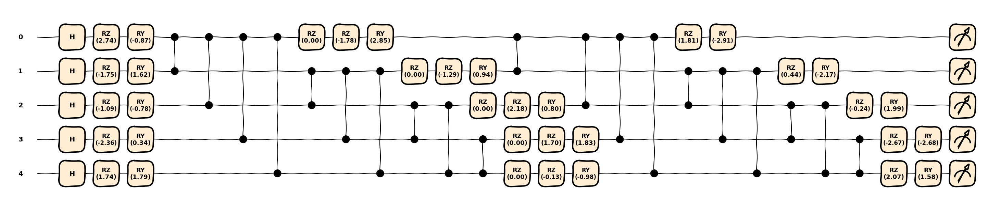

In [2]:
n_qubits = 5
fm_config = {
    "features": 4,
    "rotations": "Z",
    #"input_scaling": True
}

ansatz_config = {
    "n_layers": 3,
    "rotations" : "ZY", #["ZZ {} {}".format(i,(i+1)%n_qubits) for i in range(n_qubits)]+["Z {}".format(i) for i in range(n_qubits)]+["Y {}".format(i) for i in range(n_qubits)],
    "reuploading": False,
    "include_imprimitive": True,
    "imprimitive": "CZ",
    "imprimitive_pattern": "all_to_all",
    "include_final_imprimitive": False,
    "include_feature_map_first": False,
    "include_hadamards_initial": True
}
globalz = "Z"*n_qubits+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits))))
globalz2 = "Z"*(n_qubits-1)+" {}".format(" ".join(str(wire) for wire in list(range(n_qubits-1))))
zlast = "Z {}".format(n_qubits-1)
observables = [globalz,globalz2,zlast]

observables = []
#add all 1-local Z observables
for i in range(n_qubits):
    observables.append("Z {}".format(i))
#add all 2-local ZZ observables
#for i in range(n_qubits-1):
#   for j in range(i+1, n_qubits):
#        observables.append("ZZ {} {}".format(i, j))

#observables.append(globalz)

policy_model_config_softmax = {
"ansatz": "AngleAnsatz",
    "ansatz_config": ansatz_config,
    "feature_map": "NeuralEmbedding",
    "feature_map_config": fm_config,
    "n_actions": 2 ,
    "init": "random_-pi_pi",
    "device": "lightning.qubit",
    "diff_method": "adjoint",
    #"diff_method": "spsa",
    #"spsa_num_directions": 4,
    "softmax_activation": False,
    "fc_layer":True,
    #"shots": 10000,
    "observables": observables
}



pqc_softmax = create_model("PQCSoftmax", policy_model_config_softmax, n_qubits=n_qubits)

 

draw_model(model=pqc_softmax, policy_class="PQCSoftmax", n_qubits=n_qubits, num_inputs=4, inputs=torch.zeros(4))

In [3]:
#print model parameters
for name, param in pqc_softmax.named_parameters():
    print(f"{name}: {param.data}")
    

fc_layer.weight: tensor([[-5.,  5., -5.,  5.,  5.],
        [ 5.,  5.,  5., -5., -5.]])
fc_layer.bias: tensor([0., 0.])
qlayer.input_scaling_params: tensor([ 2.4942,  1.6009, -0.8067, -1.4070,  0.9136, -2.4630,  0.9169,  2.5870,
         0.6317,  0.3357, -1.6261, -1.3897, -2.8431, -3.0140, -0.6371,  2.0077,
        -2.6743, -0.8877,  0.9050,  2.3174,  2.2803,  1.1557,  1.4838, -1.6681,
         1.0666, -0.7104, -0.0307,  1.5888,  0.9582, -3.0169,  0.4031,  0.3556,
         0.3930, -2.1218,  2.8760,  2.6302, -2.9359,  1.3806,  1.7595, -1.9961,
        -2.3860,  1.0962, -2.6551,  1.1558,  0.3741,  0.5777, -2.8664, -2.3600,
         2.3490, -2.4646,  0.8168,  1.6896,  0.1631, -0.2348, -2.3686,  0.2988,
         0.4860,  0.1351,  0.8742, -2.0642])
qlayer.params: tensor([ 2.7396, -1.7509, -1.0940, -2.3610,  1.7367, -0.8680,  1.6222, -0.7776,
         0.3360,  1.7882, -1.7845, -1.2942,  2.1823,  1.7009, -0.1334,  2.8460,
         0.9386,  0.8018,  1.8337, -0.9827,  1.8121,  0.4381, -0.2397, 

In [5]:
agent = REINFORCE(
        policy=pqc_softmax,
        #env_name="Acrobot-v1",
        env_name="CartPole-v0",
        gamma=0.99,
        lr=0.1,                 # variational + input-scaling lr (fc head is fixed at 1e-2 inside)
        max_steps=500,
        batch_episodes=4,        # PQC gradients are noisy -> larger batch
        logits=True,
        normalize_mode="clip",    # features land in ~[-1,1], velocities clipped to [-3,3]
        acrobot_use_angles=False, # raw 6D cos/sin rep (smooth, no wraparound)
        normalize_returns=True,
        #entropy_coef=0.02,
        baseline_type="ema",    # state-dependent baseline (now correct after the squeeze fix)
        #baseline_type="value", 
        baseline_lr=1e-2,
        #use_reward_shaping=True, 
        use_reward_shaping=False, 
        shaping_mode="dense",
        shaping_coef=0.5,
        max_grad_norm=1.0,
        fc_layer=True,            # tells REINFORCE to build the split-lr optimiser
    )

r = agent.train(num_episodes=500)

/opt/homebrew/Caskroom/miniforge/base/envs/torchlane/lib/python3.10/site-packages/gymnasium/envs/registration.py:517: DeprecationWarning: WARN: The environment CartPole-v0 is out of date. You should consider upgrading to version `v1`.
  logger.deprecation(


Episode 0010 | avg(return_last20) = 20.8 | baseline = ema=10.3
Episode 0020 | avg(return_last20) = 20.8 | baseline = ema=10.3
Episode 0030 | avg(return_last20) = 25.2 | baseline = ema=11.7
Episode 0040 | avg(return_last20) = 33.5 | baseline = ema=13.9
Episode 0050 | avg(return_last20) = 38.9 | baseline = ema=15.4
Episode 0060 | avg(return_last20) = 39.0 | baseline = ema=15.9
Episode 0070 | avg(return_last20) = 39.1 | baseline = ema=16.9
Episode 0080 | avg(return_last20) = 44.5 | baseline = ema=18.6
Episode 0090 | avg(return_last20) = 49.6 | baseline = ema=19.9
Episode 0100 | avg(return_last20) = 58.0 | baseline = ema=22.2
Episode 0110 | avg(return_last20) = 76.2 | baseline = ema=26.2
Episode 0120 | avg(return_last20) = 85.8 | baseline = ema=28.6
Episode 0130 | avg(return_last20) = 95.5 | baseline = ema=32.5
Episode 0140 | avg(return_last20) = 131.0 | baseline = ema=39.4
Episode 0150 | avg(return_last20) = 160.8 | baseline = ema=44.2
Episode 0160 | avg(return_last20) = 147.8 | baseline 

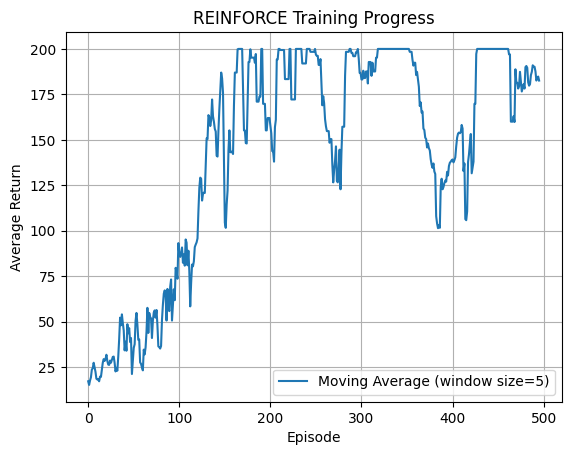

In [7]:
import numpy as np

#plot moving average of episode returns
window_size = 5

moving_avg = np.convolve(r, np.ones(window_size)/window_size
, mode='valid')
plt.plot(moving_avg, label='Moving Average (window size={})'.format(window_size
))
plt.xlabel('Episode')   
plt.ylabel('Average Return')
plt.title('REINFORCE Training Progress')
plt.legend()
plt.grid()
plt.show()